# Predicción de severidad de accidentes de tránsito para la gestión de siniestros de aseguradoras

**Universidad Panamericana · Fundamentos de Ciencia de Datos · Proyecto final, otoño 2026**
Equipo 3: Humberto Ángel Plata Durán, Diego Hernández Ortiz y Christopher Leo Magaña. Docente: Ernesto Pérez Vázquez.

Este notebook implementa la propuesta del documento *ProyectoEQ3_Ciencia_Datos_Accidentes_CDMX* siguiendo CRISP-DM. Con la estadística ATUS del INEGI (Ciudad de México, 2019–2025) se estima la probabilidad de que un accidente sea **S0** (sólo daños), **S1** (con lesionados) o **S2** (fatal), usando únicamente información disponible en el primer aviso del siniestro, y se traduce esa probabilidad en prioridades de atención y en la distribución de ajustadores.

| Sección | Fase CRISP-DM | Apartado del documento |
|---|---|---|
| 0. Configuración | — | — |
| 1. Entendimiento del negocio | Business Understanding | 1.4, 2, 4, 7.1 |
| 2. Carga y calidad de datos | Data Understanding | 6.1, 7.2 |
| 3. Análisis exploratorio | Data Understanding / analítica descriptiva | 6.2, 7.2, 8 |
| 4. Preparación de datos | Data Preparation | 3.1, 6.3, 7.3 |
| 5. Modelado y experimento COVID-19 | Modeling | 4, 6.2, 7.4 |
| 6. Calibración y reglas de prioridad | Evaluation / analítica prescriptiva | 6.3, 10 |
| 7. Prueba final 2025 e hipótesis | Evaluation | 4, 7.5, 14 |
| 8. Explicabilidad (SHAP) | Evaluation | 1.3 |
| 9. Carga esperada y distribución de ajustadores | Analítica predictiva y prescriptiva | 9, 10 |
| 10. Valor de negocio | Evaluation | 13 |
| 11. Despliegue del MVP | Deployment | 7.6, 11 |
| 12. Resumen de resultados | — | 14, 15 |

**Requisitos:** Python 3.10+, `pandas`, `numpy`, `scikit-learn`, `xgboost`, `shap`, `matplotlib`, `seaborn`, `scipy`, `joblib` y `flask`. El zip de datos abiertos de ATUS (serie anual 1997–2025) debe estar en `data/ATUSDatasetINEGI.zip`. No es necesario descomprimirlo.

**Regla de oro del experimento:** el año 2025 sólo se abre en la sección 7. Nada de lo que se decide antes (variables, hiperparámetros, calibración, umbrales o elección de modelo) usa información de 2025.

## 0. Configuración

In [1]:
# Si falta alguna librería, descomenta la siguiente línea y reinicia el kernel:
# %pip install xgboost shap scikit-learn pandas numpy matplotlib seaborn scipy joblib flask

from pathlib import Path
import sys, json, time, zipfile, warnings, importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import chi2_contingency
import joblib
import sklearn
import xgboost
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_recall_fscore_support, f1_score, confusion_matrix,
                             average_precision_score, roc_auc_score, log_loss,
                             precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED = 42

# ---------------- Datos ----------------
CANDIDATOS_ZIP = [Path("data/ATUSDatasetINEGI.zip"), Path("../data/ATUSDatasetINEGI.zip"), Path("ATUSDatasetINEGI.zip")]
DATA_ZIP = next((p for p in CANDIDATOS_ZIP if p.exists()), CANDIDATOS_ZIP[0])
SHAPEFILE_ALCALDIAS = Path("data/09mun.shp")   # Opcional: Marco Geoestadístico del INEGI (sección 3.4)
ANIOS = list(range(2019, 2026))
CVE_ENT_CDMX = "09"

# ---------------- Diseño experimental (sección 6.2 del documento) ----------------
VENTANAS = {"A": list(range(2019, 2024)), "B": [2022, 2023]}
NOMBRE_VENTANA = {"A": "A: 2019-2023 (con pandemia)", "B": "B: 2022-2023 (pospandemia)"}
ANIO_VAL, ANIO_TEST = 2024, 2025
INICIO_COVID, FIN_COVID = pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31")
FIN_EMERGENCIA_OMS = pd.Timestamp("2023-05-05")
PERIODOS = ["Pre-COVID (ene 2019-feb 2020)", "COVID (mar 2020-dic 2021)", "Pos-COVID (2022-2025)"]

CLASES = ["S0", "S1", "S2"]
Y_MAP = {c: i for i, c in enumerate(CLASES)}
NOMBRE_CLASE = {"S0": "S0 Daños materiales", "S1": "S1 Con lesionados", "S2": "S2 Fatal"}
COLOR = {"S0": "#8A9BA8", "S1": "#E0A100", "S2": "#B3261E"}
COLOR_COMBO = {("A", "LogReg"): "#9DB4D3", ("B", "LogReg"): "#3F6EA8", ("A", "XGBoost"): "#F2B8A2", ("B", "XGBoost"): "#C4452A"}

# ---------------- Salidas ----------------
DIR_FIG, DIR_ART = Path("figuras"), Path("artefactos")
for d in (DIR_FIG, DIR_ART):
    d.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False})

def guardar(fig, nombre):
    """Guarda cada figura en figuras/ para usarla en el reporte escrito."""
    fig.savefig(DIR_FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")

def formato_pct(ax, eje="y", decimales=0):
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(mtick.PercentFormatter(1.0, decimals=decimales))

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")
print(f"Datos: {DATA_ZIP.resolve()} (existe: {DATA_ZIP.exists()})")

pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1
Datos: /Users/humbertoangelplataduran/Documents/proyecto-final-data-science/data/ATUSDatasetINEGI.zip (existe: True)


### 0.1 Funciones compartidas con la API

La construcción de variables, la etiqueta, la calibración y las reglas de prioridad se escriben en un módulo (`artefactos/severidad_features.py`). El notebook y la API de la sección 11 importan exactamente el mismo código, de modo que el pipeline de entrenamiento y el de producción no pueden divergir.

In [2]:
%%writefile artefactos/severidad_features.py
"""Funciones compartidas entre el notebook y la API de severidad (Equipo 3, UP).

Contiene: etiqueta S0/S1/S2, variables disponibles en el primer aviso, preprocesador,
calibración multiclase, reglas de prioridad, validación de reportes y el objeto
ModeloSeveridad que se serializa en modelo_champion.pkl.
"""
import unicodedata

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CLASES = ["S0", "S1", "S2"]
PRIORIDADES = ["Baja", "Media", "Alta"]

ALCALDIAS = {
    "09002": "Azcapotzalco", "09003": "Coyoacán", "09004": "Cuajimalpa de Morelos",
    "09005": "Gustavo A. Madero", "09006": "Iztacalco", "09007": "Iztapalapa",
    "09008": "La Magdalena Contreras", "09009": "Milpa Alta", "09010": "Álvaro Obregón",
    "09011": "Tláhuac", "09012": "Tlalpan", "09013": "Xochimilco", "09014": "Benito Juárez",
    "09015": "Cuauhtémoc", "09016": "Miguel Hidalgo", "09017": "Venustiano Carranza",
}

VICTIMAS_HERIDAS = ["CONDHERIDO", "PASAHERIDO", "PEATHERIDO", "CICLHERIDO", "OTROHERIDO", "NEHERIDO"]
VICTIMAS_MUERTAS = ["CONDMUERTO", "PASAMUERTO", "PEATMUERTO", "CICLMUERTO", "OTROMUERTO", "NEMUERTO"]

GRUPOS_VEHICULO = {
    "N_AUTOS": ["AUTOMOVIL", "CAMPASAJ"],
    "N_TRANSP_PUBLICO": ["MICROBUS", "PASCAMION", "OMNIBUS", "TRANVIA"],
    "N_CARGA": ["CAMIONETA", "CAMION", "TRACTOR"],
    "N_MOTO": ["MOTOCICLET"],
    "N_BICI": ["BICICLETA"],
    "N_OTRO": ["OTROVEHIC", "FERROCARRI"],
}
VEHICULOS = [c for grupo in GRUPOS_VEHICULO.values() for c in grupo]

DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
TIPOS_ACCIDENTE = [
    "Colisión con vehículo automotor", "Colisión con peatón (atropellamiento)", "Colisión con animal",
    "Colisión con objeto fijo", "Volcadura", "Caída de pasajero", "Salida del camino", "Incendio",
    "Colisión con ferrocarril", "Colisión con motocicleta", "Colisión con ciclista", "Otro",
]
UBICACIONES = {"Accidente en intersección": "Intersección", "Accidente en no intersección": "No intersección"}
FRANJAS = ["Madrugada (0-5)", "Mañana (6-11)", "Tarde (12-17)", "Noche (18-23)"]

FEATURES_CAT = ["MES", "DIASEMANA", "FRANJA", "ALCALDIA", "TIPACCID", "UBICACION"]
FEATURES_NUM = ["HORA_SIN", "HORA_COS", "FIN_SEMANA", "NVEH", *GRUPOS_VEHICULO,
                "HAY_MOTO", "HAY_BICI", "HAY_TRANSP_PUBLICO", "HAY_CARGA_PESADA", "UN_VEHICULO"]


# ----------------------------------------------------------------------------- etiqueta
def construir_objetivo(df):
    """S2 si hay al menos un fallecido en el lugar; S1 si hay heridos y ningún fallecido; S0 en otro caso."""
    heridos = df[VICTIMAS_HERIDAS].apply(pd.to_numeric, errors="coerce").clip(lower=0).sum(axis=1)
    muertos = df[VICTIMAS_MUERTAS].apply(pd.to_numeric, errors="coerce").clip(lower=0).sum(axis=1)
    return pd.Series(np.select([muertos >= 1, heridos >= 1], ["S2", "S1"], "S0"), index=df.index, name="SEVERIDAD")


# ----------------------------------------------------------------------------- variables
def _sin_acentos(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in texto if not unicodedata.combining(c)).strip().lower()

_ALCALDIA_POR_TEXTO = {_sin_acentos(v): v for v in ALCALDIAS.values()}
_ALCALDIA_POR_TEXTO.update({k: v for k, v in ALCALDIAS.items()})

def normalizar_alcaldia(valor):
    """Acepta CVEGEO ('09007'), nombre con o sin acentos ('Iztapalapa', 'alvaro obregon')."""
    if valor is None:
        return None
    v = str(valor).strip()
    if v in ALCALDIAS:
        return ALCALDIAS[v]
    return _ALCALDIA_POR_TEXTO.get(_sin_acentos(v))

def franja_horaria(hora):
    etiquetas = pd.cut(hora, [-1, 5, 11, 17, 23], labels=FRANJAS)
    return etiquetas.astype(object).where(etiquetas.notna(), "No especificada").astype(str)

def construir_features(df):
    """Variables observables en el primer aviso del siniestro (Etapa 1).

    Funciona con registros ATUS (usa CVEGEO) o con reportes de la API (usa ALCALDIA).
    """
    X = pd.DataFrame(index=df.index)
    hora = pd.to_numeric(df["ID_HORA"], errors="coerce")
    hora = hora.where(hora.between(0, 23))
    X["MES"] = pd.to_numeric(df["MES"], errors="coerce").fillna(0).astype(int).astype(str)
    dia = df["DIASEMANA"].astype(str)
    X["DIASEMANA"] = dia.where(dia.isin(DIAS), "No especificado")
    X["FIN_SEMANA"] = dia.isin(["Sábado", "Domingo"]).astype(int)
    X["FRANJA"] = franja_horaria(hora)
    X["HORA_SIN"] = np.sin(2 * np.pi * hora.fillna(12) / 24)
    X["HORA_COS"] = np.cos(2 * np.pi * hora.fillna(12) / 24)
    if "ALCALDIA" in df.columns:
        alcaldia = df["ALCALDIA"].map(normalizar_alcaldia)
    else:
        alcaldia = df["CVEGEO"].astype(str).str.zfill(5).map(ALCALDIAS)
    X["ALCALDIA"] = alcaldia.fillna("Desconocida").astype(str)
    X["TIPACCID"] = df["TIPACCID"].astype(str)
    X["UBICACION"] = df["URBANA"].map(UBICACIONES).fillna("Suburbana u otra").astype(str)

    veh = pd.DataFrame({c: (pd.to_numeric(df[c], errors="coerce").fillna(0).clip(lower=0)
                            if c in df.columns else 0) for c in VEHICULOS}, index=df.index)
    for grupo, cols in GRUPOS_VEHICULO.items():
        X[grupo] = veh[cols].sum(axis=1)
    X["NVEH"] = veh.sum(axis=1)
    X["HAY_MOTO"] = (X["N_MOTO"] > 0).astype(int)
    X["HAY_BICI"] = (X["N_BICI"] > 0).astype(int)
    X["HAY_TRANSP_PUBLICO"] = (X["N_TRANSP_PUBLICO"] > 0).astype(int)
    X["HAY_CARGA_PESADA"] = ((veh["CAMION"] + veh["TRACTOR"]) > 0).astype(int)
    X["UN_VEHICULO"] = (X["NVEH"] == 1).astype(int)
    return X[FEATURES_CAT + FEATURES_NUM]

def crear_preprocesador():
    """One-hot para categóricas (categorías con < 30 casos se agrupan) y estandarización de numéricas."""
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), FEATURES_CAT),
         ("num", StandardScaler(), FEATURES_NUM)],
        verbose_feature_names_out=False,
    )


# ----------------------------------------------------------------------------- modelo
class ClasificadorSeveridad:
    """Preprocesador ajustado + estimador. predict_proba recibe registros crudos (ATUS o API)."""
    def __init__(self, preprocesador, modelo, nombre=""):
        self.preprocesador, self.modelo, self.nombre = preprocesador, modelo, nombre

    def transformar(self, df):
        return self.preprocesador.transform(construir_features(df))

    def predict_proba(self, df):
        return self.modelo.predict_proba(self.transformar(df))


class CalibradorMultinomial:
    """Escalamiento de Platt multiclase: regresión logística sobre log-probabilidades.

    Corrige el sesgo que introducen los pesos por clase (que inflan S1 y S2) para que
    P(S0), P(S1) y P(S2) puedan leerse como probabilidades.
    """
    def __init__(self, C=10.0):
        self.C = C

    @staticmethod
    def _z(P):
        return np.log(np.clip(np.asarray(P, dtype=float), 1e-6, 1.0))

    def fit(self, P, y):
        self.lr_ = LogisticRegression(C=self.C, max_iter=5000).fit(self._z(P), y)
        return self

    def transform(self, P):
        return self.lr_.predict_proba(self._z(P))


def score_severidad(P):
    """SSE = P(S1) + 2 P(S2); score 0-100 = 50 * SSE (sección 6.3)."""
    P = np.asarray(P)
    return 50 * (P[:, 1] + 2 * P[:, 2])

def asignar_prioridad(P, umbrales):
    P = np.asarray(P)
    score = score_severidad(P)
    alta = (P[:, 2] >= umbrales["p_s2_alta"]) | (score >= umbrales["score_alta"])
    media = ~alta & (score >= umbrales["score_media"])
    return np.where(alta, "Alta", np.where(media, "Media", "Baja"))


class ModeloSeveridad:
    """Objeto champion que se despliega: clasificador + calibrador + umbrales de prioridad."""
    def __init__(self, clasificador, calibrador, umbrales, metadatos=None):
        self.clasificador, self.calibrador, self.umbrales = clasificador, calibrador, umbrales
        self.metadatos = metadatos or {}

    def probabilidades(self, df, calibradas=True):
        P = self.clasificador.predict_proba(df)
        return self.calibrador.transform(P) if calibradas and self.calibrador is not None else P

    def predecir(self, df):
        P_modelo = self.clasificador.predict_proba(df)
        P = self.calibrador.transform(P_modelo) if self.calibrador is not None else P_modelo
        salida = pd.DataFrame(P, columns=[f"P_{c}" for c in CLASES], index=df.index)
        salida["SSE"] = P[:, 1] + 2 * P[:, 2]
        salida["SCORE"] = score_severidad(P)
        salida["PRIORIDAD"] = asignar_prioridad(P, self.umbrales)
        salida["CLASE_PROBABLE"] = np.array(CLASES)[P_modelo.argmax(axis=1)]
        return salida


# ----------------------------------------------------------------------------- validación API
CAMPOS_REQUERIDOS = ["MES", "DIASEMANA", "ID_HORA", "ALCALDIA", "TIPACCID", "URBANA"]
_UBICACION_TEXTO = {**{k: k for k in UBICACIONES}, **{v: k for k, v in UBICACIONES.items()}}

def validar_reporte(registros):
    """Valida uno o varios reportes de primer aviso. Devuelve (DataFrame o None, lista de errores)."""
    if isinstance(registros, dict):
        registros = [registros]
    filas, errores = [], []
    for i, r in enumerate(registros):
        e = []
        faltan = [c for c in CAMPOS_REQUERIDOS if c not in r]
        if faltan:
            errores.append({"registro": i, "errores": [f"Faltan campos: {', '.join(faltan)}"]})
            continue
        fila = {}
        try:
            fila["MES"] = int(r["MES"]); assert 1 <= fila["MES"] <= 12
        except Exception:
            e.append("MES debe ser un entero entre 1 y 12")
        try:
            fila["ID_HORA"] = int(r["ID_HORA"]); assert 0 <= fila["ID_HORA"] <= 23
        except Exception:
            e.append("ID_HORA debe ser un entero entre 0 y 23")
        if r["DIASEMANA"] not in DIAS:
            e.append(f"DIASEMANA debe ser uno de {DIAS}")
        fila["DIASEMANA"] = r["DIASEMANA"]
        alcaldia = normalizar_alcaldia(r["ALCALDIA"])
        if alcaldia is None:
            e.append("ALCALDIA no reconocida (usa el nombre de la alcaldía o su CVEGEO)")
        fila["ALCALDIA"] = alcaldia
        if r["TIPACCID"] not in TIPOS_ACCIDENTE:
            e.append(f"TIPACCID debe ser uno de {TIPOS_ACCIDENTE}")
        fila["TIPACCID"] = r["TIPACCID"]
        if r["URBANA"] not in _UBICACION_TEXTO:
            e.append("URBANA debe ser 'Intersección' o 'No intersección'")
        fila["URBANA"] = _UBICACION_TEXTO.get(r["URBANA"])
        total = 0
        for c in VEHICULOS:
            try:
                fila[c] = int(r.get(c, 0)); assert 0 <= fila[c] <= 9
                total += fila[c]
            except Exception:
                e.append(f"{c} debe ser un entero entre 0 y 9")
        if total == 0:
            e.append("El reporte debe incluir al menos un vehículo")
        if e:
            errores.append({"registro": i, "errores": e})
        else:
            filas.append(fila)
    return (pd.DataFrame(filas) if not errores else None), errores

Writing artefactos/severidad_features.py


In [3]:
if str(DIR_ART.resolve()) not in sys.path:
    sys.path.insert(0, str(DIR_ART.resolve()))
import severidad_features as sf
importlib.reload(sf)
print("Variables del modelo:", len(sf.FEATURES_CAT), "categóricas y", len(sf.FEATURES_NUM), "numéricas")

Variables del modelo: 6 categóricas y 15 numéricas


## 1. Entendimiento del negocio

**Cliente:** aseguradora de automóviles con red de ajustadores (modelo InsurTech B2B). **Usuario:** centro de atención de siniestros y supervisores de ajuste.

**Pregunta de negocio:** ¿qué nivel de severidad es probable para un accidente, usando sólo lo que se sabe en el primer aviso, y cómo usar esa estimación para priorizar casos y distribuir ajustadores?

**Hipótesis (sección 4):**

- **H0 / H1:** las variables del primer aviso no contienen / sí contienen señal suficiente para superar fuera de muestra a un baseline basado en la distribución histórica de clases.
- **H0_modelo / H1_modelo:** XGBoost no mejora / sí mejora de forma estadística y operacionalmente relevante a la Regresión Logística multinomial.
- **Experimento COVID-19:** ¿generaliza distinto un modelo entrenado con 2019–2023 (ventana A) que uno entrenado sólo con 2022–2023 (ventana B)?

Los parámetros de negocio de la siguiente celda son supuestos académicos editables. Ninguno usa costos reales de una aseguradora; deben sustituirse por datos del cliente en un piloto.

In [4]:
# Matriz de costos relativos del error de priorización (filas = severidad real, columnas = prioridad asignada).
# Unidades relativas: 1 = costo de enviar a un ajustador con prioridad media a un caso que no la requería.
PRIORIDADES = ["Baja", "Media", "Alta"]
COSTO_ERROR = pd.DataFrame([[0.0, 1.0, 2.0],    # S0: prioridad alta innecesaria satura ajustadores
                            [4.0, 1.0, 0.5],    # S1: subpriorizar un caso con lesionados
                            [20.0, 8.0, 0.0]],  # S2: subpriorizar un caso fatal es el error más caro
                           index=CLASES, columns=PRIORIDADES)
CAPACIDAD_ALTA = 0.15          # Proporción máxima de casos que la operación puede atender como prioridad alta
MEJORA_MINIMA_F1 = 0.01        # Mejora mínima en Macro F1 para justificar XGBoost sobre la Regresión Logística
N_BOOT = 1000                  # Remuestreos bootstrap para intervalos de confianza
N_BUSQUEDA_XGB = 12            # Configuraciones de hiperparámetros por ventana

# Sección 13: escenarios económicos (supuestos ilustrativos)
COSTO_BASE_B = 20_000_000                                  # MXN/año de despacho y ajuste
ESCENARIOS_EFICIENCIA = {"Conservador": 0.03, "Base": 0.05, "Alto": 0.08}
COSTO_ANUAL_SOLUCION = 500_000                             # MXN/año (supuesto, licencia + operación)
REASIGNACIONES_EVITADAS, COSTO_REASIGNACION = 0, 0         # Sustituir con datos del piloto
COSTO_UNIDAD_ERROR_MXN = None                              # Valor en MXN de 1 unidad de costo relativo (por validar)

# Sección 9-10: simulación de distribución de ajustadores (supuestos ilustrativos)
SIM_VOLUMEN_DIARIO = 250               # Siniestros diarios de la aseguradora en CDMX
SIM_AJUSTADORES_POR_FRANJA = 40        # Ajustadores activos en cada franja de 6 horas
SIM_CASOS_POR_AJUSTADOR = 1.5          # Casos que un ajustador puede atender por franja en su zona
SIM_MINIMO_POR_ALCALDIA = 1
SIM_DIAS = 365
PESO_SEVERIDAD = np.array([1.0, 2.0, 3.0])   # Peso de S0, S1, S2 para la carga ponderada

display(COSTO_ERROR)

,Baja,Media,Alta
S0,0.0000,1.0000,2.0000
S1,4.0000,1.0000,0.5000
S2,20.0000,8.0000,0.0000


## 2. Carga y calidad de los datos

Se leen los CSV anuales 2019–2025 directamente del zip, por bloques, conservando sólo Ciudad de México. Antes de concatenar se homologan los nombres que cambiaron en la publicación de julio de 2026 (`ID_ENTIDAD` → `CVE_ENT`, `ID_MUNICIPIO` → `CVE_MUN`), como pide la sección 6.1.

In [5]:
RENOMBRES = {"ID_ENTIDAD": "CVE_ENT", "ID_MUNICIPIO": "CVE_MUN"}

def leer_atus(ruta_zip, anios, cve_ent, chunksize=100_000):
    partes, resumen = [], []
    with zipfile.ZipFile(ruta_zip) as zf:
        nombres = zf.namelist()
        for anio in anios:
            nombre = next(n for n in nombres if n.endswith(f"atus_anual_{anio}.csv"))
            total, cdmx, columnas = 0, 0, None
            with zf.open(nombre) as f:
                for bloque in pd.read_csv(f, dtype=str, encoding="utf-8", chunksize=chunksize):
                    bloque = bloque.rename(columns=RENOMBRES)
                    columnas = columnas or list(bloque.columns)
                    sel = bloque[bloque["CVE_ENT"].str.zfill(2) == cve_ent]
                    total += len(bloque); cdmx += len(sel)
                    partes.append(sel)
            resumen.append({"ANIO": anio, "registros_nacionales": total, "registros_CDMX": cdmx,
                            "n_columnas": len(columnas), "columnas": tuple(columnas)})
            print(f"{anio}: {total:>8,} nacionales | {cdmx:>6,} CDMX")
        catalogo = pd.read_csv(zf.open(next(n for n in nombres if n.endswith("tc_municipio.csv"))), dtype=str)
    return pd.concat(partes, ignore_index=True), pd.DataFrame(resumen), catalogo

t0 = time.time()
crudo, resumen_carga, catalogo_mun = leer_atus(DATA_ZIP, ANIOS, CVE_ENT_CDMX)
print(f"\n{len(crudo):,} accidentes en CDMX 2019-2025, {crudo.shape[1]} columnas ({time.time() - t0:.0f} s)")
mismas = resumen_carga["columnas"].nunique() == 1
print("Mismas columnas y en el mismo orden en todos los años:", mismas)
resumen_carga["% CDMX"] = resumen_carga["registros_CDMX"] / resumen_carga["registros_nacionales"]
display(resumen_carga.drop(columns="columnas"))

2019:  362,729 nacionales | 10,673 CDMX
2020:  301,678 nacionales |  6,549 CDMX
2021:  340,415 nacionales |  6,743 CDMX
2022:  377,231 nacionales |  7,596 CDMX
2023:  381,048 nacionales |  7,276 CDMX
2024:  374,949 nacionales |  6,655 CDMX
2025:  380,391 nacionales |  5,276 CDMX

50,768 accidentes en CDMX 2019-2025, 46 columnas (8 s)
Mismas columnas y en el mismo orden en todos los años: True


,ANIO,registros_nacionales,registros_CDMX,n_columnas,% CDMX
0,2019,362729,10673,46,0.0294
1,2020,301678,6549,46,0.0217
2,2021,340415,6743,46,0.0198
3,2022,377231,7596,46,0.0201
4,2023,381048,7276,46,0.0191
5,2024,374949,6655,46,0.0177
6,2025,380391,5276,46,0.0139


In [6]:
NUMERICAS = ["ANIO", "MES", "ID_HORA", "ID_MINUTO", "ID_DIA", "ID_EDAD",
             *sf.VEHICULOS, *sf.VICTIMAS_HERIDAS, *sf.VICTIMAS_MUERTAS]
df = crudo.copy()
nulos = {}
for c in NUMERICAS:
    valores = pd.to_numeric(df[c], errors="coerce")
    nulos[c] = int(valores.isna().sum())
    df[c] = valores.fillna(-1).astype("int16")
df["CVEGEO"] = df["CVEGEO"].str.zfill(5)
df["ALCALDIA"] = df["CVEGEO"].map(sf.ALCALDIAS)

# Verificación del catálogo de alcaldías del módulo contra el catálogo oficial del zip
oficial = catalogo_mun[catalogo_mun["CVE_ENT"] == CVE_ENT_CDMX].set_index("CVEGEO")["NOM_MUNICIPIO"]
diferencias = {k: (v, oficial.get(k)) for k, v in sf.ALCALDIAS.items() if oficial.get(k) != v}
print("Diferencias con el catálogo oficial:", diferencias or "ninguna")
print("Registros sin alcaldía reconocida:", int(df["ALCALDIA"].isna().sum()))

dia_valido = df["ID_DIA"].between(1, 31)
df["FECHA"] = pd.to_datetime(pd.DataFrame({"year": df["ANIO"], "month": df["MES"],
                                           "day": df["ID_DIA"].where(dia_valido)}), errors="coerce")
df["MES_INICIO"] = pd.to_datetime(pd.DataFrame({"year": df["ANIO"], "month": df["MES"], "day": 1}))

inventario = pd.DataFrame({
    "tipo": [("numérica" if c in NUMERICAS else "categórica") for c in crudo.columns],
    "valores_distintos": [df[c].nunique() for c in crudo.columns],
    "nulos": [int(crudo[c].isna().sum()) for c in crudo.columns],
    "ejemplo": [crudo[c].iloc[0] for c in crudo.columns],
}, index=crudo.columns)
display(inventario)

Diferencias con el catálogo oficial: ninguna
Registros sin alcaldía reconocida: 0


,tipo,valores_distintos,nulos,ejemplo
COBERTURA,categórica,1,0,Municipal
CVEGEO,categórica,16,0,09002
CVE_ENT,categórica,1,0,09
CVE_MUN,categórica,16,0,002
ANIO,numérica,7,0,2019
MES,numérica,12,0,01
ID_HORA,numérica,24,0,19
ID_MINUTO,numérica,60,0,59
ID_DIA,numérica,32,0,01
DIASEMANA,categórica,8,0,Martes


In [7]:
dia_semana_fecha = df["FECHA"].dt.dayofweek.map(dict(enumerate(sf.DIAS)))
comparables = df["FECHA"].notna() & df["DIASEMANA"].isin(sf.DIAS)

codigos_no_respuesta = pd.Series({
    "Hora no especificada (99)": (df.ID_HORA == 99).mean(),
    "Minuto no especificado (99)": (df.ID_MINUTO == 99).mean(),
    "Día del mes no especificado (32)": (df.ID_DIA == 32).mean(),
    "Día de la semana no especificado": (df.DIASEMANA == "No especificado").mean(),
    "Edad del responsable: se fugó (0)": (df.ID_EDAD == 0).mean(),
    "Edad del responsable: se ignora (99)": (df.ID_EDAD == 99).mean(),
    "Sexo del responsable: se fugó": (df.SEXO == "Se fugó").mean(),
    "Aliento alcohólico: se ignora": (df.ALIENTO == "Se ignora").mean(),
    "Cinturón: se ignora": (df.CINTURON == "Se ignora").mean(),
}, name="% de registros")

valores_imposibles = pd.Series({
    "Nulos en columnas numéricas": sum(nulos.values()),
    "Hora fuera de 0-23 (sin contar 99)": int((~df.ID_HORA.between(0, 23) & (df.ID_HORA != 99)).sum()),
    "Minuto fuera de 0-59 (sin contar 99)": int((~df.ID_MINUTO.between(0, 59) & (df.ID_MINUTO != 99)).sum()),
    "Fecha inexistente (p. ej. 31 de febrero)": int((dia_valido & df.FECHA.isna()).sum()),
    "Día de la semana inconsistente con la fecha": int((comparables & (dia_semana_fecha != df.DIASEMANA)).sum()),
    "Edad fuera de 12-98 (sin contar 0 y 99)": int((~df.ID_EDAD.isin([0, 99]) & ~df.ID_EDAD.between(12, 98)).sum()),
    "Accidentes sin ningún vehículo": int((df[sf.VEHICULOS].sum(axis=1) == 0).sum()),
    "Registros duplicados exactos": int(crudo.duplicated().sum()),
}, name="registros")

display(codigos_no_respuesta.to_frame().style.format("{:.2%}"))
display(valores_imposibles.to_frame())
print("Nota: ATUS no tiene un identificador de accidente, así que los duplicados exactos pueden ser eventos\n"
      "distintos con los mismos atributos (misma hora redondeada, alcaldía y vehículos). Se conservan.")

,% de registros
Hora no especificada (99),0.00%
Minuto no especificado (99),0.00%
Día del mes no especificado (32),0.01%
Día de la semana no especificado,0.01%
Edad del responsable: se fugó (0),22.15%
Edad del responsable: se ignora (99),1.32%
Sexo del responsable: se fugó,22.15%
Aliento alcohólico: se ignora,40.84%
Cinturón: se ignora,44.33%


,registros
Nulos en columnas numéricas,0
Hora fuera de 0-23 (sin contar 99),0
Minuto fuera de 0-59 (sin contar 99),0
Fecha inexistente (p. ej. 31 de febrero),0
Día de la semana inconsistente con la fecha,0
Edad fuera de 12-98 (sin contar 0 y 99),0
Accidentes sin ningún vehículo,0
Registros duplicados exactos,136


Nota: ATUS no tiene un identificador de accidente, así que los duplicados exactos pueden ser eventos
distintos con los mismos atributos (misma hora redondeada, alcaldía y vehículos). Se conservan.


Categorías que no aparecen en todos los años (posibles cambios de codificación):


,variable,categoría,años en que aparece
0,DIASEMANA,No especificado,2023
1,SUBURBANA,Accidente en camino rural,"2023, 2024"
2,SUBURBANA,Accidente en carretera estatal,"2019, 2021, 2022, 2023, 2025"
3,SUBURBANA,Accidentes en otro camino,"2019, 2020, 2021, 2022, 2023"
4,TIPACCID,Colisión con animal,"2020, 2021, 2022, 2024"
5,TIPACCID,Incendio,"2019, 2023, 2025"


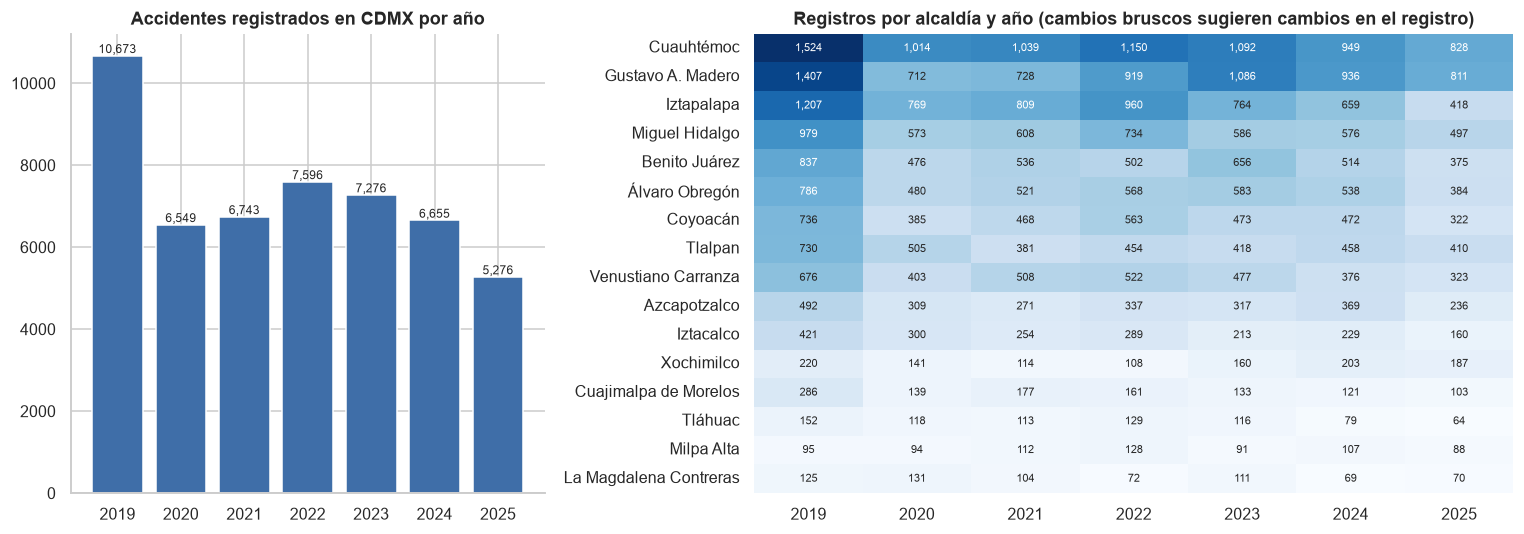

In [8]:
CATEGORICAS = ["DIASEMANA", "URBANA", "SUBURBANA", "TIPACCID", "CAUSAACCI", "CAPAROD",
               "SEXO", "ALIENTO", "CINTURON", "CLASACC", "ESTATUS"]
cambios = []
for c in CATEGORICAS:
    presencia = pd.crosstab(df[c], df["ANIO"]) > 0
    for categoria, fila in presencia[~presencia.all(axis=1)].iterrows():
        cambios.append({"variable": c, "categoría": categoria,
                        "años en que aparece": ", ".join(str(a) for a in fila.index[fila])})
print("Categorías que no aparecen en todos los años (posibles cambios de codificación):")
display(pd.DataFrame(cambios) if cambios else "Ninguna: la codificación es estable 2019-2025")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.bar(resumen_carga["ANIO"], resumen_carga["registros_CDMX"], color="#3F6EA8")
for x, v in zip(resumen_carga["ANIO"], resumen_carga["registros_CDMX"]):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax.set_title("Accidentes registrados en CDMX por año"); ax.set_xlabel("")
por_alcaldia = pd.crosstab(df["ALCALDIA"], df["ANIO"])
por_alcaldia = por_alcaldia.loc[por_alcaldia.sum(axis=1).sort_values(ascending=False).index]
sns.heatmap(por_alcaldia, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[1], annot_kws={"fontsize": 7.5})
axes[1].set_title("Registros por alcaldía y año (cambios bruscos sugieren cambios en el registro)")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); guardar(fig, "02_registros_por_anio_alcaldia"); plt.show()

### 2.1 Registro sin datos de víctimas: Puente de la Concordia

El metadato de INEGI indica que el accidente del 10 de septiembre de 2025 en el Puente de la Concordia (Iztapalapa) está incluido **sin datos de víctimas**, porque esa información está bajo resguardo de la fiscalía. Su etiqueta observada sería S0, lo cual es falso, así que se identifica y se excluye del modelado y de la evaluación.

In [9]:
mask_concordia = ((df.ANIO == 2025) & (df.MES == 9) & (df.ID_DIA == 10) &
                  (df.CVEGEO == "09007") & (df.TIPACCID == "Volcadura"))
display(df.loc[mask_concordia, ["FECHA", "ID_HORA", "ID_MINUTO", "ALCALDIA", "TIPACCID", "OTROVEHIC", "CLASACC"]])
df["EXCLUIR"] = mask_concordia
print(f"Registros excluidos: {int(mask_concordia.sum())}")

,FECHA,ID_HORA,ID_MINUTO,ALCALDIA,TIPACCID,OTROVEHIC,CLASACC
47439,2025-09-10,15,0,Iztapalapa,Volcadura,1,Sólo daños


Registros excluidos: 1


### 2.2 Variable objetivo S0 / S1 / S2 (sección 6.3)

Sea *H* el total de heridos y *F* el total de fallecidos en el lugar. **S0:** H = 0 y F = 0. **S1:** H ≥ 1 y F = 0. **S2:** F ≥ 1. Los conteos de víctimas sólo se usan para construir la etiqueta; nunca como predictores.

In [10]:
df["SEVERIDAD"] = sf.construir_objetivo(df)
df["HERIDOS"] = df[sf.VICTIMAS_HERIDAS].sum(axis=1)
df["MUERTOS"] = df[sf.VICTIMAS_MUERTAS].sum(axis=1)

print("Consistencia de la etiqueta con la clasificación oficial CLASACC:")
display(pd.crosstab(df["SEVERIDAD"], df["CLASACC"], margins=True, margins_name="Total"))
print("Si la tabla es diagonal, S0/S1/S2 coincide con Sólo daños / No fatal / Fatal y la etiqueta es reproducible.")

Consistencia de la etiqueta con la clasificación oficial CLASACC:


CLASACC,Fatal,No fatal,Sólo daños,Total
SEVERIDAD,,,,
S0,0,0,37271,37271
S1,0,11904,0,11904
S2,1593,0,0,1593
Total,1593,11904,37271,50768


Si la tabla es diagonal, S0/S1/S2 coincide con Sólo daños / No fatal / Fatal y la etiqueta es reproducible.


## 3. Análisis exploratorio (analítica descriptiva)

El EDA describe el volumen y la **mezcla** de severidad, porque una caída en el número de accidentes no implica la misma caída en severidad. Todas las relaciones se reportan como tasas o proporciones y se leen como asociaciones, no como efectos causales.

In [11]:
F_eda = sf.construir_features(df)
eda = df.join(F_eda[["FRANJA", "NVEH", "UBICACION", "HAY_MOTO", "HAY_BICI", "HAY_TRANSP_PUBLICO",
                     "HAY_CARGA_PESADA", "UN_VEHICULO"]])
eda = eda[~eda["EXCLUIR"]].copy()
eda["CON_VICTIMAS"] = eda["SEVERIDAD"].isin(["S1", "S2"])
eda["ES_S2"] = eda["SEVERIDAD"].eq("S2")
eda["PERIODO"] = np.select([eda["MES_INICIO"] < INICIO_COVID, eda["MES_INICIO"] <= FIN_COVID],
                           PERIODOS[:2], PERIODOS[2])
N_ANIOS_EDA = eda["ANIO"].nunique()
print(f"{len(eda):,} accidentes para el EDA")

50,767 accidentes para el EDA


### 3.1 Distribución de la severidad

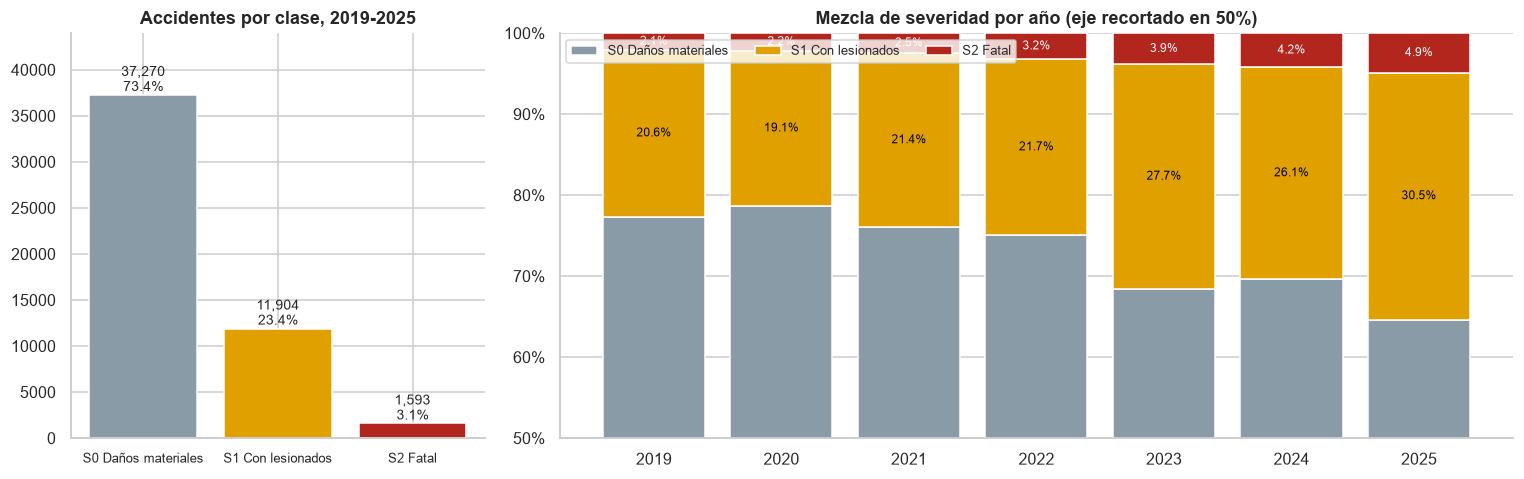

S2 representa 3.14% de los accidentes: la clase fatal es minoritaria (sección 7.4).
La proporción con víctimas pasa de 22.6% en 2019 a 35.4% en 2025; hay un cambio en la mezcla que afectará la calibración.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2.3]})
dist = eda["SEVERIDAD"].value_counts().reindex(CLASES)
axes[0].bar([NOMBRE_CLASE[c] for c in CLASES], dist.values, color=[COLOR[c] for c in CLASES])
for i, v in enumerate(dist.values):
    axes[0].text(i, v, f"{v:,}\n{v / dist.sum():.1%}", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Accidentes por clase, 2019-2025"); axes[0].set_ylim(0, dist.max() * 1.18)
axes[0].tick_params(axis="x", labelsize=8.5)

mezcla = pd.crosstab(eda["ANIO"], eda["SEVERIDAD"], normalize="index")[CLASES]
abajo = np.zeros(len(mezcla))
for c in CLASES:
    axes[1].bar(mezcla.index, mezcla[c], bottom=abajo, color=COLOR[c], label=NOMBRE_CLASE[c])
    for x, b, v in zip(mezcla.index, abajo, mezcla[c]):
        if c != "S0":
            axes[1].text(x, b + v / 2, f"{v:.1%}", ha="center", va="center", fontsize=8, color="white" if c == "S2" else "black")
    abajo += mezcla[c].values
axes[1].set_ylim(0.5, 1); formato_pct(axes[1])
axes[1].set_title("Mezcla de severidad por año (eje recortado en 50%)")
axes[1].legend(loc="upper left", ncol=3, fontsize=8.5)
plt.tight_layout(); guardar(fig, "03_1_distribucion_severidad"); plt.show()

print(f"S2 representa {dist['S2'] / dist.sum():.2%} de los accidentes: la clase fatal es minoritaria (sección 7.4).")
print(f"La proporción con víctimas pasa de {1 - mezcla.loc[2019, 'S0']:.1%} en 2019 a {1 - mezcla.loc[2025, 'S0']:.1%} en 2025;"
      " hay un cambio en la mezcla que afectará la calibración.")

### 3.2 Perfil mensual 2019–2025 y choque COVID-19

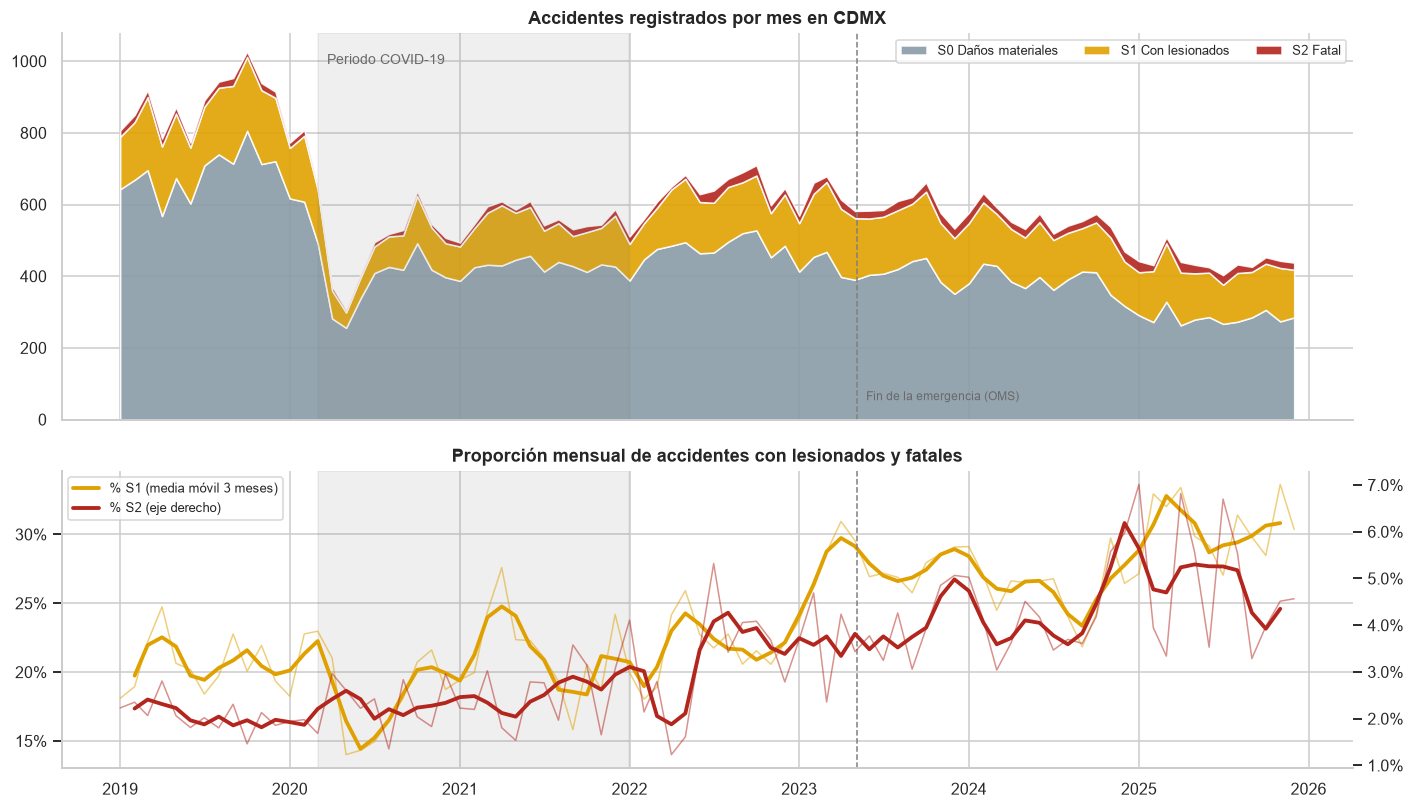

Abril 2020 vs abril 2019: -52.7% en accidentes registrados.


In [13]:
mensual = eda.groupby(["MES_INICIO", "SEVERIDAD"]).size().unstack(fill_value=0)[CLASES]
total_mes = mensual.sum(axis=1)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
a1.stackplot(mensual.index, *(mensual[c] for c in CLASES), colors=[COLOR[c] for c in CLASES],
             labels=[NOMBRE_CLASE[c] for c in CLASES], alpha=0.9)
a1.set_title("Accidentes registrados por mes en CDMX"); a1.legend(loc="upper right", fontsize=8.5, ncol=3)
a2.plot(mensual.index, mensual["S1"] / total_mes, color=COLOR["S1"], lw=1, alpha=0.5)
a2.plot(mensual.index, (mensual["S1"] / total_mes).rolling(3, center=True).mean(), color=COLOR["S1"], lw=2.5, label="% S1 (media móvil 3 meses)")
a2b = a2.twinx()
a2b.plot(mensual.index, mensual["S2"] / total_mes, color=COLOR["S2"], lw=1, alpha=0.5)
a2b.plot(mensual.index, (mensual["S2"] / total_mes).rolling(3, center=True).mean(), color=COLOR["S2"], lw=2.5, label="% S2 (eje derecho)")
formato_pct(a2); formato_pct(a2b, decimales=1); a2b.grid(False)
a2.set_title("Proporción mensual de accidentes con lesionados y fatales")
a2.legend(handles=a2.get_lines()[1:] + a2b.get_lines()[1:], loc="upper left", fontsize=8.5)
for a in (a1, a2):
    a.axvspan(INICIO_COVID, FIN_COVID, color="grey", alpha=0.12)
    a.axvline(FIN_EMERGENCIA_OMS, color="grey", ls="--", lw=1)
a1.text(INICIO_COVID + pd.Timedelta(days=20), a1.get_ylim()[1] * 0.92, "Periodo COVID-19", fontsize=9, color="dimgray")
a1.text(FIN_EMERGENCIA_OMS + pd.Timedelta(days=20), a1.get_ylim()[1] * 0.05, "Fin de la emergencia (OMS)", fontsize=8, color="dimgray")
a2.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
plt.tight_layout(); guardar(fig, "03_2_perfil_mensual_covid"); plt.show()

caida = mensual.loc["2020-04-01"].sum() / mensual.loc["2019-04-01":"2019-04-30"].sum().sum() - 1
print(f"Abril 2020 vs abril 2019: {caida:+.1%} en accidentes registrados.")

In [14]:
meses_periodo = eda.groupby("PERIODO")["MES_INICIO"].nunique().reindex(PERIODOS)
conteo_periodo = pd.crosstab(eda["PERIODO"], eda["SEVERIDAD"]).reindex(PERIODOS)[CLASES]
tabla_periodos = pd.DataFrame({
    "meses": meses_periodo,
    "accidentes por mes": conteo_periodo.sum(axis=1) / meses_periodo,
    "con víctimas (S1+S2) por mes": (conteo_periodo["S1"] + conteo_periodo["S2"]) / meses_periodo,
    "fatales (S2) por mes": conteo_periodo["S2"] / meses_periodo,
    **{f"% {c}": conteo_periodo[c] / conteo_periodo.sum(axis=1) for c in CLASES},
})
chi2, p_valor, gl, _ = chi2_contingency(conteo_periodo.values)
display(tabla_periodos.style.format({"meses": "{:.0f}", "accidentes por mes": "{:,.0f}",
                                     "con víctimas (S1+S2) por mes": "{:,.0f}", "fatales (S2) por mes": "{:,.1f}",
                                     **{f"% {c}": "{:.2%}" for c in CLASES}}))
print(f"Prueba chi-cuadrada de independencia periodo × severidad: chi2 = {chi2:,.1f}, gl = {gl}, p = {p_valor:.2e}")

base_pre = tabla_periodos.iloc[0]
for periodo in PERIODOS[1:]:
    fila = tabla_periodos.loc[periodo]
    print(f"- {periodo}: demanda mensual total {fila['accidentes por mes'] / base_pre['accidentes por mes'] - 1:+.1%}, "
          f"demanda con víctimas {fila['con víctimas (S1+S2) por mes'] / base_pre['con víctimas (S1+S2) por mes'] - 1:+.1%} "
          f"respecto a pre-COVID.")
print("Lectura para la aseguradora: si la demanda con víctimas cae menos que la demanda total, la carga de casos\n"
      "graves por ajustador aumenta aunque haya menos siniestros.")

,meses,accidentes por mes,con víctimas (S1+S2) por mes,fatales (S2) por mes,% S0,% S1,% S2
PERIODO,,,,,,,
Pre-COVID (ene 2019-feb 2020),14,875,198,17.9,77.37%,20.58%,2.05%
COVID (mar 2020-dic 2021),22,532,121,12.6,77.35%,20.28%,2.37%
Pos-COVID (2022-2025),48,558,168,22.2,69.89%,26.14%,3.97%


Prueba chi-cuadrada de independencia periodo × severidad: chi2 = 399.6, gl = 4, p = 3.36e-85
- COVID (mar 2020-dic 2021): demanda mensual total -39.2%, demanda con víctimas -39.1% respecto a pre-COVID.
- Pos-COVID (2022-2025): demanda mensual total -36.2%, demanda con víctimas -15.1% respecto a pre-COVID.
Lectura para la aseguradora: si la demanda con víctimas cae menos que la demanda total, la carga de casos
graves por ajustador aumenta aunque haya menos siniestros.


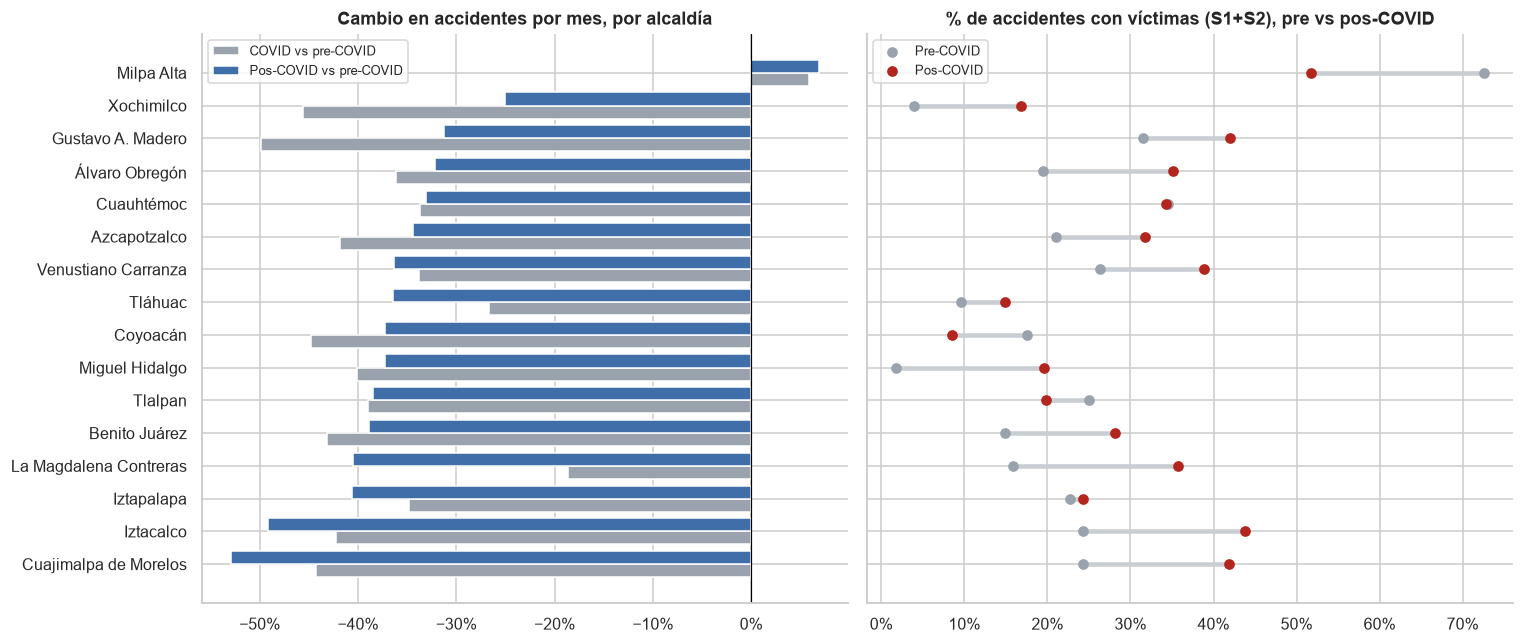

In [15]:
por_alc_periodo = pd.crosstab(eda["ALCALDIA"], eda["PERIODO"]).reindex(columns=PERIODOS) / meses_periodo.values
cambio_volumen = por_alc_periodo.div(por_alc_periodo[PERIODOS[0]], axis=0) - 1
victimas_periodo = eda.groupby(["ALCALDIA", "PERIODO"])["CON_VICTIMAS"].mean().unstack()[PERIODOS]
orden = cambio_volumen[PERIODOS[2]].sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
y = np.arange(len(orden))
axes[0].barh(y - 0.2, cambio_volumen.loc[orden, PERIODOS[1]], height=0.4, color="#9AA3AD", label="COVID vs pre-COVID")
axes[0].barh(y + 0.2, cambio_volumen.loc[orden, PERIODOS[2]], height=0.4, color="#3F6EA8", label="Pos-COVID vs pre-COVID")
axes[0].axvline(0, color="black", lw=0.8); formato_pct(axes[0], "x")
axes[0].set_yticks(y, orden); axes[0].legend(fontsize=8.5)
axes[0].set_title("Cambio en accidentes por mes, por alcaldía")
for i, alc in enumerate(orden):
    a, b = victimas_periodo.loc[alc, PERIODOS[0]], victimas_periodo.loc[alc, PERIODOS[2]]
    axes[1].plot([a, b], [i, i], color="#C9CED3", lw=3, zorder=1)
axes[1].scatter(victimas_periodo.loc[orden, PERIODOS[0]], y, color="#9AA3AD", zorder=2, label="Pre-COVID")
axes[1].scatter(victimas_periodo.loc[orden, PERIODOS[2]], y, color=COLOR["S2"], zorder=2, label="Pos-COVID")
formato_pct(axes[1], "x"); axes[1].legend(fontsize=8.5)
axes[1].set_title("% de accidentes con víctimas (S1+S2), pre vs pos-COVID")
plt.tight_layout(); guardar(fig, "03_2_covid_por_alcaldia"); plt.show()

### 3.3 Severidad por alcaldía

Además de barras, se dibuja un **mapa de mosaicos** (cada cuadro es una alcaldía en su posición geográfica aproximada), que no requiere archivos adicionales. Si tienes el Marco Geoestadístico del INEGI (`09mun.shp`) y `geopandas`, la celda siguiente dibuja además el mapa coroplético.

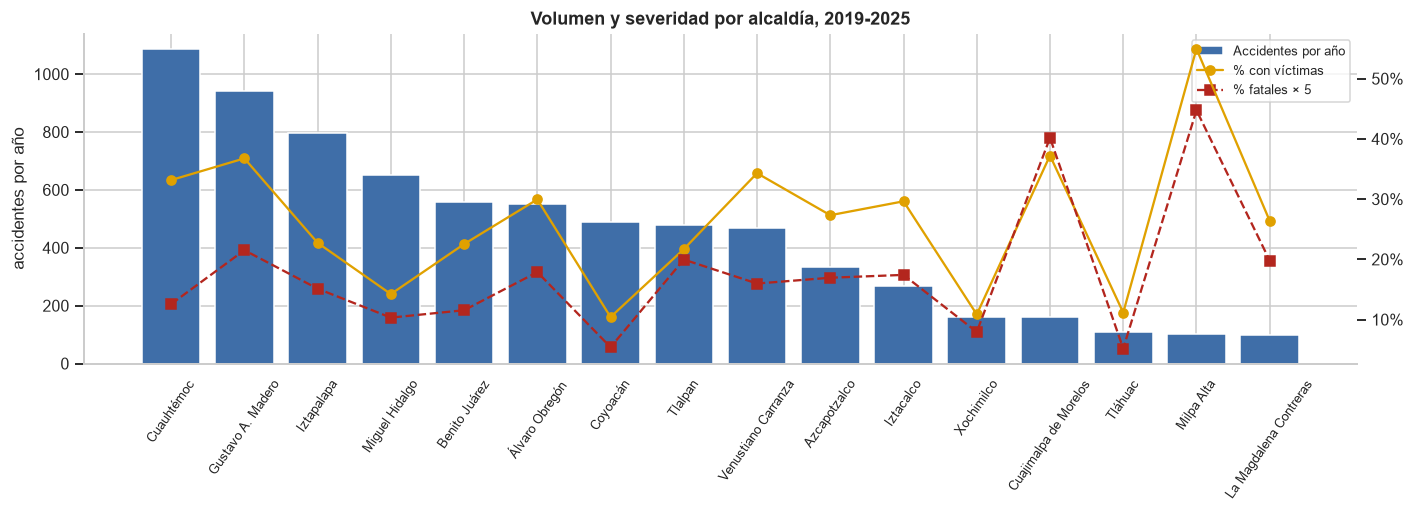

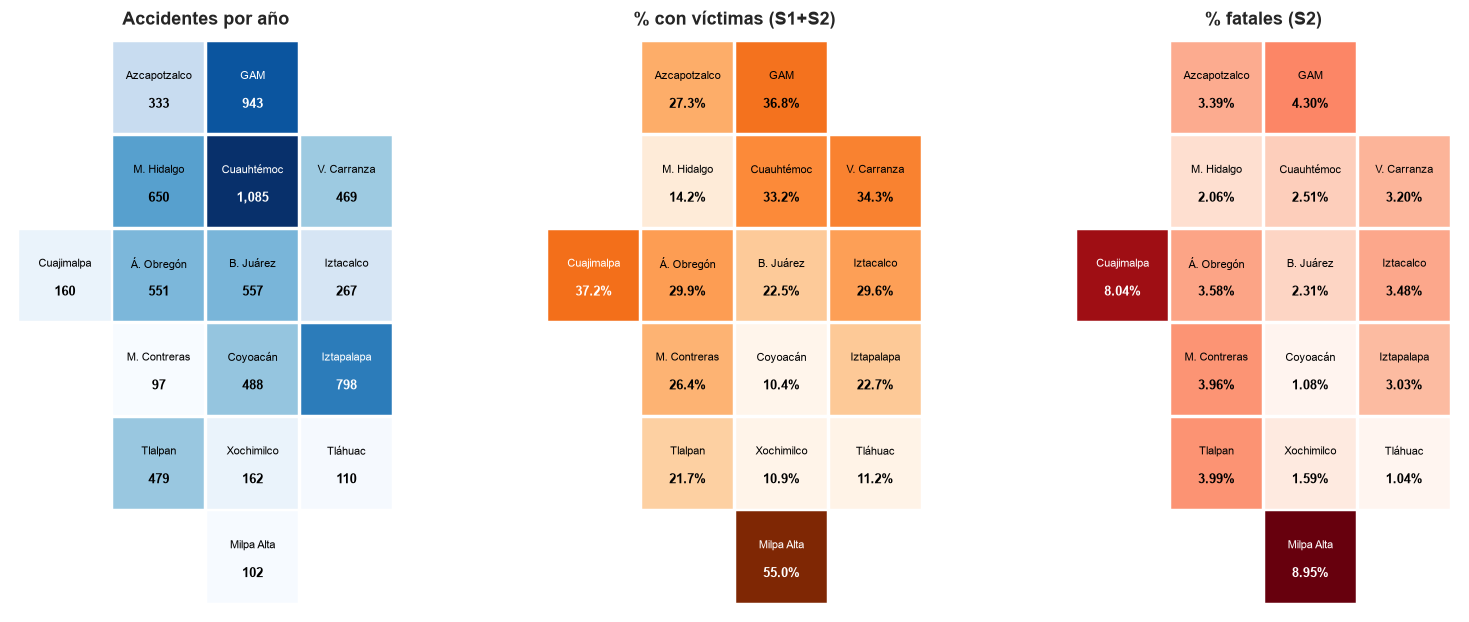

Una alcaldía puede no liderar en volumen y sí en proporción de casos graves (sección 8).


In [16]:
POS_MOSAICO = {"Azcapotzalco": (1, 0), "Gustavo A. Madero": (2, 0), "Miguel Hidalgo": (1, 1), "Cuauhtémoc": (2, 1),
               "Venustiano Carranza": (3, 1), "Cuajimalpa de Morelos": (0, 2), "Álvaro Obregón": (1, 2),
               "Benito Juárez": (2, 2), "Iztacalco": (3, 2), "La Magdalena Contreras": (1, 3), "Coyoacán": (2, 3),
               "Iztapalapa": (3, 3), "Tlalpan": (1, 4), "Xochimilco": (2, 4), "Tláhuac": (3, 4), "Milpa Alta": (2, 5)}
ABREV = {"Gustavo A. Madero": "GAM", "Cuajimalpa de Morelos": "Cuajimalpa", "La Magdalena Contreras": "M. Contreras",
         "Venustiano Carranza": "V. Carranza", "Álvaro Obregón": "Á. Obregón", "Benito Juárez": "B. Juárez",
         "Miguel Hidalgo": "M. Hidalgo"}

def mapa_mosaico(ax, valores, titulo, cmap="Reds", fmt="{:.1%}"):
    norm = plt.Normalize(valores.min(), valores.max())
    paleta = plt.get_cmap(cmap)
    for alcaldia, (x, y) in POS_MOSAICO.items():
        v = valores.get(alcaldia, np.nan)
        ax.add_patch(plt.Rectangle((x, -y), 0.95, 0.95, color=paleta(norm(v)) if pd.notna(v) else "#EEE"))
        color_txt = "white" if pd.notna(v) and norm(v) > 0.6 else "black"
        ax.text(x + 0.475, -y + 0.6, ABREV.get(alcaldia, alcaldia), ha="center", va="center", fontsize=7.5, color=color_txt)
        ax.text(x + 0.475, -y + 0.3, fmt.format(v), ha="center", va="center", fontsize=8.5, fontweight="bold", color=color_txt)
    ax.set_xlim(-0.1, 4.05); ax.set_ylim(-5.1, 1.05); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(titulo)

alc = eda.groupby("ALCALDIA").agg(accidentes=("SEVERIDAD", "size"), con_victimas=("CON_VICTIMAS", "mean"),
                                  fatales=("ES_S2", "mean"), n_victimas=("CON_VICTIMAS", "sum"))
alc["accidentes_por_anio"] = alc["accidentes"] / N_ANIOS_EDA
alc = alc.sort_values("accidentes", ascending=False)

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(alc.index, alc["accidentes_por_anio"], color="#3F6EA8", label="Accidentes por año (eje izq.)")
ax.set_ylabel("accidentes por año"); ax.tick_params(axis="x", rotation=55, labelsize=8.5)
ax2 = ax.twinx()
ax2.plot(alc.index, alc["con_victimas"], "o-", color=COLOR["S1"], label="% con víctimas (S1+S2)")
ax2.plot(alc.index, alc["fatales"] * 5, "s--", color=COLOR["S2"], label="% fatales (S2) × 5")
formato_pct(ax2); ax2.grid(False)
ax.legend(handles=ax.patches[:1] + ax2.get_lines(), labels=["Accidentes por año", "% con víctimas", "% fatales × 5"], loc="upper right", fontsize=8.5)
ax.set_title("Volumen y severidad por alcaldía, 2019-2025")
plt.tight_layout(); guardar(fig, "03_3_alcaldias_barras"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 5.8))
mapa_mosaico(axes[0], alc["accidentes_por_anio"], "Accidentes por año", "Blues", "{:,.0f}")
mapa_mosaico(axes[1], alc["con_victimas"], "% con víctimas (S1+S2)", "Oranges")
mapa_mosaico(axes[2], alc["fatales"], "% fatales (S2)", "Reds", "{:.2%}")
plt.tight_layout(); guardar(fig, "03_3_mapa_mosaico_alcaldias"); plt.show()
print("Una alcaldía puede no liderar en volumen y sí en proporción de casos graves (sección 8).")

In [17]:
# Mapa coroplético opcional con el Marco Geoestadístico del INEGI (archivo 09mun.shp)
if SHAPEFILE_ALCALDIAS.exists():
    try:
        import geopandas as gpd
        geo = gpd.read_file(SHAPEFILE_ALCALDIAS).merge(alc.reset_index().assign(
            CVEGEO=lambda d: d["ALCALDIA"].map({v: k for k, v in sf.ALCALDIAS.items()})), on="CVEGEO")
        fig, axes = plt.subplots(1, 3, figsize=(16, 6))
        for ax, (col, titulo, cmap) in zip(axes, [("accidentes_por_anio", "Accidentes por año", "Blues"),
                                                  ("con_victimas", "% con víctimas", "Oranges"),
                                                  ("fatales", "% fatales", "Reds")]):
            geo.plot(column=col, cmap=cmap, legend=True, edgecolor="white", ax=ax); ax.set_title(titulo); ax.axis("off")
        plt.tight_layout(); guardar(fig, "03_3_mapa_coropletico"); plt.show()
    except ImportError:
        print("Instala geopandas para dibujar el mapa coroplético.")
else:
    print(f"No se encontró {SHAPEFILE_ALCALDIAS}; se usa el mapa de mosaicos de arriba.")

No se encontró data/09mun.shp; se usa el mapa de mosaicos de arriba.


### 3.4 Hora del día y día de la semana

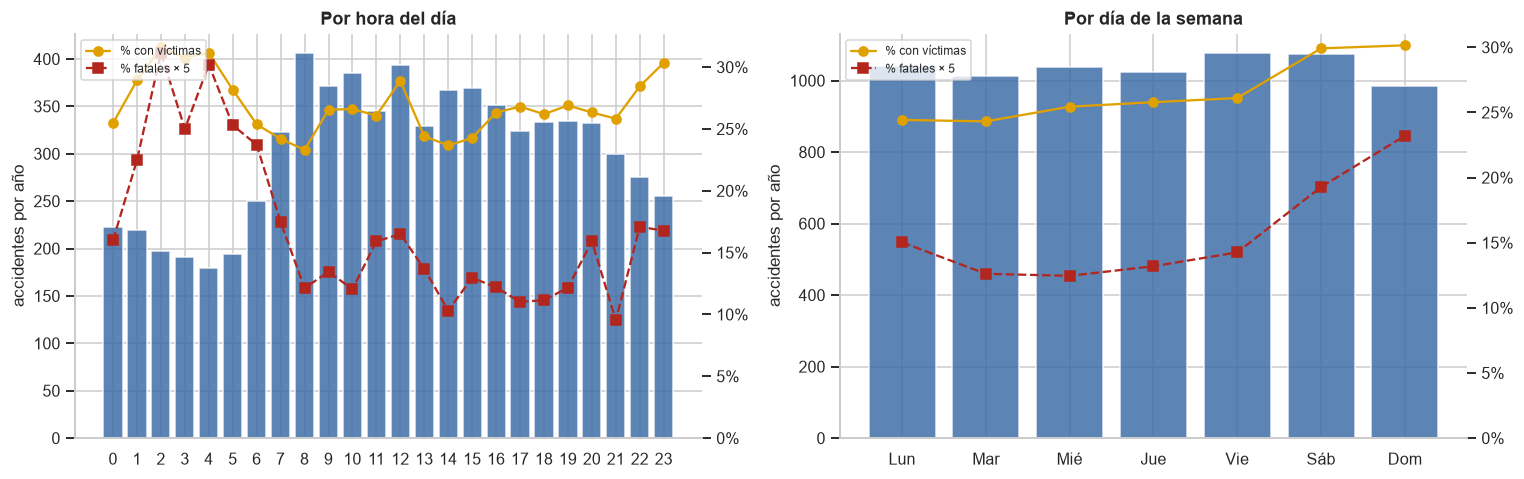

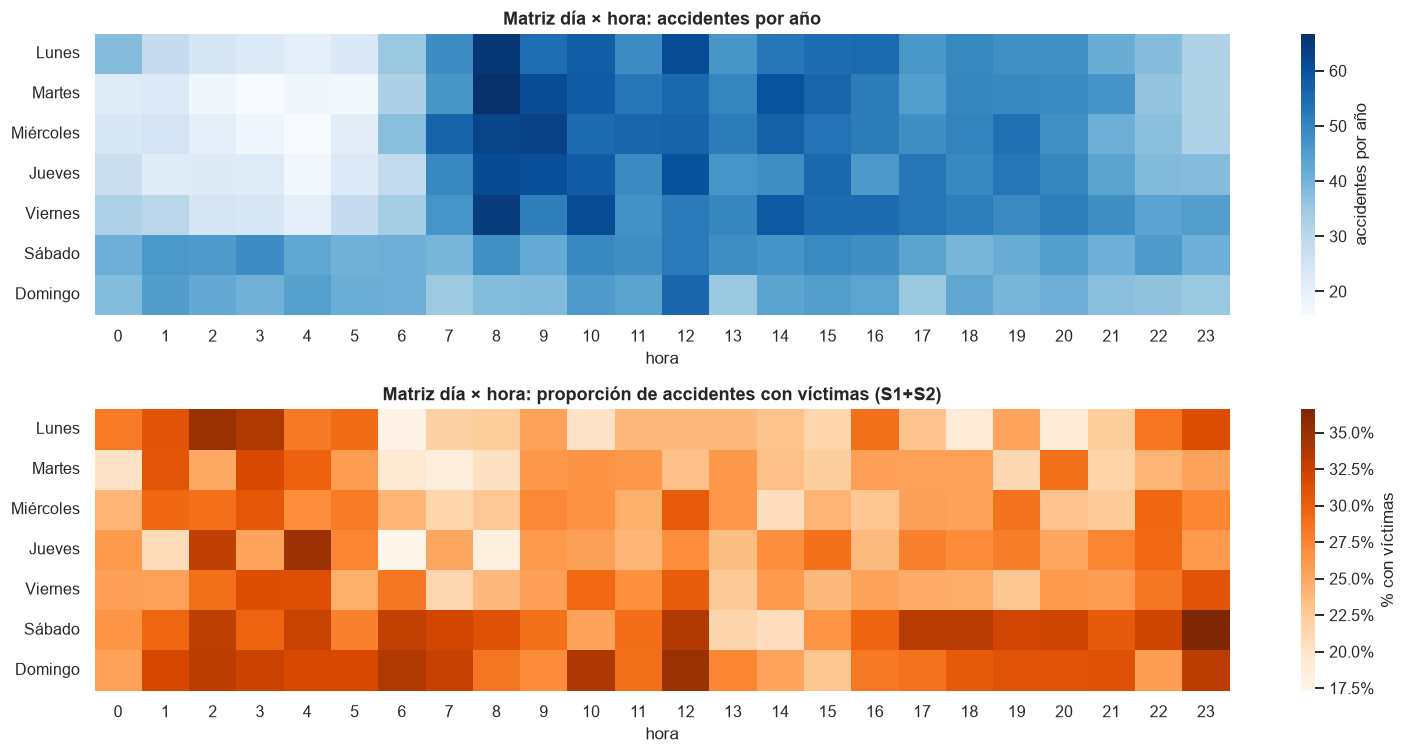

Hora más letal: 2:00 (6.23% fatales) | hora con más accidentes: 8:00


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
por_hora = eda[eda["ID_HORA"].between(0, 23)].groupby("ID_HORA").agg(n=("SEVERIDAD", "size"), v=("CON_VICTIMAS", "mean"), f=("ES_S2", "mean"))
por_dia = eda[eda["DIASEMANA"].isin(sf.DIAS)].groupby("DIASEMANA").agg(n=("SEVERIDAD", "size"), v=("CON_VICTIMAS", "mean"), f=("ES_S2", "mean")).reindex(sf.DIAS)
for ax, datos, etiquetas, titulo in [(axes[0], por_hora, por_hora.index, "Por hora del día"),
                                     (axes[1], por_dia, [d[:3] for d in sf.DIAS], "Por día de la semana")]:
    ax.bar(range(len(datos)), datos["n"] / N_ANIOS_EDA, color="#3F6EA8", alpha=0.85)
    ax.set_xticks(range(len(datos)), etiquetas); ax.set_ylabel("accidentes por año"); ax.set_title(titulo)
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(range(len(datos)), datos["v"], "o-", color=COLOR["S1"], label="% con víctimas")
    ax2.plot(range(len(datos)), datos["f"] * 5, "s--", color=COLOR["S2"], label="% fatales × 5")
    formato_pct(ax2); ax2.set_ylim(0, None); ax2.legend(fontsize=8, loc="upper left")
plt.tight_layout(); guardar(fig, "03_4_hora_dia"); plt.show()

hora_valida = eda[eda["ID_HORA"].between(0, 23) & eda["DIASEMANA"].isin(sf.DIAS)]
vol = pd.crosstab(hora_valida["DIASEMANA"], hora_valida["ID_HORA"]).reindex(sf.DIAS) / N_ANIOS_EDA
sev = hora_valida.pivot_table(index="DIASEMANA", columns="ID_HORA", values="CON_VICTIMAS", aggfunc="mean").reindex(sf.DIAS)
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
sns.heatmap(vol, cmap="Blues", ax=axes[0], cbar_kws={"label": "accidentes por año"})
axes[0].set_title("Matriz día × hora: accidentes por año")
sns.heatmap(sev, cmap="Oranges", ax=axes[1], cbar_kws={"label": "% con víctimas", "format": mtick.PercentFormatter(1.0)})
axes[1].set_title("Matriz día × hora: proporción de accidentes con víctimas (S1+S2)")
for a in axes: a.set_xlabel("hora"); a.set_ylabel("")
plt.tight_layout(); guardar(fig, "03_4_matriz_dia_hora"); plt.show()
print(f"Hora más letal: {por_hora['f'].idxmax()}:00 ({por_hora['f'].max():.2%} fatales) | "
      f"hora con más accidentes: {por_hora['n'].idxmax()}:00")

### 3.5 Matriz alcaldía × hora: dónde y cuándo se concentra la demanda de ajustadores

La sección 7.2 pide identificar franjas que combinan **alta frecuencia con alta severidad**. La tercera matriz cuenta directamente los accidentes con víctimas, que es la demanda que más le interesa priorizar a la aseguradora.

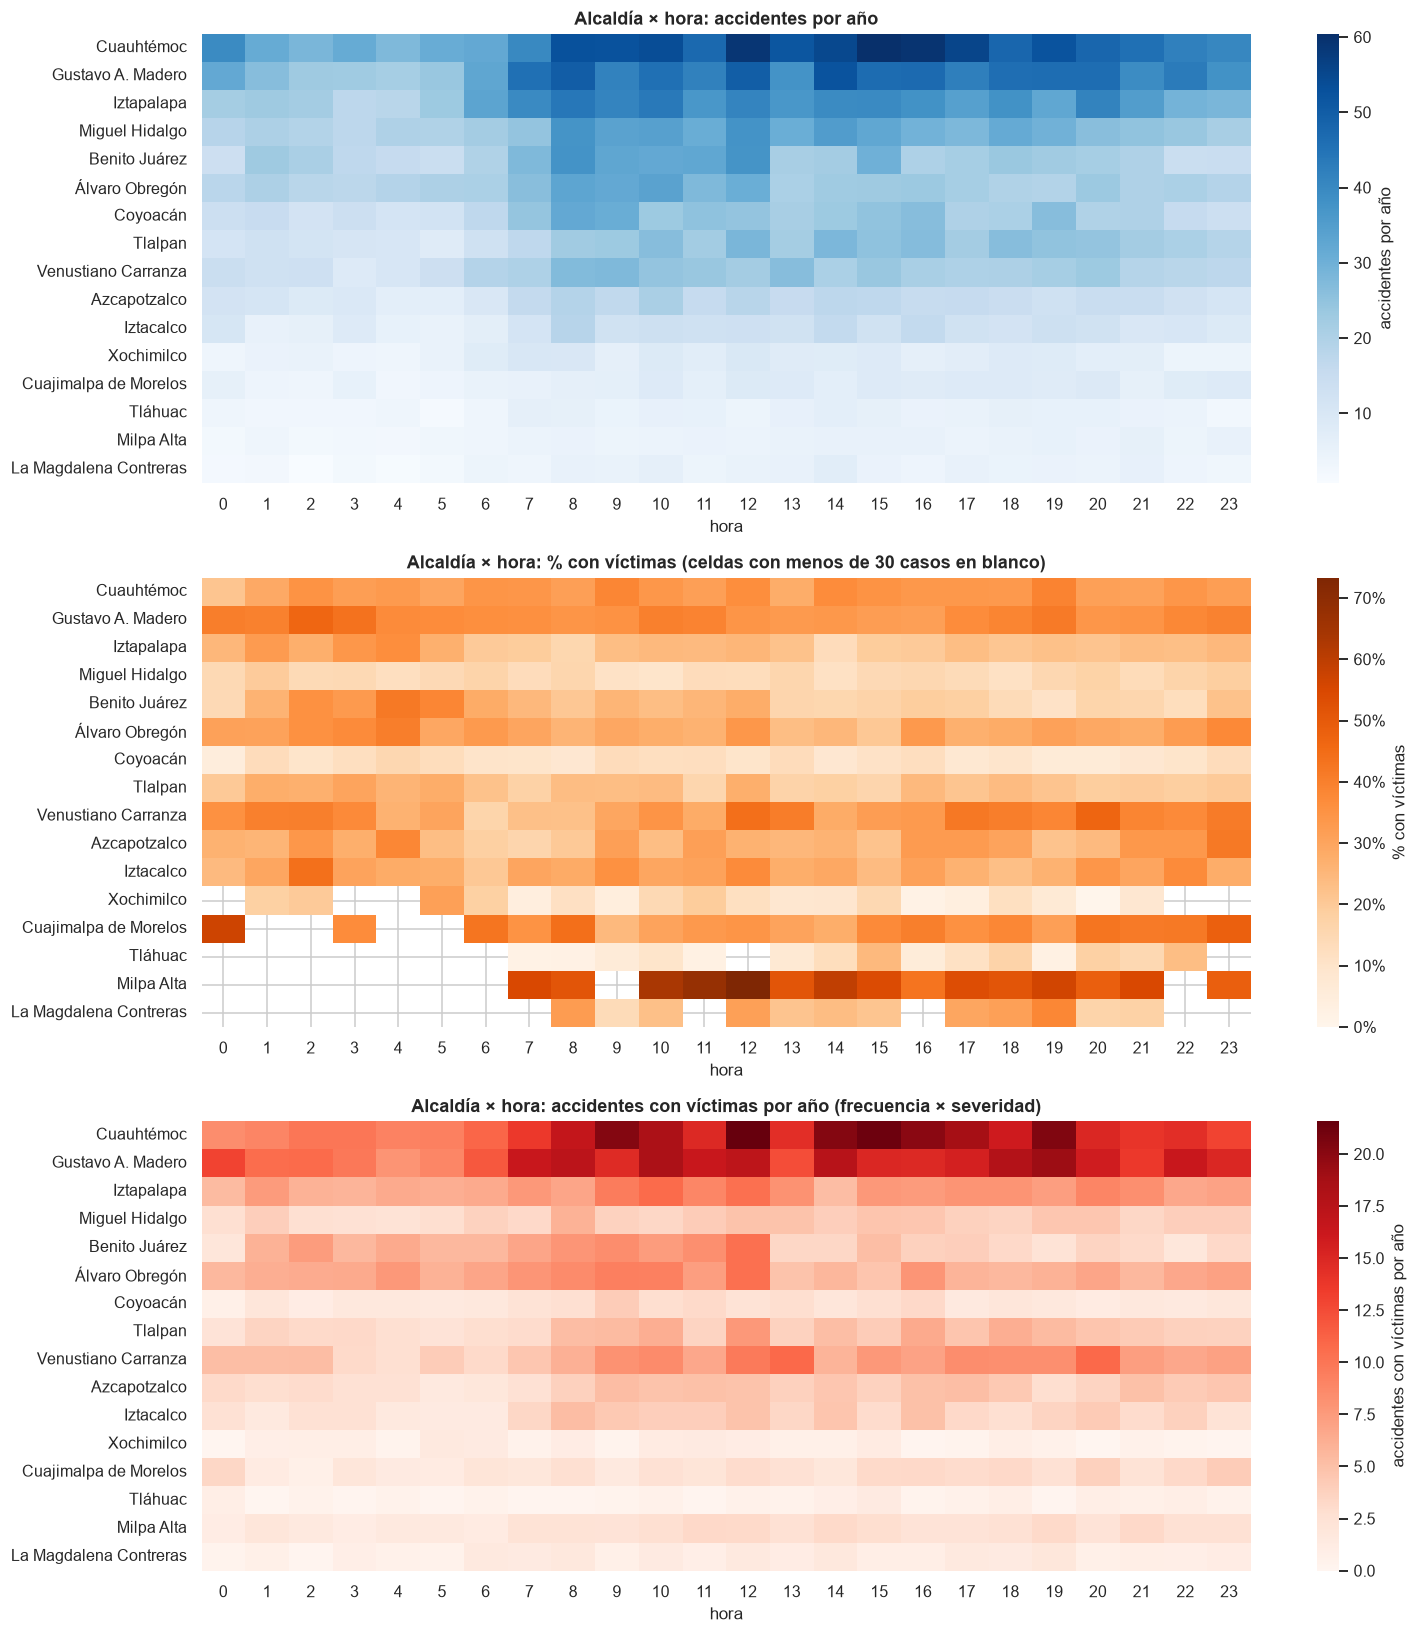

Celdas alcaldía-hora con más accidentes con víctimas por año:
  Cuauhtémoc               12:00   21.6 por año  (37% con víctimas)
  Cuauhtémoc               15:00   21.3 por año  (35% con víctimas)
  Cuauhtémoc               19:00   20.4 por año  (39% con víctimas)
  Cuauhtémoc               09:00   20.3 por año  (38% con víctimas)
  Cuauhtémoc               14:00   20.3 por año  (37% con víctimas)
  Cuauhtémoc               16:00   20.0 por año  (34% con víctimas)
  Gustavo A. Madero        19:00   19.1 por año  (41% con víctimas)
  Cuauhtémoc               17:00   18.7 por año  (34% con víctimas)


In [19]:
ah = eda[eda["ID_HORA"].between(0, 23)]
orden_alc = alc.index
m_vol = pd.crosstab(ah["ALCALDIA"], ah["ID_HORA"]).reindex(orden_alc) / N_ANIOS_EDA
m_n = pd.crosstab(ah["ALCALDIA"], ah["ID_HORA"]).reindex(orden_alc)
m_pct = ah.pivot_table(index="ALCALDIA", columns="ID_HORA", values="CON_VICTIMAS", aggfunc="mean").reindex(orden_alc)
m_grave = ah.pivot_table(index="ALCALDIA", columns="ID_HORA", values="CON_VICTIMAS", aggfunc="sum").reindex(orden_alc) / N_ANIOS_EDA

fig, axes = plt.subplots(3, 1, figsize=(14, 15))
sns.heatmap(m_vol, cmap="Blues", ax=axes[0], cbar_kws={"label": "accidentes por año"})
axes[0].set_title("Alcaldía × hora: accidentes por año")
sns.heatmap(m_pct.where(m_n >= 30), cmap="Oranges", ax=axes[1],
            cbar_kws={"label": "% con víctimas", "format": mtick.PercentFormatter(1.0)})
axes[1].set_title("Alcaldía × hora: % con víctimas (celdas con menos de 30 casos en blanco)")
sns.heatmap(m_grave, cmap="Reds", ax=axes[2], cbar_kws={"label": "accidentes con víctimas por año"})
axes[2].set_title("Alcaldía × hora: accidentes con víctimas por año (frecuencia × severidad)")
for a in axes: a.set_xlabel("hora"); a.set_ylabel("")
plt.tight_layout(); guardar(fig, "03_5_matriz_alcaldia_hora"); plt.show()

top = m_grave.stack().sort_values(ascending=False).head(8)
print("Celdas alcaldía-hora con más accidentes con víctimas por año:")
for (a, h), v in top.items():
    print(f"  {a:<24} {h:02d}:00  {v:5.1f} por año  ({m_pct.loc[a, h]:.0%} con víctimas)")

### 3.6 Tipo de accidente × severidad

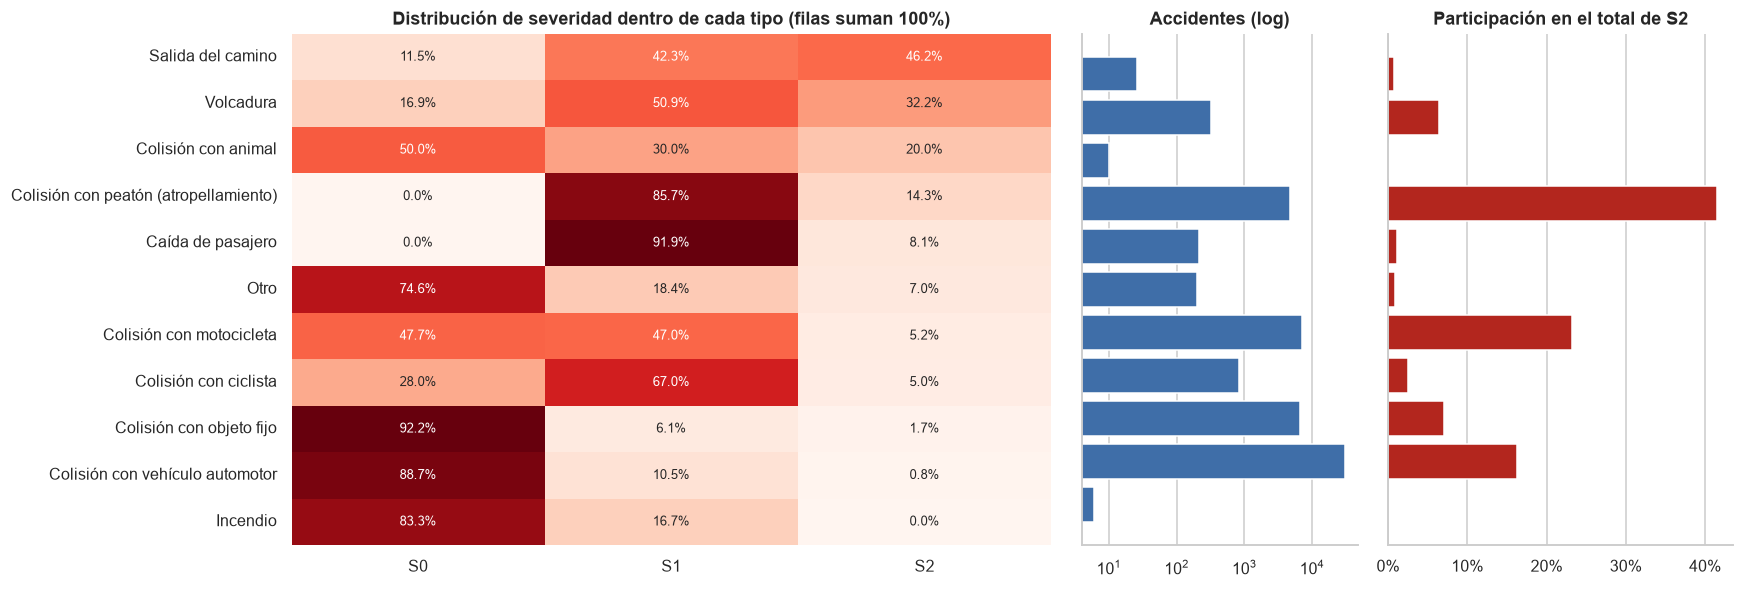

Los dos tipos con más fatales (Colisión con peatón (atropellamiento), Colisión con motocicleta) concentran 65% de los S2.


In [20]:
tipo = pd.crosstab(eda["TIPACCID"], eda["SEVERIDAD"])[CLASES]
tipo_pct = tipo.div(tipo.sum(axis=1), axis=0)
tipo_pct = tipo_pct.loc[tipo_pct["S2"].sort_values(ascending=False).index]
participacion_s2 = (tipo["S2"] / tipo["S2"].sum()).reindex(tipo_pct.index)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), gridspec_kw={"width_ratios": [2.2, 0.8, 1]})
sns.heatmap(tipo_pct, annot=True, fmt=".1%", cmap="Reds", cbar=False, ax=axes[0], annot_kws={"fontsize": 8.5})
axes[0].set_title("Distribución de severidad dentro de cada tipo (filas suman 100%)"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
axes[1].barh(range(len(tipo_pct)), tipo.sum(axis=1).reindex(tipo_pct.index), color="#3F6EA8")
axes[1].set_yticks([]); axes[1].invert_yaxis(); axes[1].set_xscale("log"); axes[1].set_title("Accidentes (log)")
axes[2].barh(range(len(tipo_pct)), participacion_s2, color=COLOR["S2"])
axes[2].set_yticks([]); axes[2].invert_yaxis(); formato_pct(axes[2], "x"); axes[2].set_title("Participación en el total de S2")
plt.tight_layout(); guardar(fig, "03_6_tipo_severidad"); plt.show()

conc = participacion_s2.sort_values(ascending=False)
print(f"Los dos tipos con más fatales ({', '.join(conc.index[:2])}) concentran {conc.iloc[:2].sum():.0%} de los S2.")

### 3.7 Composición vehicular

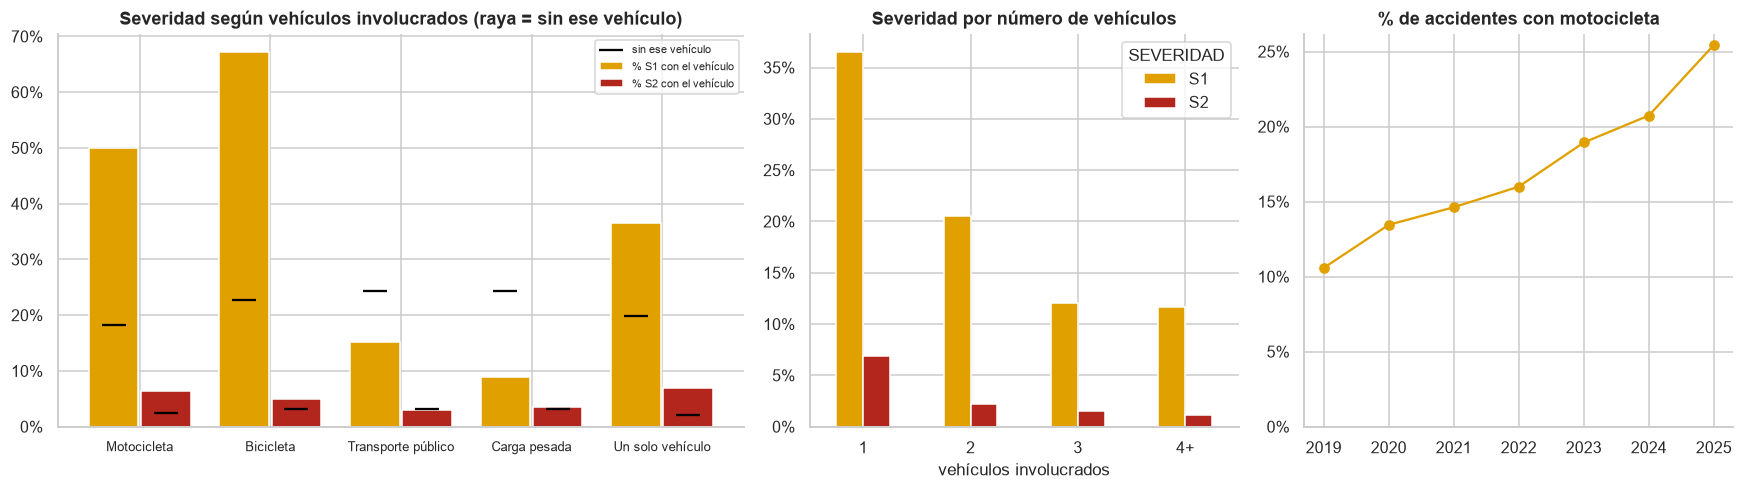

,vehículo,presente,n,% S1,% S2
0,Motocicleta,Sí,"8,311",49.9%,6.49%
1,Motocicleta,No,"42,456",18.3%,2.48%
2,Bicicleta,Sí,885,67.1%,4.97%
3,Bicicleta,No,"49,882",22.7%,3.11%
4,Transporte público,Sí,"4,636",15.2%,2.91%
5,Transporte público,No,"46,131",24.3%,3.16%
6,Carga pesada,Sí,"2,682",8.8%,3.62%
7,Carga pesada,No,"48,085",24.3%,3.11%
8,Un solo vehículo,Sí,"10,871",36.5%,6.87%
9,Un solo vehículo,No,"39,896",19.9%,2.12%


In [21]:
indicadores = {"HAY_MOTO": "Motocicleta", "HAY_BICI": "Bicicleta", "HAY_TRANSP_PUBLICO": "Transporte público",
               "HAY_CARGA_PESADA": "Carga pesada", "UN_VEHICULO": "Un solo vehículo"}
filas = []
for col, nombre in indicadores.items():
    for valor, etiqueta in [(1, "Sí"), (0, "No")]:
        sub = eda[eda[col] == valor]
        filas.append({"vehículo": nombre, "presente": etiqueta, "n": len(sub),
                      "% S1": (sub["SEVERIDAD"] == "S1").mean(), "% S2": sub["ES_S2"].mean()})
veh = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
x = np.arange(len(indicadores))
for j, (clase, color) in enumerate([("% S1", COLOR["S1"]), ("% S2", COLOR["S2"])]):
    si = veh[veh["presente"] == "Sí"].set_index("vehículo")[clase].reindex(indicadores.values())
    no = veh[veh["presente"] == "No"].set_index("vehículo")[clase].reindex(indicadores.values())
    axes[0].bar(x + (j - 0.5) * 0.4, si, width=0.38, color=color, label=f"{clase} con el vehículo")
    axes[0].scatter(x + (j - 0.5) * 0.4, no, color="black", marker="_", s=250, zorder=3, label="sin ese vehículo" if j == 0 else None)
axes[0].set_xticks(x, indicadores.values(), fontsize=8.5); formato_pct(axes[0]); axes[0].legend(fontsize=7.5)
axes[0].set_title("Severidad según vehículos involucrados (raya = sin ese vehículo)")

nveh = eda.assign(NV=eda["NVEH"].clip(upper=4).astype(int).astype(str).replace("4", "4+"))
tab = pd.crosstab(nveh["NV"], nveh["SEVERIDAD"], normalize="index")[CLASES]
tab[["S1", "S2"]].plot(kind="bar", color=[COLOR["S1"], COLOR["S2"]], ax=axes[1], rot=0)
formato_pct(axes[1]); axes[1].set_xlabel("vehículos involucrados"); axes[1].set_title("Severidad por número de vehículos")

moto_anio = eda.groupby("ANIO")["HAY_MOTO"].mean()
axes[2].plot(moto_anio.index, moto_anio.values, "o-", color=COLOR["S1"])
formato_pct(axes[2]); axes[2].set_title("% de accidentes con motocicleta"); axes[2].set_ylim(0, None)
plt.tight_layout(); guardar(fig, "03_7_vehiculos"); plt.show()
display(veh.style.format({"n": "{:,}", "% S1": "{:.1%}", "% S2": "{:.2%}"}))

## 4. Preparación de datos

### 4.1 Matriz de disponibilidad temporal (sección 7.3)

Cada campo de ATUS se clasifica según el momento en que la aseguradora lo conocería. Sólo los campos disponibles en el **primer aviso** entran al modelo de la Etapa 1; los demás se excluyen para evitar fuga de información.

In [22]:
DISPONIBILIDAD = [
    (["ANIO"], "Primer aviso", "Excluida", "Sólo se usa para particionar; como predictor extrapolaría la tendencia"),
    (["MES"], "Primer aviso", "Predictora: MES", ""),
    (["ID_DIA"], "Primer aviso", "Excluida", "Sin hipótesis de negocio; se usa DIASEMANA"),
    (["DIASEMANA"], "Primer aviso", "Predictora: DIASEMANA, FIN_SEMANA", ""),
    (["ID_HORA"], "Primer aviso", "Predictora: FRANJA, HORA_SIN, HORA_COS", "Codificación cíclica: 23 h y 0 h quedan cerca"),
    (["ID_MINUTO"], "Primer aviso", "Excluida", "Redondeado a cuartos de hora; sin señal esperada"),
    (["CVEGEO", "CVE_MUN"], "Primer aviso", "Predictora: ALCALDIA", ""),
    (["COBERTURA", "CVE_ENT"], "Primer aviso", "Excluida", "Constantes para CDMX"),
    (["URBANA"], "Primer aviso", "Predictora: UBICACION", "Intersección o no intersección"),
    (["SUBURBANA"], "Primer aviso", "Excluida", "99.6% sin accidente suburbano en CDMX; queda resumida en UBICACION"),
    (["CAPAROD"], "Primer aviso", "Excluida", "Casi constante en CDMX (99.9% pavimentada)"),
    (["TIPACCID"], "Primer aviso", "Predictora: TIPACCID", "Quien reporta sabe si atropelló a alguien o si hubo moto"),
    (sf.VEHICULOS, "Primer aviso", "Predictora: N_* por grupo, NVEH, HAY_*", "Conteos agrupados en 6 tipos"),
    (["CAUSAACCI"], "Llegada de autoridad o ajustador", "Excluida", "La causa se determina tras la inspección"),
    (["SEXO", "ID_EDAD"], "Llegada de autoridad o ajustador", "Excluida", "Datos del presunto responsable; 'Se fugó' se sabe después"),
    (["ALIENTO"], "Llegada de autoridad o ajustador", "Excluida", "Requiere valoración en el lugar"),
    (["CINTURON"], "Llegada de autoridad o ajustador", "Excluida", "Requiere valoración en el lugar"),
    (sf.VICTIMAS_HERIDAS + sf.VICTIMAS_MUERTAS, "Resultado final", "Etiqueta", "Sólo para construir S0/S1/S2"),
    (["CLASACC"], "Resultado final", "Excluida", "Equivale a la etiqueta"),
    (["ESTATUS"], "Resultado final", "Excluida", "Metadato administrativo"),
]
matriz_disp = pd.DataFrame([{"campos ATUS": ", ".join(c) if len(c) <= 3 else f"{c[0]} … {c[-1]} ({len(c)} campos)",
                             "disponible en": d, "uso en Etapa 1": u, "justificación": j} for c, d, u, j in DISPONIBILIDAD])
display(matriz_disp)

clasificados = {c for fila in DISPONIBILIDAD for c in fila[0]}
sin_clasificar = [c for c in crudo.columns if c not in clasificados]
print("Columnas del dataset sin clasificar:", sin_clasificar or "ninguna")
assert not sin_clasificar, "Toda columna debe tener una decisión explícita de disponibilidad"

,campos ATUS,disponible en,uso en Etapa 1,justificación
0,ANIO,Primer aviso,Excluida,Sólo se usa para particionar; como predictor e...
1,MES,Primer aviso,Predictora: MES,
2,ID_DIA,Primer aviso,Excluida,Sin hipótesis de negocio; se usa DIASEMANA
3,DIASEMANA,Primer aviso,"Predictora: DIASEMANA, FIN_SEMANA",
4,ID_HORA,Primer aviso,"Predictora: FRANJA, HORA_SIN, HORA_COS",Codificación cíclica: 23 h y 0 h quedan cerca
5,ID_MINUTO,Primer aviso,Excluida,Redondeado a cuartos de hora; sin señal esperada
6,"CVEGEO, CVE_MUN",Primer aviso,Predictora: ALCALDIA,
7,"COBERTURA, CVE_ENT",Primer aviso,Excluida,Constantes para CDMX
8,URBANA,Primer aviso,Predictora: UBICACION,Intersección o no intersección
9,SUBURBANA,Primer aviso,Excluida,99.6% sin accidente suburbano en CDMX; queda r...


Columnas del dataset sin clasificar: ninguna


In [23]:
riesgo = eda[eda["TIPACCID"].isin(["Colisión con peatón (atropellamiento)", "Caída de pasajero", "Colisión con ciclista"])]
display(pd.crosstab(riesgo["TIPACCID"], riesgo["SEVERIDAD"], normalize="index")[CLASES].style.format("{:.1%}"))
print("Estos tipos casi siempre tienen víctimas por definición. Se conservan porque quien reporta los conoce en el\n"
      "primer aviso, pero explican parte importante de la señal del modelo: la sección 8 (SHAP) lo verifica.")

SEVERIDAD,S0,S1,S2
TIPACCID,,,
Caída de pasajero,0.0%,91.9%,8.1%
Colisión con ciclista,28.0%,67.0%,5.0%
Colisión con peatón (atropellamiento),0.0%,85.7%,14.3%


Estos tipos casi siempre tienen víctimas por definición. Se conservan porque quien reporta los conoce en el
primer aviso, pero explican parte importante de la señal del modelo: la sección 8 (SHAP) lo verifica.


### 4.2 Variables del primer aviso y particiones temporales

| Conjunto | Años | Uso |
|---|---|---|
| Entrenamiento A | 2019–2023 | Modelo con pandemia |
| Entrenamiento B | 2022–2023 | Modelo pospandemia |
| Validación | 2024 | Hiperparámetros, elección de ventana y modelo, calibración y umbrales |
| Prueba final | 2025 | Se abre una sola vez en la sección 7 |

,registros,S0,S1,S2
Entrenamiento A (2019-2023),"38,837",75.25%,22.04%,2.72%
Entrenamiento B (2022-2023),"14,872",71.85%,24.62%,3.54%
Validación (2024),"6,655",69.66%,26.12%,4.22%
Prueba (2025),"5,275",64.64%,30.48%,4.87%


Ejemplo de variables construidas:


,MES,DIASEMANA,FRANJA,ALCALDIA,TIPACCID,UBICACION,HORA_SIN,HORA_COS,FIN_SEMANA,NVEH,N_AUTOS,N_TRANSP_PUBLICO,N_CARGA,N_MOTO,N_BICI,N_OTRO,HAY_MOTO,HAY_BICI,HAY_TRANSP_PUBLICO,HAY_CARGA_PESADA,UN_VEHICULO
38837,1,Lunes,Tarde (12-17),Azcapotzalco,Colisión con peatón (atropellamiento),No intersección,0.0000,-1.0000,0,1,1,0,0,0,0,0,0,0,0,0,1
38838,1,Martes,Mañana (6-11),Azcapotzalco,Colisión con vehículo automotor,Intersección,1.0000,0.0000,0,2,2,0,0,0,0,0,0,0,0,0,0
38839,1,Jueves,Noche (18-23),Azcapotzalco,Colisión con motocicleta,No intersección,-0.2588,0.9659,0,2,1,0,0,1,0,0,1,0,0,0,0
38840,1,Viernes,Mañana (6-11),Azcapotzalco,Colisión con motocicleta,Intersección,0.7071,-0.7071,0,2,0,0,1,1,0,0,1,0,0,0,0
38841,1,Viernes,Mañana (6-11),Azcapotzalco,Colisión con vehículo automotor,Intersección,0.5000,-0.8660,0,2,2,0,0,0,0,0,0,0,0,0,0


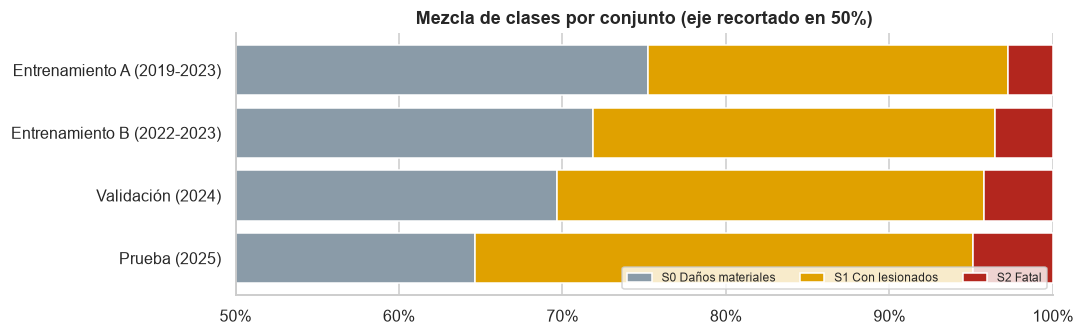

In [24]:
base = df[~df["EXCLUIR"]].copy()
base["y"] = base["SEVERIDAD"].map(Y_MAP).astype(int)
raw_val, raw_test = base[base["ANIO"] == ANIO_VAL], base[base["ANIO"] == ANIO_TEST]
y_val, y_test = raw_val["y"].to_numpy(), raw_test["y"].to_numpy()
raw_train = {v: base[base["ANIO"].isin(anios)] for v, anios in VENTANAS.items()}

conjuntos = {"Entrenamiento A (2019-2023)": raw_train["A"], "Entrenamiento B (2022-2023)": raw_train["B"],
             "Validación (2024)": raw_val, "Prueba (2025)": raw_test}
resumen_sets = pd.DataFrame({k: {"registros": len(v), **v["SEVERIDAD"].value_counts(normalize=True).reindex(CLASES).to_dict()}
                             for k, v in conjuntos.items()}).T
display(resumen_sets.style.format({"registros": "{:,.0f}", **{c: "{:.2%}" for c in CLASES}}))

ejemplo_features = sf.construir_features(raw_val.head(5))
print("Ejemplo de variables construidas:")
display(ejemplo_features)

fig, ax = plt.subplots(figsize=(10, 3.2))
abajo = np.zeros(len(resumen_sets))
for c in CLASES:
    ax.barh(resumen_sets.index, resumen_sets[c].astype(float), left=abajo, color=COLOR[c], label=NOMBRE_CLASE[c])
    abajo += resumen_sets[c].astype(float).values
ax.invert_yaxis(); formato_pct(ax, "x"); ax.set_xlim(0.5, 1); ax.legend(ncol=3, fontsize=8, loc="lower right")
ax.set_title("Mezcla de clases por conjunto (eje recortado en 50%)")
plt.tight_layout(); guardar(fig, "04_particiones"); plt.show()

## 5. Modelado y experimento COVID-19

Para cada ventana (A y B) se entrenan con **el mismo pipeline**:

- **Baseline:** Regresión Logística multinomial con `class_weight="balanced"`; se elige C en validación.
- **Candidato:** XGBoost `multi:softprob` con pesos por muestra balanceados, búsqueda aleatoria de hiperparámetros y *early stopping* en 2024.

El criterio de selección en validación es Macro F1 (equilibra S0, S1 y S2), con el recall de S2 como métrica de control.

In [25]:
def metricas(y, P, yhat=None):
    """Métricas de la sección 7.5. yhat = argmax de P salvo que se indique otra regla."""
    yhat = P.argmax(axis=1) if yhat is None else yhat
    prec, rec, f1, _ = precision_recall_fscore_support(y, yhat, labels=[0, 1, 2], zero_division=0)
    return {"Macro F1": f1.mean(),
            **{f"Recall {c}": rec[i] for i, c in enumerate(CLASES)},
            **{f"Precision {c}": prec[i] for i, c in enumerate(CLASES)},
            "PR-AUC S1": average_precision_score(y == 1, P[:, 1]),
            "PR-AUC S2": average_precision_score(y == 2, P[:, 2]),
            "ROC-AUC víctimas": roc_auc_score(y > 0, P[:, 1] + P[:, 2]),
            "Log loss": log_loss(y, np.clip(P, 1e-7, 1), labels=[0, 1, 2])}

def matrices_bootstrap(y, yhat, idx):
    """Matrices de confusión 3x3 para cada remuestreo (idx: B x n), vectorizado."""
    B = idx.shape[0]
    codigos = (y[idx] * 3 + yhat[idx]) + 9 * np.arange(B)[:, None]
    return np.bincount(codigos.ravel(), minlength=9 * B).reshape(B, 3, 3)

def f1_recall_desde_cm(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(float)
    real, pred = cm.sum(axis=-1), cm.sum(axis=-2)
    f1 = np.divide(2 * tp, real + pred, out=np.zeros_like(tp), where=(real + pred) > 0)
    rec = np.divide(tp, real, out=np.zeros_like(tp), where=real > 0)
    return f1.mean(axis=-1), rec

def bootstrap_predicciones(y, predicciones, n_boot=N_BOOT, seed=SEED):
    """Bootstrap pareado: los mismos remuestreos para todos los modelos permiten comparar diferencias."""
    idx = np.random.default_rng(seed).integers(0, len(y), (n_boot, len(y)))
    salida = {}
    for nombre, yhat in predicciones.items():
        f1, rec = f1_recall_desde_cm(matrices_bootstrap(y, yhat, idx))
        salida[nombre] = {"Macro F1": f1, "Recall S1": rec[:, 1], "Recall S2": rec[:, 2]}
    return salida, idx

def ic95(a):
    return np.percentile(a, [2.5, 97.5])

def texto_ic(a, pct=False):
    lo, hi = ic95(a)
    return f"{a.mean():+.1%} [{lo:+.1%}, {hi:+.1%}]" if pct else f"{a.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]"

In [26]:
GRID_C = [0.01, 0.1, 1.0, 10.0]
ESPACIO_XGB = {"max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.05, 0.1], "subsample": [0.7, 0.85, 1.0],
               "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 5, 10], "reg_lambda": [1, 5, 10]}
rng_busqueda = np.random.default_rng(SEED)
CONFIGS_XGB = [{k: v[rng_busqueda.integers(len(v))] for k, v in ESPACIO_XGB.items()} for _ in range(N_BUSQUEDA_XGB)]

def entrenar_logreg(F_tr, y_tr, F_va, y_va):
    prep = sf.crear_preprocesador().fit(F_tr)
    X_tr, X_va = prep.transform(F_tr), prep.transform(F_va)
    historial, mejor = [], None
    for C in GRID_C:
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=5000).fit(X_tr, y_tr)
        f1 = f1_score(y_va, m.predict_proba(X_va).argmax(axis=1), average="macro")
        historial.append({"C": C, "Macro F1 val": f1})
        if mejor is None or f1 > mejor[0]:
            mejor = (f1, m)
    return sf.ClasificadorSeveridad(prep, mejor[1], "LogReg"), pd.DataFrame(historial)

def entrenar_xgb(F_tr, y_tr, F_va, y_va):
    prep = sf.crear_preprocesador().fit(F_tr)
    X_tr, X_va = prep.transform(F_tr), prep.transform(F_va)
    w_tr, w_va = compute_sample_weight("balanced", y_tr), compute_sample_weight("balanced", y_va)
    historial, mejor = [], None
    for cfg in CONFIGS_XGB:
        m = XGBClassifier(objective="multi:softprob", n_estimators=2000, early_stopping_rounds=50,
                          eval_metric="mlogloss", tree_method="hist", random_state=SEED, n_jobs=-1, **cfg)
        m.fit(X_tr, y_tr, sample_weight=w_tr, eval_set=[(X_va, y_va)], sample_weight_eval_set=[w_va], verbose=False)
        f1 = f1_score(y_va, m.predict_proba(X_va).argmax(axis=1), average="macro")
        historial.append({**cfg, "árboles": m.best_iteration + 1, "Macro F1 val": f1})
        if mejor is None or f1 > mejor[0]:
            mejor = (f1, m)
    return sf.ClasificadorSeveridad(prep, mejor[1], "XGBoost"), pd.DataFrame(historial).sort_values("Macro F1 val", ascending=False)

F_val = sf.construir_features(raw_val)
resultados = {}
for v in VENTANAS:
    F_tr, y_tr = sf.construir_features(raw_train[v]), raw_train[v]["y"].to_numpy()
    for nombre, funcion in [("LogReg", entrenar_logreg), ("XGBoost", entrenar_xgb)]:
        t0 = time.time()
        clf, historial = funcion(F_tr, y_tr, F_val, y_val)
        resultados[(v, nombre)] = {"clf": clf, "busqueda": historial, "P_val": clf.predict_proba(raw_val)}
        print(f"{NOMBRE_VENTANA[v]:<28} {nombre:<8} Macro F1 val = {historial['Macro F1 val'].max():.4f}  ({time.time() - t0:.0f} s)")

print("\nMejores hiperparámetros de XGBoost por ventana:")
for v in VENTANAS:
    display(resultados[(v, "XGBoost")]["busqueda"].head(3).assign(ventana=v))

A: 2019-2023 (con pandemia)  LogReg   Macro F1 val = 0.5351  (5 s)
A: 2019-2023 (con pandemia)  XGBoost  Macro F1 val = 0.5654  (24 s)
B: 2022-2023 (pospandemia)   LogReg   Macro F1 val = 0.5523  (1 s)
B: 2022-2023 (pospandemia)   XGBoost  Macro F1 val = 0.5764  (15 s)

Mejores hiperparámetros de XGBoost por ventana:


,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,árboles,Macro F1 val,ventana
11,6,0.0500,0.7000,0.8000,10,1,148,0.5654,A
4,6,0.0500,0.8500,1.0000,5,5,154,0.5645,A
10,6,0.1000,0.8500,1.0000,5,1,61,0.5637,A


,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,árboles,Macro F1 val,ventana
4,6,0.0500,0.8500,1.0000,5,5,117,0.5764,B
2,5,0.1000,1.0000,1.0000,5,1,67,0.5706,B
11,6,0.0500,0.7000,0.8000,10,1,128,0.5704,B


### 5.1 Resultados en validación 2024

In [27]:
COMBOS = list(resultados)
ETIQUETA = {k: f"{k[1]} · ventana {k[0]}" for k in COMBOS}
tabla_val = pd.DataFrame({ETIQUETA[k]: metricas(y_val, r["P_val"]) for k, r in resultados.items()}).T
boot_val, _ = bootstrap_predicciones(y_val, {k: r["P_val"].argmax(axis=1) for k, r in resultados.items()})
for k in COMBOS:
    lo, hi = ic95(boot_val[k]["Macro F1"])
    tabla_val.loc[ETIQUETA[k], "Macro F1 IC95%"] = f"[{lo:.3f}, {hi:.3f}]"

# Estabilidad: Macro F1 por mes de 2024
mes_val = raw_val["MES"].to_numpy()
estabilidad = pd.DataFrame({ETIQUETA[k]: [f1_score(y_val[mes_val == m], r["P_val"][mes_val == m].argmax(axis=1), average="macro")
                                          for m in range(1, 13)] for k, r in resultados.items()}, index=range(1, 13))
tabla_val["Desv. est. mensual F1"] = estabilidad.std()
display(tabla_val.style.format(precision=4).highlight_max(subset=["Macro F1", "Recall S2", "PR-AUC S2"], color="#FFE9A8"))
print("Nota: el log loss de modelos con pesos balanceados es alto porque sus probabilidades están infladas hacia S1/S2;"
      "\nla sección 6 las recalibra antes de usarlas como score.")

,Macro F1,Recall S0,Recall S1,Recall S2,Precision S0,Precision S1,Precision S2,PR-AUC S1,PR-AUC S2,ROC-AUC víctimas,Log loss,Macro F1 IC95%,Desv. est. mensual F1
LogReg · ventana A,0.5351,0.8330,0.4183,0.6441,0.9167,0.5742,0.1539,0.5596,0.1982,0.9008,0.7490,"[0.521, 0.549]",0.0375
XGBoost · ventana A,0.5654,0.8518,0.5012,0.5480,0.9120,0.5869,0.1831,0.5969,0.2130,0.9062,0.6890,"[0.550, 0.580]",0.0266
LogReg · ventana B,0.5523,0.8281,0.4793,0.6157,0.9182,0.6006,0.1592,0.6152,0.2021,0.9076,0.7128,"[0.538, 0.566]",0.0467
XGBoost · ventana B,0.5764,0.8581,0.5466,0.4947,0.9157,0.6205,0.1782,0.6298,0.1832,0.9119,0.6555,"[0.561, 0.591]",0.0337


Nota: el log loss de modelos con pesos balanceados es alto porque sus probabilidades están infladas hacia S1/S2;
la sección 6 las recalibra antes de usarlas como score.


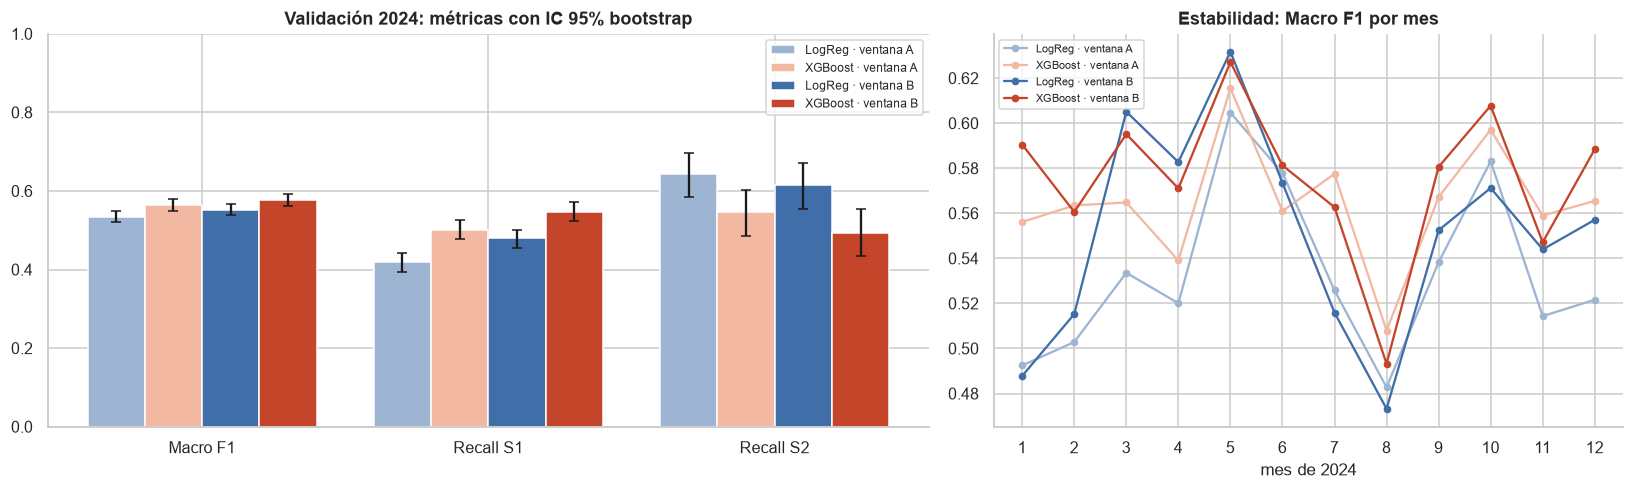

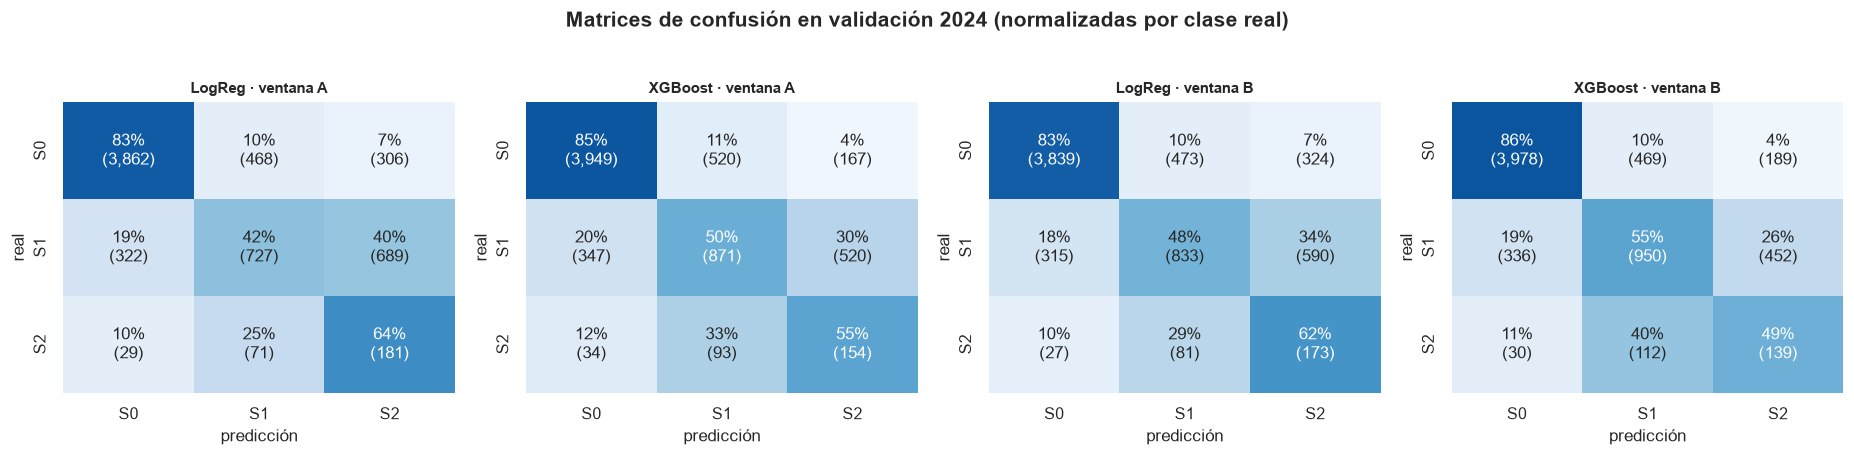

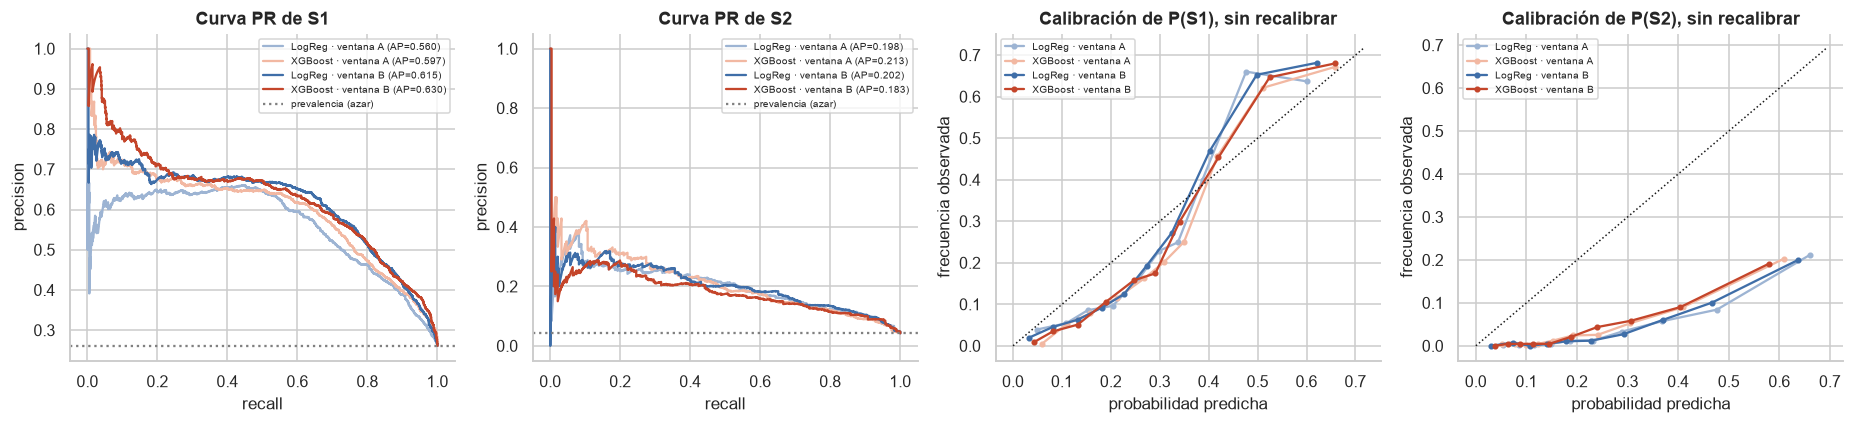

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
metricas_graf = ["Macro F1", "Recall S1", "Recall S2"]
ancho = 0.2
for j, k in enumerate(COMBOS):
    medias = [boot_val[k][m].mean() for m in metricas_graf]
    errores = np.array([np.abs(ic95(boot_val[k][m]) - boot_val[k][m].mean()) for m in metricas_graf]).T
    axes[0].bar(np.arange(3) + (j - 1.5) * ancho, medias, ancho, yerr=errores, capsize=3,
                color=COLOR_COMBO[k], label=ETIQUETA[k])
axes[0].set_xticks(range(3), metricas_graf); axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8)
axes[0].set_title("Validación 2024: métricas con IC 95% bootstrap")
for k in COMBOS:
    axes[1].plot(estabilidad.index, estabilidad[ETIQUETA[k]], "o-", color=COLOR_COMBO[k], label=ETIQUETA[k], ms=4)
axes[1].set_xticks(range(1, 13)); axes[1].set_xlabel("mes de 2024"); axes[1].set_title("Estabilidad: Macro F1 por mes")
axes[1].legend(fontsize=7.5)
plt.tight_layout(); guardar(fig, "05_1_validacion_metricas"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, k in zip(axes, COMBOS):
    cm = confusion_matrix(y_val, resultados[k]["P_val"].argmax(axis=1), labels=[0, 1, 2])
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_pct, annot=np.array([[f"{p:.0%}\n({n:,})" for p, n in zip(fp, fn)] for fp, fn in zip(cm_pct, cm)]),
                fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_title(ETIQUETA[k], fontsize=10); ax.set_xlabel("predicción"); ax.set_ylabel("real")
plt.suptitle("Matrices de confusión en validación 2024 (normalizadas por clase real)", y=1.03, fontweight="bold")
plt.tight_layout(); guardar(fig, "05_1_confusion_validacion"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for col, clase in enumerate([1, 2]):
    ax = axes[col]
    for k in COMBOS:
        p, r, _ = precision_recall_curve(y_val == clase, resultados[k]["P_val"][:, clase])
        ax.plot(r, p, color=COLOR_COMBO[k], label=f"{ETIQUETA[k]} (AP={average_precision_score(y_val == clase, resultados[k]['P_val'][:, clase]):.3f})")
    ax.axhline((y_val == clase).mean(), color="grey", ls=":", label="prevalencia (azar)")
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title(f"Curva PR de {CLASES[clase]}"); ax.legend(fontsize=6.5)
for col, clase in enumerate([1, 2]):
    ax = axes[2 + col]
    for k in COMBOS:
        frac, media = calibration_curve(y_val == clase, resultados[k]["P_val"][:, clase], n_bins=10, strategy="quantile")
        ax.plot(media, frac, "o-", ms=3, color=COLOR_COMBO[k], label=ETIQUETA[k])
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, lim], [0, lim], "k:", lw=1)
    ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("frecuencia observada"); ax.set_title(f"Calibración de P({CLASES[clase]}), sin recalibrar")
    ax.legend(fontsize=6.5)
plt.tight_layout(); guardar(fig, "05_1_pr_calibracion_validacion"); plt.show()

### 5.2 Experimento COVID-19 y comparación de modelos en validación

Diferencias pareadas con bootstrap (mismos remuestreos para ambos modelos). Un intervalo que no incluye 0 indica una diferencia estadísticamente distinguible.

In [29]:
print("Experimento COVID-19: ventana A (con pandemia) menos ventana B (pospandemia), validación 2024")
for modelo in ["LogReg", "XGBoost"]:
    a, b = boot_val[("A", modelo)], boot_val[("B", modelo)]
    print(f"  {modelo:<8} Macro F1: {texto_ic(a['Macro F1'] - b['Macro F1'])} | Recall S2: {texto_ic(a['Recall S2'] - b['Recall S2'], pct=True)}")

# 1) Mejor ventana para cada tipo de modelo: Macro F1 en validación; empate (< 0.005) se decide por estabilidad mensual
def mejor_ventana(modelo):
    candidatos = sorted(VENTANAS, key=lambda v: tabla_val.loc[ETIQUETA[(v, modelo)], "Macro F1"], reverse=True)
    v1, v2 = candidatos
    f1_1, f1_2 = (tabla_val.loc[ETIQUETA[(v, modelo)], "Macro F1"] for v in (v1, v2))
    if f1_1 - f1_2 < 0.005 and tabla_val.loc[ETIQUETA[(v2, modelo)], "Desv. est. mensual F1"] < tabla_val.loc[ETIQUETA[(v1, modelo)], "Desv. est. mensual F1"]:
        return v2
    return v1

ventana_lr, ventana_xgb = mejor_ventana("LogReg"), mejor_ventana("XGBoost")
k_lr, k_xgb = (ventana_lr, "LogReg"), (ventana_xgb, "XGBoost")

# 2) Comparación estadística de los finalistas en validación (la decisión final se toma en la sección 6)
dif_modelo_val = boot_val[k_xgb]["Macro F1"] - boot_val[k_lr]["Macro F1"]
estadistica_ok = ic95(dif_modelo_val)[0] > 0 and dif_modelo_val.mean() >= MEJORA_MINIMA_F1
print(f"\nFinalistas: {ETIQUETA[k_lr]} y {ETIQUETA[k_xgb]}")
print(f"XGBoost menos LogReg, Macro F1 validación: {texto_ic(dif_modelo_val)}")
print(f"Diferencia en recall S2: {texto_ic(boot_val[k_xgb]['Recall S2'] - boot_val[k_lr]['Recall S2'], pct=True)}")
print("Criterio estadístico (IC > 0 y mejora >= MEJORA_MINIMA_F1):", "cumple" if estadistica_ok else "no cumple")
print("La elección del champion se completa en la sección 6 con el costo operativo de priorización.")

Experimento COVID-19: ventana A (con pandemia) menos ventana B (pospandemia), validación 2024
  LogReg   Macro F1: -0.0171 [-0.0255, -0.0060] | Recall S2: +2.9% [-1.5%, +7.3%]
  XGBoost  Macro F1: -0.0112 [-0.0218, +0.0003] | Recall S2: +5.4% [+0.4%, +10.2%]

Finalistas: LogReg · ventana B y XGBoost · ventana B
XGBoost menos LogReg, Macro F1 validación: +0.0243 [+0.0128, +0.0353]
Diferencia en recall S2: -12.1% [-17.6%, -6.8%]
Criterio estadístico (IC > 0 y mejora >= MEJORA_MINIMA_F1): cumple
La elección del champion se completa en la sección 6 con el costo operativo de priorización.


## 6. Calibración y reglas de prioridad (analítica prescriptiva)

Los pesos por clase mejoran el recall de S1 y S2, pero inflan sus probabilidades. Antes de usar el score se recalibran con un **escalamiento de Platt multiclase** ajustado en 2024. Para buscar umbrales sin sobreajustar, las probabilidades calibradas de 2024 se obtienen con validación cruzada de 5 particiones (cada caso se calibra con un modelo que no lo vio); el calibrador final se ajusta con todo 2024.

**Score:** SSE = P(S1) + 2·P(S2), score = 50·SSE (0–100). **Regla:** prioridad alta si P(S2) ≥ *t*<sub>S2</sub> o score ≥ *t*<sub>alta</sub>; media si score ≥ *t*<sub>media</sub>; baja en otro caso. Los umbrales minimizan el costo relativo promedio de la matriz `COSTO_ERROR` sujeto a que la prioridad alta no supere `CAPACIDAD_ALTA`.

In [30]:
C_MAT = COSTO_ERROR.loc[CLASES, PRIORIDADES].to_numpy()

def evaluar_umbrales(P, y, umbrales):
    prioridad = sf.asignar_prioridad(P, umbrales)
    idx_p = pd.Series(prioridad).map({p: i for i, p in enumerate(PRIORIDADES)}).to_numpy()
    return {"costo": C_MAT[y, idx_p].mean(), "% alta": (prioridad == "Alta").mean(), "% media": (prioridad == "Media").mean(),
            "S2 en alta": (prioridad[y == 2] == "Alta").mean(), "S1+S2 en media o alta": (prioridad[y > 0] != "Baja").mean(),
            "S1+S2 en baja": (prioridad[y > 0] == "Baja").mean()}

def calibrar_y_umbralizar(P_modelo, y):
    # Probabilidades calibradas fuera de pliegue (para buscar umbrales) y calibrador final con todo el año de validación
    P_oof = np.zeros_like(P_modelo)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(P_modelo, y):
        P_oof[te] = sf.CalibradorMultinomial().fit(P_modelo[tr], y[tr]).transform(P_modelo[te])
    score = sf.score_severidad(P_oof)
    cand_media = np.unique(np.quantile(score, np.linspace(0.20, 0.90, 29)))
    cand_alta = np.unique(np.quantile(score, np.linspace(0.60, 0.995, 30)))
    cand_ps2 = [np.inf, *np.quantile(P_oof[:, 2], [0.90, 0.95, 0.98])]
    filas = []
    for ps2 in cand_ps2:
        for t_a in cand_alta:
            for t_m in cand_media[cand_media < t_a]:
                u = {"p_s2_alta": ps2, "score_alta": t_a, "score_media": t_m}
                filas.append({**u, **evaluar_umbrales(P_oof, y, u)})
    busqueda = pd.DataFrame(filas)
    mejor = busqueda[busqueda["% alta"] <= CAPACIDAD_ALTA].sort_values(["costo", "% alta"]).iloc[0]
    return {"calibrador": sf.CalibradorMultinomial().fit(P_modelo, y), "P_oof": P_oof, "busqueda": busqueda, "mejor": mejor,
            "umbrales": {k: float(mejor[k]) for k in ["p_s2_alta", "score_alta", "score_media"]}}

operativo = {k: calibrar_y_umbralizar(resultados[k]["P_val"], y_val) for k in (k_lr, k_xgb)}
finalistas = pd.DataFrame({ETIQUETA[k]: {"Macro F1": tabla_val.loc[ETIQUETA[k], "Macro F1"], **operativo[k]["mejor"].drop(["p_s2_alta", "score_alta", "score_media"]).to_dict()}
                           for k in operativo}).T
display(finalistas.style.format(precision=3))

# H1_modelo en validación: mejora estadística en Macro F1 Y menor costo operativo de priorización (sección 7.5 y 14)
operativo_ok = operativo[k_xgb]["mejor"]["costo"] < operativo[k_lr]["mejor"]["costo"]
xgb_gana = estadistica_ok and operativo_ok
CHAMPION = k_xgb if xgb_gana else k_lr
print(f"Criterio estadístico: {'cumple' if estadistica_ok else 'no cumple'} | "
      f"criterio operativo (menor costo de priorización): {'cumple' if operativo_ok else 'no cumple'}")
print(f"\nCHAMPION: {ETIQUETA[CHAMPION]}  ->  "
      + ("XGBoost mejora de forma estadística y operacionalmente relevante." if xgb_gana else
         "XGBoost no cumple ambos criterios; se prefiere el modelo simple por interpretabilidad y mantenimiento (sección 1.3)."))

clf_champion = resultados[CHAMPION]["clf"]
P_val_modelo = resultados[CHAMPION]["P_val"]
calibrador, P_val_cal = operativo[CHAMPION]["calibrador"], operativo[CHAMPION]["P_oof"]
busqueda, mejor, UMBRALES = operativo[CHAMPION]["busqueda"], operativo[CHAMPION]["mejor"], operativo[CHAMPION]["umbrales"]
score_val = sf.score_severidad(P_val_cal)
print("Umbrales del champion:", {k: (round(v, 4) if np.isfinite(v) else "sin regla P(S2)") for k, v in UMBRALES.items()})

,Macro F1,costo,% alta,% media,S2 en alta,S1+S2 en media o alta,S1+S2 en baja
LogReg · ventana B,0.552,0.653,0.144,0.231,0.612,0.837,0.163
XGBoost · ventana B,0.576,0.645,0.148,0.227,0.584,0.843,0.157


Criterio estadístico: cumple | criterio operativo (menor costo de priorización): cumple

CHAMPION: XGBoost · ventana B  ->  XGBoost mejora de forma estadística y operacionalmente relevante.
Umbrales del champion: {'p_s2_alta': 0.1396, 'score_alta': 50.2406, 'score_media': 10.7543}


In [31]:
comparacion_cal = pd.DataFrame({
    "Sin recalibrar": {"Log loss": log_loss(y_val, P_val_modelo), **{f"Brier {c}": brier_score_loss(y_val == i, P_val_modelo[:, i]) for i, c in enumerate(CLASES)},
                       **{f"P media {c}": P_val_modelo[:, i].mean() for i, c in enumerate(CLASES)}},
    "Recalibrado (fuera de pliegue)": {"Log loss": log_loss(y_val, P_val_cal), **{f"Brier {c}": brier_score_loss(y_val == i, P_val_cal[:, i]) for i, c in enumerate(CLASES)},
                                       **{f"P media {c}": P_val_cal[:, i].mean() for i, c in enumerate(CLASES)}},
    "Frecuencia observada 2024": {"Log loss": np.nan, **{f"Brier {c}": np.nan for c in CLASES},
                                  **{f"P media {c}": (y_val == i).mean() for i, c in enumerate(CLASES)}},
})
print(f"Calibración del champion ({ETIQUETA[CHAMPION]}) en validación 2024:")
display(comparacion_cal.style.format(precision=4, na_rep="—"))

Calibración del champion (XGBoost · ventana B) en validación 2024:


,Sin recalibrar,Recalibrado (fuera de pliegue),Frecuencia observada 2024
Log loss,0.6555,0.4367,—
Brier S0,0.1536,0.0979,—
Brier S1,0.1409,0.1134,—
Brier S2,0.0792,0.0367,—
P media S0,0.4907,0.6965,0.6966
P media S1,0.2928,0.2612,0.2612
P media S2,0.2165,0.0423,0.0422


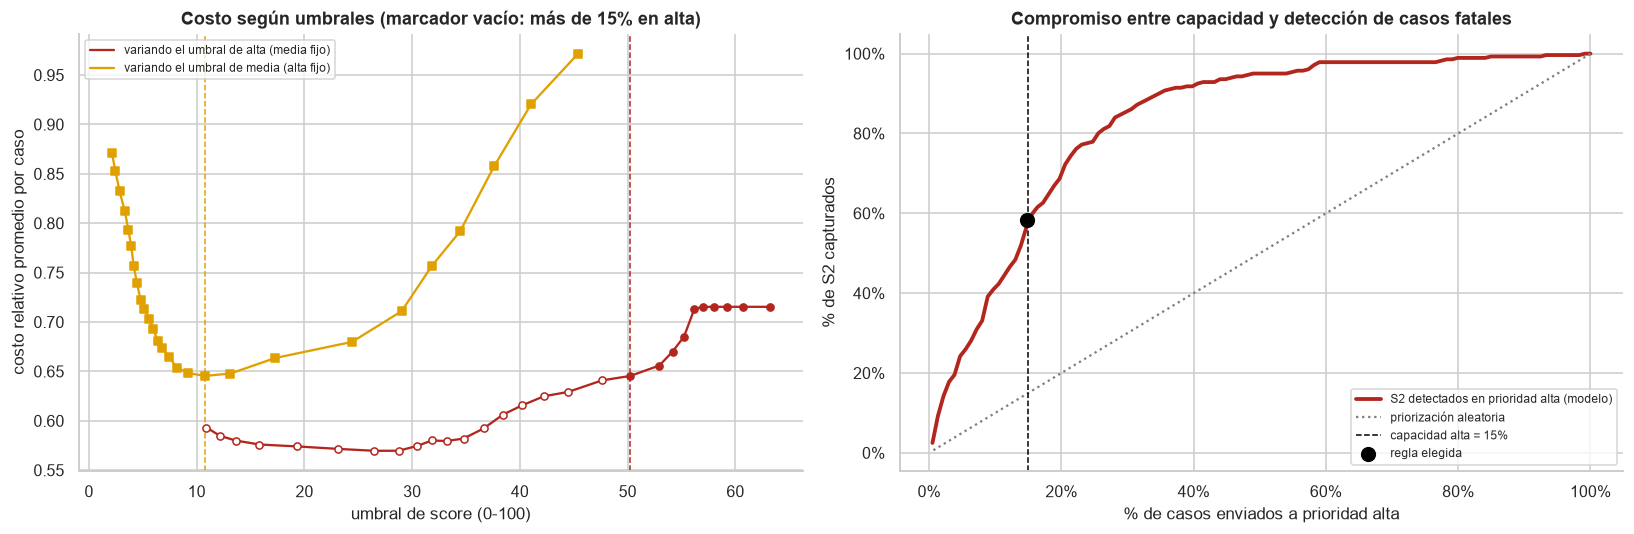

prioridad,Baja,Media,Alta
severidad real,,,
S0,82.9%,16.0%,1.1%
S1,16.8%,38.7%,44.5%
S2,8.5%,33.1%,58.4%


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sub = busqueda[busqueda["p_s2_alta"] == UMBRALES["p_s2_alta"]]
for col_var, col_fijo, color, marca, etiqueta in [("score_alta", "score_media", COLOR["S2"], "o", "variando el umbral de alta (media fijo)"),
                                                  ("score_media", "score_alta", COLOR["S1"], "s", "variando el umbral de media (alta fijo)")]:
    linea = sub[np.isclose(sub[col_fijo], UMBRALES[col_fijo])].sort_values(col_var)
    ok = linea["% alta"] <= CAPACIDAD_ALTA
    axes[0].plot(linea[col_var], linea["costo"], "-", color=color, lw=1.5, label=etiqueta)
    axes[0].scatter(linea.loc[ok, col_var], linea.loc[ok, "costo"], color=color, marker=marca, s=22, zorder=3)
    axes[0].scatter(linea.loc[~ok, col_var], linea.loc[~ok, "costo"], facecolors="white", edgecolors=color, marker=marca, s=22, zorder=3)
    axes[0].axvline(UMBRALES[col_var], color=color, ls="--", lw=1)
axes[0].set_xlabel("umbral de score (0-100)"); axes[0].set_ylabel("costo relativo promedio por caso")
axes[0].set_title(f"Costo según umbrales (marcador vacío: más de {CAPACIDAD_ALTA:.0%} en alta)"); axes[0].legend(fontsize=8)

curva = [evaluar_umbrales(P_val_cal, y_val, {"p_s2_alta": np.inf, "score_alta": t, "score_media": t}) for t in np.quantile(score_val, np.linspace(0, 0.995, 120))]
curva = pd.DataFrame(curva)
azar = curva["% alta"]
axes[1].plot(curva["% alta"], curva["S2 en alta"], color=COLOR["S2"], lw=2.5, label="S2 detectados en prioridad alta (modelo)")
axes[1].plot(azar, azar, ":", color="grey", label="priorización aleatoria")
axes[1].axvline(CAPACIDAD_ALTA, color="black", ls="--", lw=1, label=f"capacidad alta = {CAPACIDAD_ALTA:.0%}")
axes[1].scatter([mejor["% alta"]], [mejor["S2 en alta"]], s=80, color="black", zorder=3, label="regla elegida")
formato_pct(axes[1]); formato_pct(axes[1], "x"); axes[1].legend(fontsize=8)
axes[1].set_xlabel("% de casos enviados a prioridad alta"); axes[1].set_ylabel("% de S2 capturados")
axes[1].set_title("Compromiso entre capacidad y detección de casos fatales")
plt.tight_layout(); guardar(fig, "06_umbrales"); plt.show()

prio_val = sf.asignar_prioridad(P_val_cal, UMBRALES)
tabla_prio_val = pd.crosstab(pd.Series(np.array(CLASES)[y_val], name="severidad real"),
                             pd.Series(prio_val, name="prioridad"), normalize="index")[PRIORIDADES]
display(tabla_prio_val.style.format("{:.1%}").background_gradient(cmap="Greens", axis=None))

## 7. Prueba final 2025 y contraste de hipótesis

A partir de aquí se abre 2025. Todas las decisiones anteriores quedan fijas: champion, ventana, hiperparámetros, calibrador y umbrales.

- La **clase probable** (para recall, precision, F1 y matriz de confusión) es el argmax del modelo entrenado con pesos balanceados.
- El **score y la prioridad** se calculan con las probabilidades recalibradas.

In [33]:
P_test = {k: r["clf"].predict_proba(raw_test) for k, r in resultados.items()}
P_test_modelo = P_test[CHAMPION]
P_test_cal = calibrador.transform(P_test_modelo)

# Baselines de H0: distribución histórica de clases de la ventana del champion
prior = np.bincount(raw_train[CHAMPION[0]]["y"], minlength=3) / len(raw_train[CHAMPION[0]])
P_prior = np.tile(prior, (len(y_test), 1))
rng_base = np.random.default_rng(SEED)
yhat_estratificado = rng_base.choice(3, size=len(y_test), p=prior)
yhat_mayoritaria = np.zeros(len(y_test), dtype=int)

tabla_test = pd.DataFrame({ETIQUETA[k]: metricas(y_test, P) for k, P in P_test.items()}).T
tabla_test.loc["Baseline: clase mayoritaria"] = metricas(y_test, P_prior, yhat_mayoritaria)
tabla_test.loc["Baseline: aleatorio según distribución histórica"] = metricas(y_test, P_prior, yhat_estratificado)
tabla_test.loc[f"{ETIQUETA[CHAMPION]} recalibrado (probabilidades)", ["Log loss", "PR-AUC S1", "PR-AUC S2", "ROC-AUC víctimas"]] = \
    [log_loss(y_test, P_test_cal), average_precision_score(y_test == 1, P_test_cal[:, 1]),
     average_precision_score(y_test == 2, P_test_cal[:, 2]), roc_auc_score(y_test > 0, P_test_cal[:, 1] + P_test_cal[:, 2])]
display(tabla_test.style.format(precision=4, na_rep="—"))

,Macro F1,Recall S0,Recall S1,Recall S2,Precision S0,Precision S1,Precision S2,PR-AUC S1,PR-AUC S2,ROC-AUC víctimas,Log loss
LogReg · ventana A,0.5361,0.8094,0.4391,0.6226,0.8990,0.5893,0.1589,0.5876,0.2268,0.9027,0.7677
XGBoost · ventana A,0.5645,0.8352,0.5199,0.5136,0.8981,0.6102,0.1798,0.6285,0.2030,0.9031,0.7152
LogReg · ventana B,0.5401,0.8003,0.4764,0.5759,0.9007,0.5984,0.1534,0.6187,0.2224,0.9011,0.7497
XGBoost · ventana B,0.5684,0.8290,0.5498,0.4864,0.8977,0.6243,0.1761,0.6396,0.1922,0.8996,0.7020
Baseline: clase mayoritaria,0.2618,1.0000,0.0000,0.0000,0.6464,0.0000,0.0000,0.3048,0.0487,0.5000,0.8039
Baseline: aleatorio según distribución histórica,0.3283,0.7179,0.2388,0.0350,0.6400,0.3028,0.0495,0.3048,0.0487,0.5000,0.8039
XGBoost · ventana B recalibrado (probabilidades),—,—,—,—,—,—,—,0.7438,0.1950,0.8994,0.4963


In [34]:
preds_test = {**{k: P.argmax(axis=1) for k, P in P_test.items()}, "estratificado": yhat_estratificado, "mayoritaria": yhat_mayoritaria}
boot_test, idx_test = bootstrap_predicciones(y_test, preds_test)

# H0 vs H1: señal predictiva frente al baseline de distribución histórica
dif_f1_h0 = boot_test[CHAMPION]["Macro F1"] - boot_test["estratificado"]["Macro F1"]
ll_i_modelo = -np.log(np.clip(P_test_cal[np.arange(len(y_test)), y_test], 1e-7, 1))
ll_i_prior = -np.log(prior[y_test])
dif_ll = (ll_i_prior - ll_i_modelo)[idx_test].mean(axis=1)   # > 0: el modelo reduce el log loss
rechaza_h0 = ic95(dif_f1_h0)[0] > 0 and ic95(dif_ll)[0] > 0

# H0_modelo: XGBoost vs LogReg (mejor ventana de cada uno, elegida en validación)
dif_f1_modelo = boot_test[k_xgb]["Macro F1"] - boot_test[k_lr]["Macro F1"]
dif_r2_modelo = boot_test[k_xgb]["Recall S2"] - boot_test[k_lr]["Recall S2"]

def costo_por_caso(k):
    P = operativo[k]["calibrador"].transform(P_test[k])
    prioridad = pd.Series(sf.asignar_prioridad(P, operativo[k]["umbrales"])).map({p: i for i, p in enumerate(PRIORIDADES)}).to_numpy()
    return C_MAT[y_test, prioridad]

dif_costo_modelo = (costo_por_caso(k_lr) - costo_por_caso(k_xgb))[idx_test].mean(axis=1)   # > 0: XGBoost cuesta menos
rechaza_h0_modelo = ic95(dif_f1_modelo)[0] > 0 and dif_f1_modelo.mean() >= MEJORA_MINIMA_F1 and ic95(dif_costo_modelo)[0] > 0

# Experimento COVID en prueba, para el tipo de modelo del champion
dif_covid = boot_test[("A", CHAMPION[1])]["Macro F1"] - boot_test[("B", CHAMPION[1])]["Macro F1"]

print("H0 vs H1 (prueba 2025)")
print(f"  Macro F1 champion − baseline aleatorio histórico: {texto_ic(dif_f1_h0)}")
print(f"  Reducción de log loss vs distribución histórica:   {texto_ic(dif_ll)}")
print(f"  -> {'Se rechaza H0: las variables del primer aviso sí contienen señal predictiva.' if rechaza_h0 else 'No hay evidencia suficiente para rechazar H0.'}")
print("\nH0_modelo vs H1_modelo (prueba 2025)")
print(f"  Macro F1 XGBoost − LogReg: {texto_ic(dif_f1_modelo)} | Recall S2: {texto_ic(dif_r2_modelo, pct=True)}")
print(f"  Reducción del costo de priorización por caso (LogReg − XGBoost): {texto_ic(dif_costo_modelo)}")
print(f"  -> {'Se rechaza H0_modelo: XGBoost mejora de forma estadística y operacionalmente relevante.' if rechaza_h0_modelo else 'No se rechaza H0_modelo: la mejora de XGBoost no es relevante con el criterio definido.'}")
print(f"\nExperimento COVID-19 ({CHAMPION[1]}): Macro F1 ventana A − ventana B en 2025: {texto_ic(dif_covid)}")
print("  -> " + ("La historia con pandemia mejora la generalización." if ic95(dif_covid)[0] > 0 else
                 "Entrenar sólo con años pospandemia generaliza mejor." if ic95(dif_covid)[1] < 0 else
                 "No hay diferencia distinguible: incluir la pandemia ni ayuda ni perjudica de forma clara."))

H0 vs H1 (prueba 2025)
  Macro F1 champion − baseline aleatorio histórico: +0.2404 [+0.2197, +0.2593]
  Reducción de log loss vs distribución histórica:   +0.3077 [+0.2902, +0.3259]
  -> Se rechaza H0: las variables del primer aviso sí contienen señal predictiva.

H0_modelo vs H1_modelo (prueba 2025)
  Macro F1 XGBoost − LogReg: +0.0283 [+0.0162, +0.0398] | Recall S2: -8.9% [-14.3%, -3.9%]
  Reducción del costo de priorización por caso (LogReg − XGBoost): +0.0277 [+0.0007, +0.0534]
  -> Se rechaza H0_modelo: XGBoost mejora de forma estadística y operacionalmente relevante.

Experimento COVID-19 (XGBoost): Macro F1 ventana A − ventana B en 2025: -0.0037 [-0.0150, +0.0081]
  -> No hay diferencia distinguible: incluir la pandemia ni ayuda ni perjudica de forma clara.


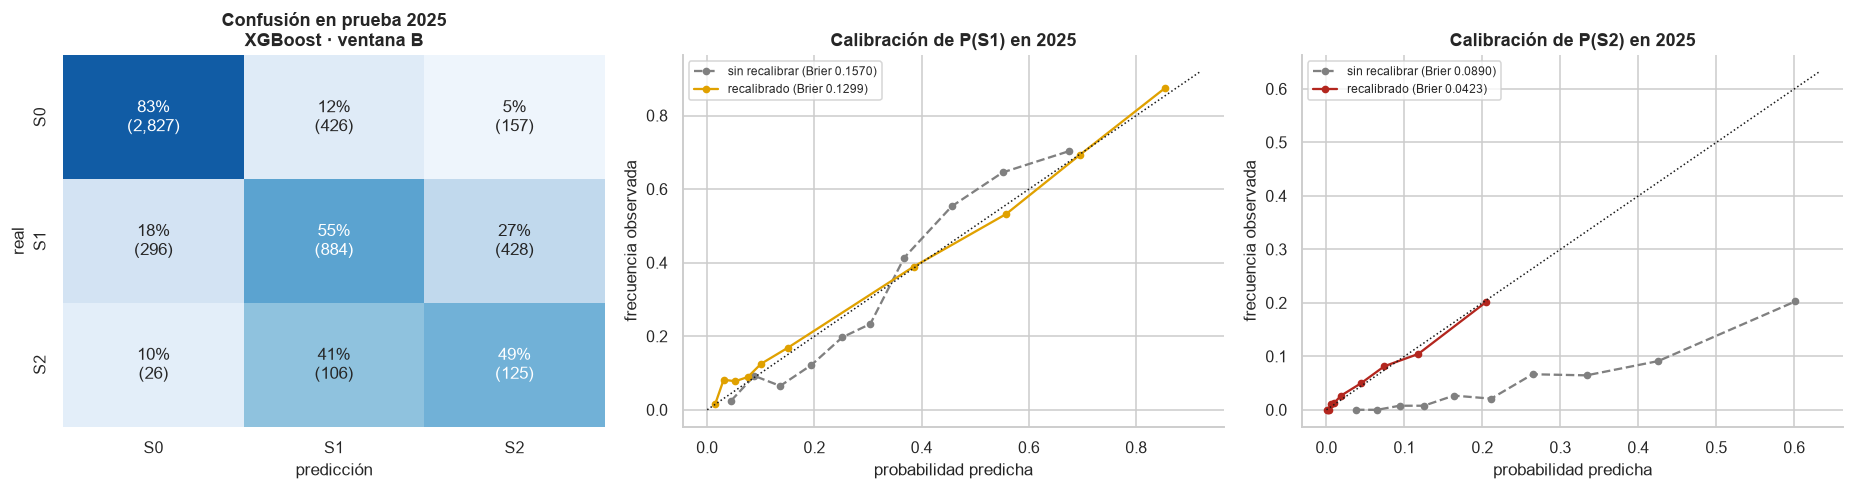

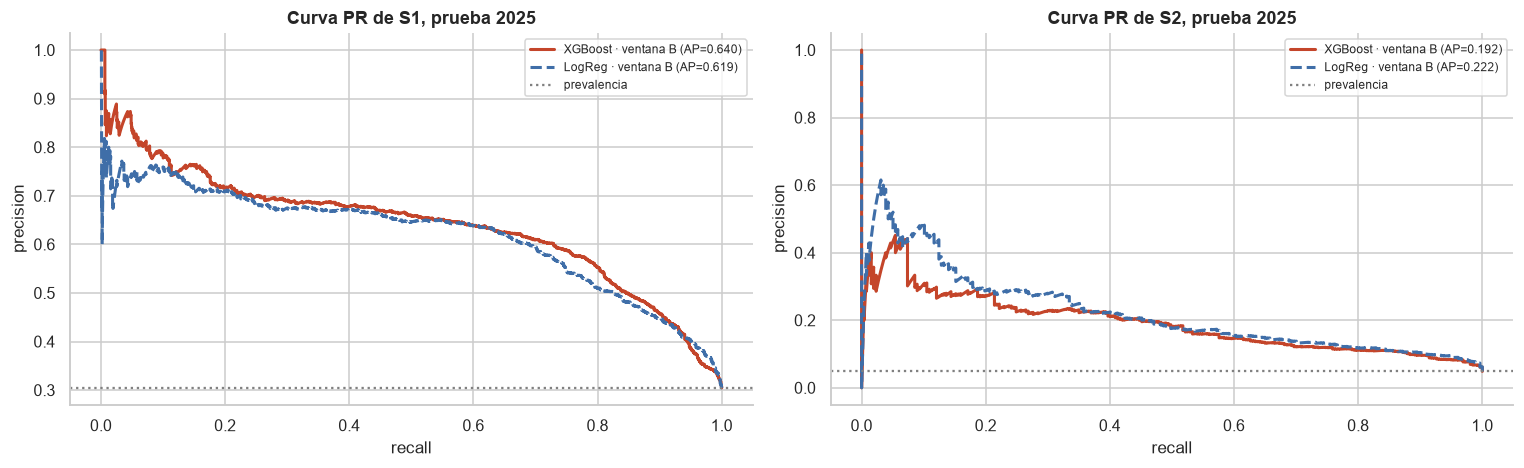

Macro F1 por mes en 2025 (estabilidad): 0.58 0.51 0.54 0.62 0.60 0.60 0.61 0.57 0.55 0.52 0.54 0.56


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
cm = confusion_matrix(y_test, P_test_modelo.argmax(axis=1), labels=[0, 1, 2])
cm_pct = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_pct, annot=np.array([[f"{p:.0%}\n({n:,})" for p, n in zip(fp, fn)] for fp, fn in zip(cm_pct, cm)]), fmt="",
            cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=CLASES, yticklabels=CLASES, ax=axes[0])
axes[0].set_title(f"Confusión en prueba 2025\n{ETIQUETA[CHAMPION]}"); axes[0].set_xlabel("predicción"); axes[0].set_ylabel("real")

for i, clase in enumerate([1, 2]):
    ax = axes[1 + i]
    for P, nombre, estilo in [(P_test_modelo, "sin recalibrar", "o--"), (P_test_cal, "recalibrado", "o-")]:
        frac, media = calibration_curve(y_test == clase, P[:, clase], n_bins=10, strategy="quantile")
        ax.plot(media, frac, estilo, ms=4, color=COLOR[CLASES[clase]] if nombre == "recalibrado" else "grey",
                label=f"{nombre} (Brier {brier_score_loss(y_test == clase, P[:, clase]):.4f})")
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, lim], [0, lim], "k:", lw=1)
    ax.set_title(f"Calibración de P({CLASES[clase]}) en 2025"); ax.set_xlabel("probabilidad predicha")
    ax.set_ylabel("frecuencia observada"); ax.legend(fontsize=8)
plt.tight_layout(); guardar(fig, "07_prueba_confusion_calibracion"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for col, clase in enumerate([1, 2]):
    ax = axes[col]
    for k, estilo in [(CHAMPION, "-"), (k_lr if CHAMPION != k_lr else k_xgb, "--")]:
        p, r, _ = precision_recall_curve(y_test == clase, P_test[k][:, clase])
        ax.plot(r, p, estilo, color=COLOR_COMBO[k], lw=2, label=f"{ETIQUETA[k]} (AP={average_precision_score(y_test == clase, P_test[k][:, clase]):.3f})")
    ax.axhline((y_test == clase).mean(), color="grey", ls=":", label="prevalencia")
    ax.set_title(f"Curva PR de {CLASES[clase]}, prueba 2025"); ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(fontsize=8)
plt.tight_layout(); guardar(fig, "07_prueba_pr"); plt.show()

mes_test = raw_test["MES"].to_numpy()
f1_mes = [f1_score(y_test[mes_test == m], P_test_modelo[mes_test == m].argmax(axis=1), average="macro") for m in range(1, 13)]
print("Macro F1 por mes en 2025 (estabilidad):", " ".join(f"{v:.2f}" for v in f1_mes))

,Modelo,Aleatorio con la misma capacidad,Sin triage (todo prioridad media)
S2 en prioridad alta,0.572,0.167,0.000
S1/S2 subpriorizados (baja),0.156,0.578,0.000
Costo relativo por caso,0.739,1.851,1.341


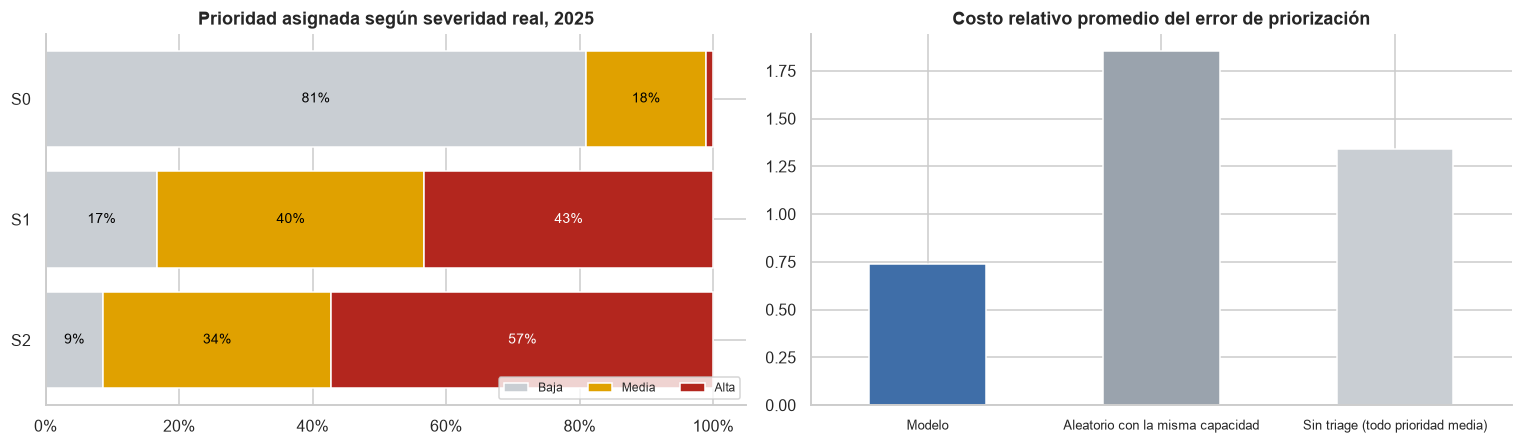

In [36]:
prio_test = sf.asignar_prioridad(P_test_cal, UMBRALES)
idx_prio = pd.Series(prio_test).map({p: i for i, p in enumerate(PRIORIDADES)}).to_numpy()
reparto = np.bincount(idx_prio, minlength=3) / len(idx_prio)

costo_modelo = C_MAT[y_test, idx_prio].mean()
costo_aleatorio = (C_MAT[y_test] * reparto).sum(axis=1).mean()   # mismo reparto de prioridades, asignado al azar
costo_todo_media = C_MAT[y_test, 1].mean()                         # sin triage: todos los casos iguales
kpis_prio = pd.DataFrame({
    "Modelo": {"S2 en prioridad alta": (prio_test[y_test == 2] == "Alta").mean(),
               "S1/S2 subpriorizados (baja)": (prio_test[y_test > 0] == "Baja").mean(),
               "Costo relativo por caso": costo_modelo},
    "Aleatorio con la misma capacidad": {"S2 en prioridad alta": reparto[2],
                                         "S1/S2 subpriorizados (baja)": reparto[0],
                                         "Costo relativo por caso": costo_aleatorio},
    "Sin triage (todo prioridad media)": {"S2 en prioridad alta": 0.0, "S1/S2 subpriorizados (baja)": 0.0,
                                          "Costo relativo por caso": costo_todo_media},
})
display(kpis_prio.style.format("{:.3f}"))

tabla_prio = pd.crosstab(pd.Series(np.array(CLASES)[y_test], name="severidad real"), pd.Series(prio_test, name="prioridad"))[PRIORIDADES]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
pct = tabla_prio.div(tabla_prio.sum(axis=1), axis=0)
abajo = np.zeros(3)
for p, color in zip(PRIORIDADES, ["#C9CED3", "#E0A100", "#B3261E"]):
    axes[0].barh(CLASES, pct[p], left=abajo, color=color, label=p)
    for i, (b, v) in enumerate(zip(abajo, pct[p])):
        if v > 0.04: axes[0].text(b + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if p == "Alta" else "black")
    abajo += pct[p].values
axes[0].invert_yaxis(); formato_pct(axes[0], "x"); axes[0].legend(ncol=3, fontsize=8, loc="lower right")
axes[0].set_title("Prioridad asignada según severidad real, 2025")
kpis_prio.loc["Costo relativo por caso"].plot(kind="bar", ax=axes[1], color=["#3F6EA8", "#9AA3AD", "#C9CED3"], rot=0)
axes[1].set_title("Costo relativo promedio del error de priorización"); axes[1].tick_params(axis="x", labelsize=8.5)
plt.tight_layout(); guardar(fig, "07_prioridades_prueba"); plt.show()

## 8. Explicabilidad con SHAP

SHAP estima cuánto aporta cada variable a la predicción de cada clase (en escala log-odds del modelo). Se aplica al mejor XGBoost. Las contribuciones describen el comportamiento del modelo y **no son efectos causales**. Las variables numéricas aparecen estandarizadas.

/Users/humbertoangelplataduran/Documents/proyecto-final-data-science/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Forma de los valores SHAP (casos, variables, clases): (2000, 67, 3)


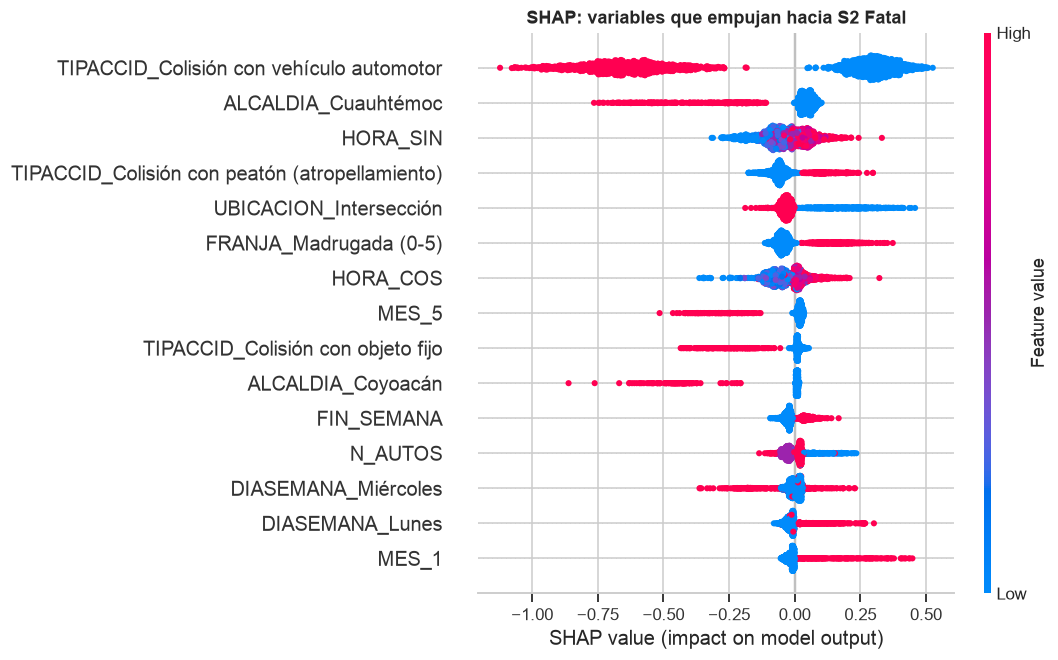

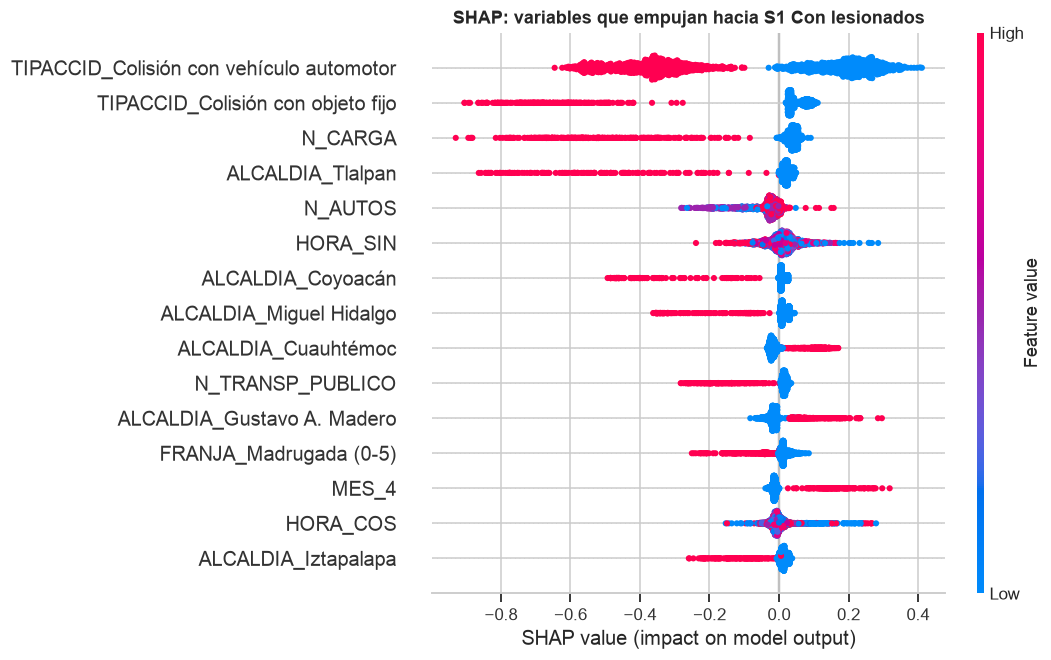

In [37]:
# [SHAP]
import shap
clf_xgb = resultados[k_xgb]["clf"]
muestra = raw_test.sample(min(2000, len(raw_test)), random_state=SEED)
nombres = list(clf_xgb.preprocesador.get_feature_names_out())
X_shap = pd.DataFrame(clf_xgb.transformar(muestra), columns=nombres, index=muestra.index)
explicador = shap.TreeExplainer(clf_xgb.modelo)
valores_shap = explicador.shap_values(X_shap)
valores_shap = np.stack(valores_shap, axis=-1) if isinstance(valores_shap, list) else np.asarray(valores_shap)
print("Forma de los valores SHAP (casos, variables, clases):", valores_shap.shape)

for clase in [2, 1]:
    shap.summary_plot(valores_shap[:, :, clase], X_shap, max_display=15, show=False, plot_size=(10, 6))
    plt.title(f"SHAP: variables que empujan hacia {NOMBRE_CLASE[CLASES[clase]]}", fontweight="bold")
    guardar(plt.gcf(), f"08_shap_{CLASES[clase]}"); plt.show()

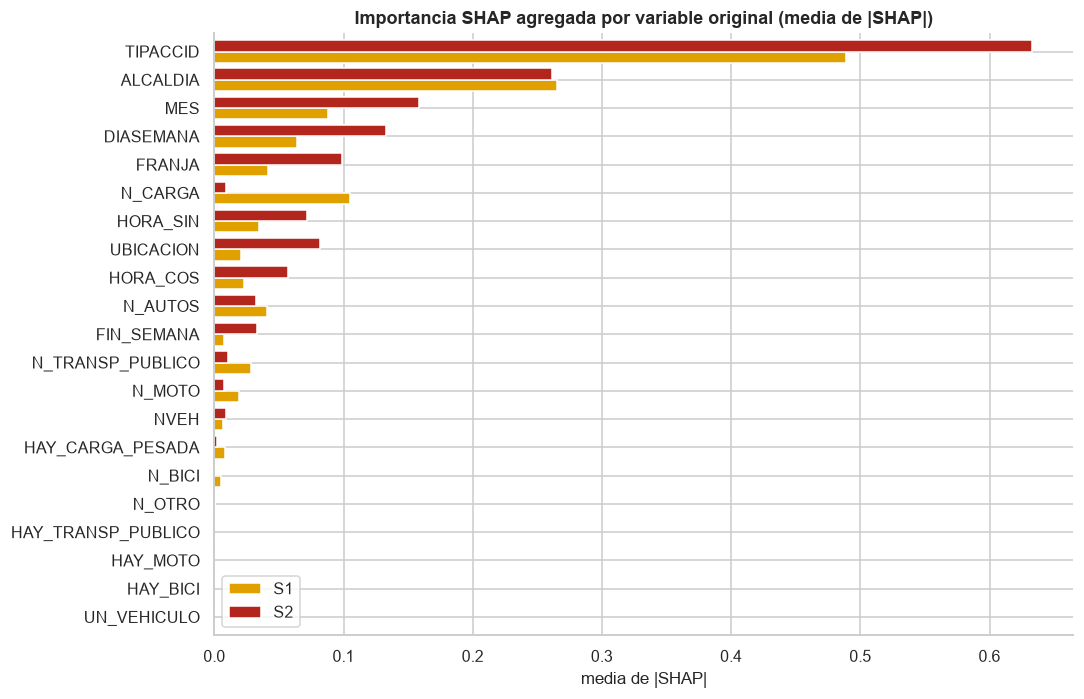

Caso con mayor P(S2) en la muestra: Cuajimalpa de Morelos, Jueves 01:00, Volcadura | severidad real: S2


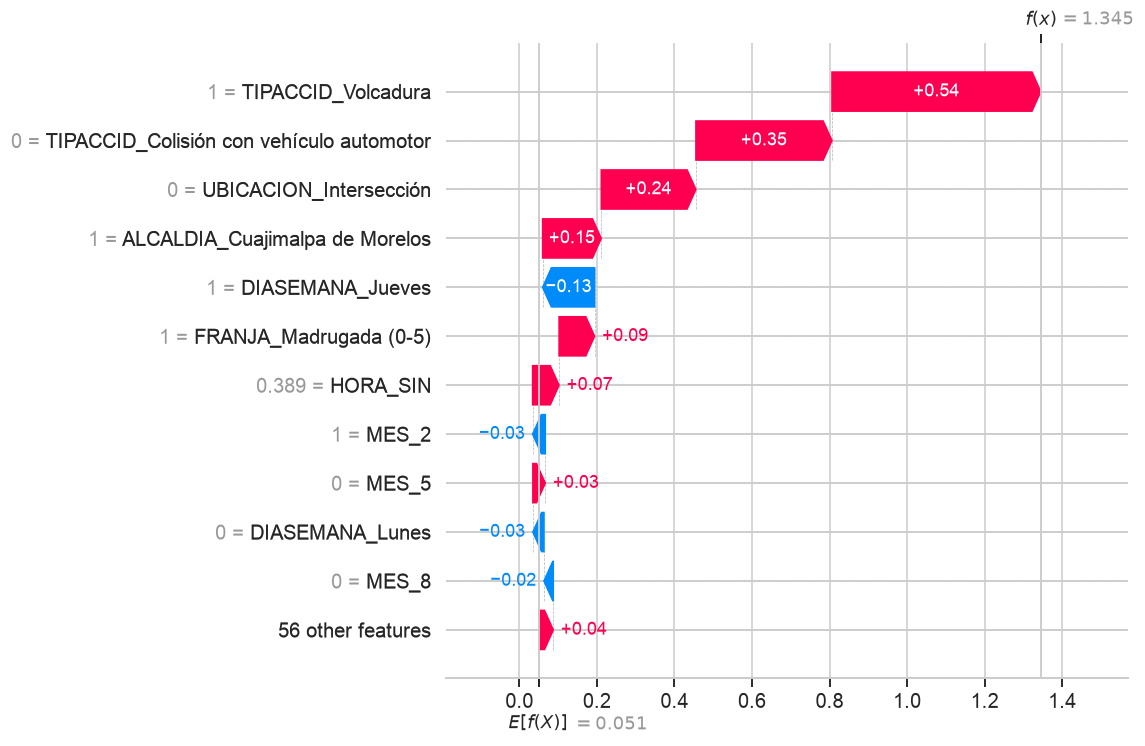

In [38]:
# [SHAP]
def variable_original(nombre):
    return next((c for c in sf.FEATURES_CAT if nombre.startswith(c + "_")), nombre)

grupos = pd.Series([variable_original(n) for n in nombres], index=nombres)
importancia = pd.DataFrame({CLASES[k]: pd.Series(np.abs(valores_shap[:, :, k]).mean(axis=0), index=nombres).groupby(grupos).sum()
                            for k in range(3)})
importancia = importancia.loc[importancia[["S1", "S2"]].sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 6.5))
importancia[["S1", "S2"]].plot(kind="barh", color=[COLOR["S1"], COLOR["S2"]], ax=ax, width=0.8)
ax.set_title("Importancia SHAP agregada por variable original (media de |SHAP|)"); ax.set_xlabel("media de |SHAP|")
plt.tight_layout(); guardar(fig, "08_shap_importancia_agregada"); plt.show()

i = int(np.argmax(clf_xgb.predict_proba(muestra)[:, 2]))
base_s2 = np.atleast_1d(explicador.expected_value)[2]
explicacion = shap.Explanation(values=valores_shap[i, :, 2], base_values=base_s2, data=X_shap.iloc[i].values, feature_names=nombres)
caso = muestra.iloc[i]
print(f"Caso con mayor P(S2) en la muestra: {caso['ALCALDIA']}, {caso['DIASEMANA']} {int(caso['ID_HORA']):02d}:00, "
      f"{caso['TIPACCID']} | severidad real: {caso['SEVERIDAD']}")
shap.plots.waterfall(explicacion, max_display=12, show=False)
guardar(plt.gcf(), "08_shap_caso_individual"); plt.show()

## 9. Carga esperada de severidad y distribución de ajustadores

### 9.1 Agregación de las predicciones (sección 9)

Sumar las probabilidades calibradas por alcaldía y franja da una estimación de cuántos casos con víctimas esperar. Se compara con lo observado en 2025 para validar que la agregación es útil para planear.

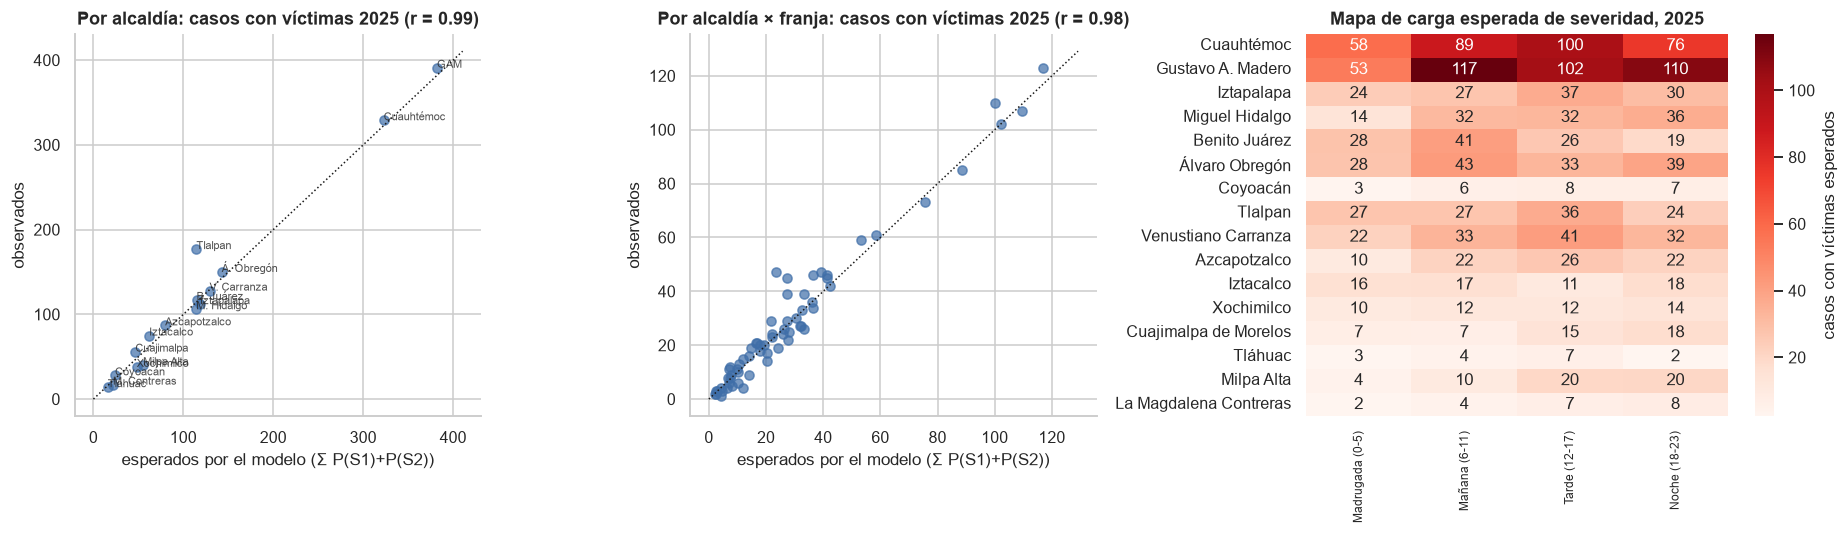

Total esperado de casos con víctimas: 1,792 vs observado 1,865
Error relativo medio absoluto por alcaldía: 14.0%


In [39]:
F_test = sf.construir_features(raw_test)
agregado = pd.DataFrame({"ALCALDIA": F_test["ALCALDIA"].values, "FRANJA": F_test["FRANJA"].values,
                         "esperado_victimas": P_test_cal[:, 1] + P_test_cal[:, 2], "observado_victimas": (y_test > 0).astype(int),
                         "esperado_S2": P_test_cal[:, 2], "observado_S2": (y_test == 2).astype(int)})
por_alcaldia = agregado.groupby("ALCALDIA")[["esperado_victimas", "observado_victimas", "esperado_S2", "observado_S2"]].sum()
por_celda = agregado.groupby(["ALCALDIA", "FRANJA"])[["esperado_victimas", "observado_victimas"]].sum()

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, datos, titulo in [(axes[0], por_alcaldia, "Por alcaldía"), (axes[1], por_celda, "Por alcaldía × franja")]:
    ax.scatter(datos["esperado_victimas"], datos["observado_victimas"], color="#3F6EA8", alpha=0.7)
    lim = max(datos.max()) * 1.05; ax.plot([0, lim], [0, lim], "k:", lw=1)
    r = np.corrcoef(datos["esperado_victimas"], datos["observado_victimas"])[0, 1]
    ax.set_title(f"{titulo}: casos con víctimas 2025 (r = {r:.2f})")
    ax.set_xlabel("esperados por el modelo (Σ P(S1)+P(S2))"); ax.set_ylabel("observados")
for alcaldia, fila in por_alcaldia.iterrows():
    axes[0].annotate(ABREV.get(alcaldia, alcaldia), (fila["esperado_victimas"], fila["observado_victimas"]), fontsize=7, alpha=0.8)
carga = por_celda["esperado_victimas"].unstack().reindex(columns=sf.FRANJAS).reindex(alc.index)
sns.heatmap(carga, annot=True, fmt=".0f", cmap="Reds", ax=axes[2], cbar_kws={"label": "casos con víctimas esperados"})
axes[2].set_title("Mapa de carga esperada de severidad, 2025"); axes[2].set_xlabel(""); axes[2].set_ylabel("")
axes[2].tick_params(axis="x", labelsize=8)
plt.tight_layout(); guardar(fig, "09_1_carga_esperada"); plt.show()

err = (por_alcaldia["esperado_victimas"] / por_alcaldia["observado_victimas"] - 1)
print(f"Total esperado de casos con víctimas: {por_alcaldia['esperado_victimas'].sum():,.0f} vs observado {por_alcaldia['observado_victimas'].sum():,}")
print(f"Error relativo medio absoluto por alcaldía: {err.abs().mean():.1%}")

### 9.2 Simulación de distribución de ajustadores (sección 10)

Se compara cómo se reparten los ajustadores entre alcaldías en cada franja de 6 horas bajo tres estrategias planeadas con información de **2024**, y se evalúan contra la demanda de **2025**:

1. **Uniforme:** el mismo número de ajustadores en cada alcaldía.
2. **Volumen histórico:** proporcional al número de accidentes de 2024.
3. **Modelo:** proporcional a la carga ponderada por severidad esperada, Σ (1·P(S0) + 2·P(S1) + 3·P(S2)), con probabilidades calibradas de 2024.

Cada día se simula la demanda por alcaldía y franja (Poisson con la mezcla observada en 2025, escalada al volumen de la aseguradora). Cada zona atiende primero S2, luego S1 y luego S0 hasta agotar su capacidad; el resto se atiende desde otra zona, con más traslado. ATUS no tiene coordenadas, así que la simulación mide **cobertura local** y no distancia; es una aproximación académica, no una estimación comercial.

,S0 atendidos en su zona,S1 atendidos en su zona,S2 atendidos en su zona,casos atendidos desde otra zona por día,carga ponderada fuera de zona por día,desbalance de utilización (desv. est.)
estrategia,,,,,,
Uniforme,46.8%,83.4%,99.9%,98.24,111.00,0.89
Volumen histórico,60.9%,94.2%,99.9%,67.30,71.76,0.40
Modelo (severidad esperada),60.2%,95.4%,99.9%,67.53,71.11,0.42


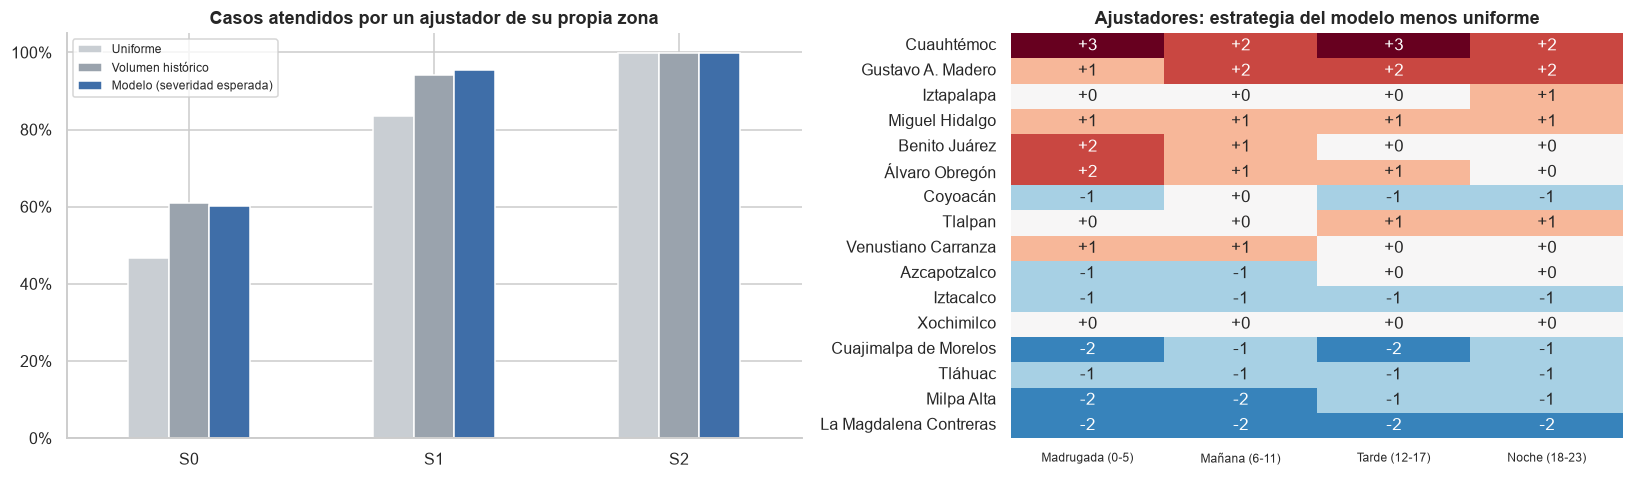

La estrategia del modelo reduce la carga ponderada por severidad atendida fuera de zona en 35.9% frente a la uniforme.


In [40]:
F_val_eda = sf.construir_features(raw_val)
ALC = list(sf.ALCALDIAS.values())

def pesos_planeacion(valores):
    return (pd.DataFrame({"ALCALDIA": F_val_eda["ALCALDIA"].values, "FRANJA": F_val_eda["FRANJA"].values, "v": valores})
            .query("FRANJA in @sf.FRANJAS").groupby(["FRANJA", "ALCALDIA"])["v"].sum().unstack().reindex(index=sf.FRANJAS, columns=ALC).fillna(0))

ESTRATEGIAS = {"Uniforme": pd.DataFrame(1.0, index=sf.FRANJAS, columns=ALC),
               "Volumen histórico": pesos_planeacion(np.ones(len(F_val_eda))),
               "Modelo (severidad esperada)": pesos_planeacion(P_val_cal @ PESO_SEVERIDAD)}

def repartir(pesos_fila, total, minimo):
    """Reparto por residuo mayor con un mínimo de ajustadores por alcaldía."""
    base = np.full(len(pesos_fila), minimo)
    restante = total - base.sum()
    cuota = pesos_fila / pesos_fila.sum() * restante
    asignado = np.floor(cuota).astype(int)
    faltan = restante - asignado.sum()
    asignado[np.argsort(-(cuota - asignado))[:faltan]] += 1
    return base + asignado

asignacion = {n: pd.DataFrame([repartir(p.loc[f].to_numpy(), SIM_AJUSTADORES_POR_FRANJA, SIM_MINIMO_POR_ALCALDIA) for f in sf.FRANJAS],
                              index=sf.FRANJAS, columns=ALC) for n, p in ESTRATEGIAS.items()}

# Demanda 2025: tasa diaria por alcaldía, franja y clase, escalada al volumen de la aseguradora
dem = (pd.DataFrame({"ALCALDIA": F_test["ALCALDIA"].values, "FRANJA": F_test["FRANJA"].values, "y": y_test})
       .query("FRANJA in @sf.FRANJAS").groupby(["FRANJA", "ALCALDIA", "y"]).size()
       .unstack(fill_value=0).reindex(columns=[0, 1, 2], fill_value=0))
dem = dem.reindex(pd.MultiIndex.from_product([sf.FRANJAS, ALC], names=["FRANJA", "ALCALDIA"]), fill_value=0)
lam = dem.to_numpy() / dem.to_numpy().sum() * SIM_VOLUMEN_DIARIO           # (celdas, 3)

rng_sim = np.random.default_rng(SEED)
N = rng_sim.poisson(lam[None, :, :], size=(SIM_DIAS, *lam.shape))         # (días, celdas, clases)
filas_sim = []
for nombre, a in asignacion.items():
    cap = (a.stack().reindex(dem.index).to_numpy() * SIM_CASOS_POR_AJUSTADOR)[None, :]
    atendidos2 = np.minimum(N[..., 2], cap)
    atendidos1 = np.minimum(N[..., 1], cap - atendidos2)
    atendidos0 = np.minimum(N[..., 0], cap - atendidos2 - atendidos1)
    local = np.stack([atendidos0, atendidos1, atendidos2], axis=-1).sum(axis=(0, 1))
    total = N.sum(axis=(0, 1))
    utilizacion = (N.sum(axis=-1) / cap).mean(axis=0)
    fuera = total - local
    filas_sim.append({"estrategia": nombre, **{f"{c} atendidos en su zona": local[i] / total[i] for i, c in enumerate(CLASES)},
                      "casos atendidos desde otra zona por día": fuera.sum() / SIM_DIAS,
                      "carga ponderada fuera de zona por día": (fuera * PESO_SEVERIDAD).sum() / SIM_DIAS,
                      "desbalance de utilización (desv. est.)": utilizacion.std()})
sim = pd.DataFrame(filas_sim).set_index("estrategia")
display(sim.style.format({**{f"{c} atendidos en su zona": "{:.1%}" for c in CLASES}}, precision=2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
sim[[f"{c} atendidos en su zona" for c in CLASES]].rename(columns=lambda c: c[:2]).T.plot(kind="bar", ax=axes[0], rot=0,
    color=["#C9CED3", "#9AA3AD", "#3F6EA8"])
formato_pct(axes[0]); axes[0].set_ylim(0, 1.05); axes[0].set_title("Casos atendidos por un ajustador de su propia zona")
axes[0].legend(fontsize=8)
sns.heatmap(asignacion["Modelo (severidad esperada)"].T.loc[alc.index] - asignacion["Uniforme"].T.loc[alc.index], annot=True, fmt="+d",
            cmap="RdBu_r", center=0, ax=axes[1], cbar=False)
axes[1].set_title("Ajustadores: estrategia del modelo menos uniforme"); axes[1].set_ylabel(""); axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); guardar(fig, "09_2_simulacion_ajustadores"); plt.show()

mejora = 1 - sim.loc["Modelo (severidad esperada)", "carga ponderada fuera de zona por día"] / sim.loc["Uniforme", "carga ponderada fuera de zona por día"]
print(f"La estrategia del modelo reduce la carga ponderada por severidad atendida fuera de zona en {mejora:.1%} frente a la uniforme.")

## 10. Valor de negocio y proyecciones de impacto económico (sección 13)

Beneficio anual = ahorro por eficiencia + ahorro por reasignaciones + costo evitado por errores críticos − costo anual de la solución. Todas las cifras son parámetros de la sección 1 y **no representan costos reales** de una aseguradora; el ejemplo de MXN 20 millones sólo muestra la mecánica del cálculo.

,mejora de eficiencia,ahorro por eficiencia (MXN),ahorro por reasignaciones (MXN),costo evitado por errores (MXN),beneficio neto (MXN),ROI
escenario,,,,,,
Conservador,3%,"600,000",0,0,"100,000",20%
Base,5%,"1,000,000",0,0,"500,000",100%
Alto,8%,"1,600,000",0,0,"1,100,000",220%


Costo relativo de priorización: modelo 0.739 vs aleatorio con la misma capacidad 1.851 por caso.
Con 91,250 siniestros al año se evitarían 101,510 unidades de costo relativo.
Define COSTO_UNIDAD_ERROR_MXN con la aseguradora para convertir esas unidades en pesos.


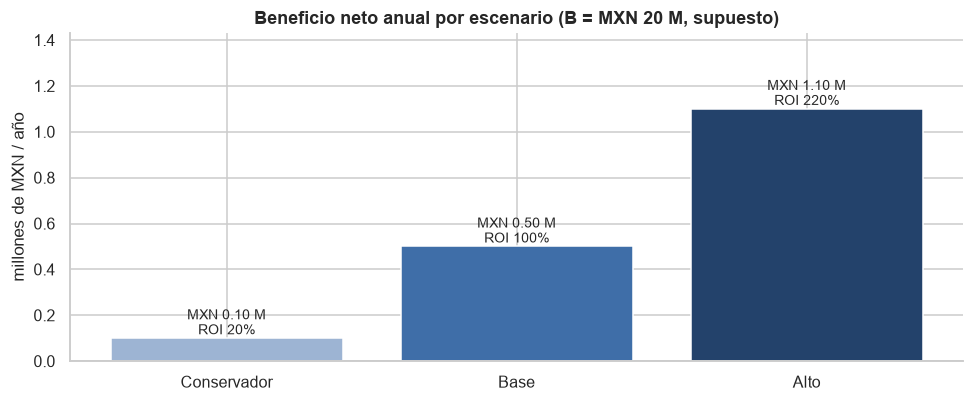

In [41]:
volumen_anual = SIM_VOLUMEN_DIARIO * 365
unidades_evitadas = (costo_aleatorio - costo_modelo) * volumen_anual
ahorro_errores = unidades_evitadas * COSTO_UNIDAD_ERROR_MXN if COSTO_UNIDAD_ERROR_MXN else 0.0
ahorro_reasignaciones = REASIGNACIONES_EVITADAS * COSTO_REASIGNACION

escenarios = []
for nombre, e in ESCENARIOS_EFICIENCIA.items():
    ahorro_eficiencia = COSTO_BASE_B * e
    bruto = ahorro_eficiencia + ahorro_reasignaciones + ahorro_errores
    escenarios.append({"escenario": nombre, "mejora de eficiencia": e, "ahorro por eficiencia (MXN)": ahorro_eficiencia,
                       "ahorro por reasignaciones (MXN)": ahorro_reasignaciones, "costo evitado por errores (MXN)": ahorro_errores,
                       "beneficio neto (MXN)": bruto - COSTO_ANUAL_SOLUCION,
                       "ROI": (bruto - COSTO_ANUAL_SOLUCION) / COSTO_ANUAL_SOLUCION})
escenarios = pd.DataFrame(escenarios).set_index("escenario")
display(escenarios.style.format({"mejora de eficiencia": "{:.0%}", "ROI": "{:.0%}"} | {c: "{:,.0f}" for c in escenarios.columns if "MXN" in c}))

print(f"Costo relativo de priorización: modelo {costo_modelo:.3f} vs aleatorio con la misma capacidad {costo_aleatorio:.3f} por caso.")
print(f"Con {volumen_anual:,} siniestros al año se evitarían {unidades_evitadas:,.0f} unidades de costo relativo.")
if not COSTO_UNIDAD_ERROR_MXN:
    print("Define COSTO_UNIDAD_ERROR_MXN con la aseguradora para convertir esas unidades en pesos.")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(escenarios.index, escenarios["beneficio neto (MXN)"] / 1e6, color=["#9DB4D3", "#3F6EA8", "#23426B"])
for i, (b, r) in enumerate(zip(escenarios["beneficio neto (MXN)"], escenarios["ROI"])):
    ax.text(i, b / 1e6, f"MXN {b / 1e6:.2f} M\nROI {r:.0%}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("millones de MXN / año"); ax.set_title(f"Beneficio neto anual por escenario (B = MXN {COSTO_BASE_B / 1e6:.0f} M, supuesto)")
ax.set_ylim(0, escenarios["beneficio neto (MXN)"].max() / 1e6 * 1.3)
plt.tight_layout(); guardar(fig, "10_valor_negocio"); plt.show()

## 11. Despliegue del MVP (Flask + ngrok)

Se serializa el champion (clasificador + calibrador + umbrales) en `artefactos/modelo_champion.pkl` y se escribe una API Flask que:

1. recibe los campos del primer aviso en JSON,
2. los valida,
3. aplica el mismo pipeline del entrenamiento,
4. devuelve P(S0), P(S1), P(S2), el score y la prioridad, y
5. registra cada predicción en `artefactos/predicciones_log.csv` para compararla después con el resultado real.

In [42]:
modelo_final = sf.ModeloSeveridad(clf_champion, calibrador, UMBRALES, metadatos={
    "modelo": CHAMPION[1], "ventana_entrenamiento": NOMBRE_VENTANA[CHAMPION[0]],
    "anio_validacion": ANIO_VAL, "anio_prueba": ANIO_TEST, "entrenado": time.strftime("%Y-%m-%d %H:%M"),
    "variables": sf.FEATURES_CAT + sf.FEATURES_NUM, "umbrales": UMBRALES, "capacidad_alta": CAPACIDAD_ALTA,
    "metricas_prueba": {k: float(v) for k, v in tabla_test.loc[ETIQUETA[CHAMPION]].items() if pd.notna(v)},
    "versiones": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__},
})
ruta_modelo = DIR_ART / "modelo_champion.pkl"
joblib.dump(modelo_final, ruta_modelo)
print(f"Modelo guardado en {ruta_modelo} ({ruta_modelo.stat().st_size / 1024:.0f} KB)")

# Verificación: el objeto guardado reproduce las predicciones del notebook
recargado = joblib.load(ruta_modelo)
assert np.allclose(recargado.probabilidades(raw_test.head(200)), P_test_cal[:200])

# Latencia de inferencia de un solo reporte
un_reporte = raw_test.head(1)
t0 = time.perf_counter()
for _ in range(100):
    recargado.predecir(un_reporte)
print(f"Latencia promedio por reporte: {(time.perf_counter() - t0) / 100 * 1000:.1f} ms")

Modelo guardado en artefactos/modelo_champion.pkl (1331 KB)
Latencia promedio por reporte: 8.9 ms


In [43]:
%%writefile artefactos/api_severidad.py
"""API de triage de severidad (MVP). Ejecutar: python api_severidad.py  ->  http://localhost:5000"""
import csv
import json
import time
from pathlib import Path

import joblib
from flask import Flask, jsonify, request

import severidad_features as sf

DIR = Path(__file__).resolve().parent
MODELO = joblib.load(DIR / "modelo_champion.pkl")
LOG = DIR / "predicciones_log.csv"
app = Flask(__name__)

FORMULARIO = """<!doctype html><meta charset="utf-8"><title>Triage de severidad</title>
<style>body{font-family:system-ui;max-width:560px;margin:2rem auto;padding:0 1rem}label{display:block;margin:.5rem 0}
input,select{width:100%;padding:.35rem}button{margin-top:1rem;padding:.5rem 1rem}pre{background:#f4f4f4;padding:1rem}</style>
<h2>Primer aviso de siniestro</h2><form id="f">
<label>Alcaldía<select name="ALCALDIA">{alcaldias}</select></label>
<label>Tipo de accidente<select name="TIPACCID">{tipos}</select></label>
<label>Ubicación<select name="URBANA"><option>Intersección</option><option>No intersección</option></select></label>
<label>Día<select name="DIASEMANA">{dias}</select></label>
<label>Mes (1-12)<input name="MES" type="number" min="1" max="12" value="1"></label>
<label>Hora (0-23)<input name="ID_HORA" type="number" min="0" max="23" value="12"></label>
<label>Automóviles<input name="AUTOMOVIL" type="number" min="0" max="9" value="1"></label>
<label>Motocicletas<input name="MOTOCICLET" type="number" min="0" max="9" value="0"></label>
<label>Bicicletas<input name="BICICLETA" type="number" min="0" max="9" value="0"></label>
<label>Camiones de carga<input name="CAMION" type="number" min="0" max="9" value="0"></label>
<button>Calcular prioridad</button></form><pre id="r"></pre>
<script>document.getElementById('f').onsubmit=async e=>{e.preventDefault();
const d=Object.fromEntries(new FormData(e.target));const r=await fetch('/predecir',{method:'POST',
headers:{'Content-Type':'application/json'},body:JSON.stringify(d)});
document.getElementById('r').textContent=JSON.stringify(await r.json(),null,2)}</script>"""


def _opciones(valores):
    return "".join(f"<option>{v}</option>" for v in valores)


@app.get("/")
def formulario():
    return FORMULARIO.format(alcaldias=_opciones(sf.ALCALDIAS.values()), tipos=_opciones(sf.TIPOS_ACCIDENTE), dias=_opciones(sf.DIAS))


@app.get("/salud")
def salud():
    return jsonify({"estado": "ok", "modelo": MODELO.metadatos.get("modelo"),
                    "ventana": MODELO.metadatos.get("ventana_entrenamiento"), "entrenado": MODELO.metadatos.get("entrenado")})


@app.post("/predecir")
def predecir():
    t0 = time.perf_counter()
    entrada = request.get_json(silent=True)
    if entrada is None:
        return jsonify({"error": "El cuerpo debe ser JSON"}), 400
    datos, errores = sf.validar_reporte(entrada)
    if errores:
        return jsonify({"errores": errores}), 422
    salida = MODELO.predecir(datos).round(4)
    respuesta = [{"P_S0": r.P_S0, "P_S1": r.P_S1, "P_S2": r.P_S2, "score": r.SCORE,
                  "prioridad": r.PRIORIDAD, "clase_probable": r.CLASE_PROBABLE} for r in salida.itertuples()]
    ms = (time.perf_counter() - t0) * 1000
    nuevo = not LOG.exists()
    with LOG.open("a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if nuevo:
            w.writerow(["timestamp", "entrada", "salida", "ms"])
        for e, s in zip(datos.to_dict("records"), respuesta):
            w.writerow([time.strftime("%Y-%m-%d %H:%M:%S"), json.dumps(e, ensure_ascii=False), json.dumps(s), f"{ms:.1f}"])
    return jsonify(respuesta[0] if isinstance(entrada, dict) else respuesta)


if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

Writing artefactos/api_severidad.py


In [44]:
import api_severidad
importlib.reload(api_severidad)
cliente = api_severidad.app.test_client()

ejemplos = [
    {"ALCALDIA": "Iztapalapa", "TIPACCID": "Colisión con peatón (atropellamiento)", "URBANA": "No intersección",
     "DIASEMANA": "Domingo", "MES": 12, "ID_HORA": 2, "AUTOMOVIL": 1},
    {"ALCALDIA": "09014", "TIPACCID": "Colisión con vehículo automotor", "URBANA": "Intersección",
     "DIASEMANA": "Martes", "MES": 3, "ID_HORA": 13, "AUTOMOVIL": 2},
    {"ALCALDIA": "Gustavo A. Madero", "TIPACCID": "Colisión con motocicleta", "URBANA": "Intersección",
     "DIASEMANA": "Sábado", "MES": 7, "ID_HORA": 22, "AUTOMOVIL": 1, "MOTOCICLET": 1},
]
for ej in ejemplos:
    r = cliente.post("/predecir", json=ej)
    print(r.status_code, ej["ALCALDIA"], "|", ej["TIPACCID"], "->", r.get_json())

r = cliente.post("/predecir", json={"ALCALDIA": "Narnia", "MES": 13})
print("\nReporte inválido ->", r.status_code, r.get_json())
print("Salud ->", cliente.get("/salud").get_json())

200 Iztapalapa | Colisión con peatón (atropellamiento) -> {'P_S0': 0.0098, 'P_S1': 0.7232, 'P_S2': 0.267, 'clase_probable': 'S2', 'prioridad': 'Alta', 'score': 62.8595}
200 09014 | Colisión con vehículo automotor -> {'P_S0': 0.9107, 'P_S1': 0.084, 'P_S2': 0.0053, 'clase_probable': 'S0', 'prioridad': 'Baja', 'score': 4.7285}
200 Gustavo A. Madero | Colisión con motocicleta -> {'P_S0': 0.3685, 'P_S1': 0.5699, 'P_S2': 0.0616, 'clase_probable': 'S1', 'prioridad': 'Media', 'score': 34.656}

Reporte inválido -> 422 {'errores': [{'errores': ['Faltan campos: DIASEMANA, ID_HORA, TIPACCID, URBANA'], 'registro': 0}]}
Salud -> {'entrenado': '2026-09-28 19:15', 'estado': 'ok', 'modelo': 'XGBoost', 'ventana': 'B: 2022-2023 (pospandemia)'}


### 11.1 Publicar la API con ngrok

Desde una terminal, en la carpeta `artefactos/`:

```bash
python api_severidad.py          # API en http://localhost:5000 (formulario en /, JSON en /predecir)
ngrok http 5000                  # en otra terminal; ngrok imprime la URL pública
```

O desde el notebook con `pyngrok` (necesitas un token gratuito de ngrok):

In [45]:
USAR_NGROK = False   # Cambia a True para publicar la API desde el notebook
if USAR_NGROK:
    # %pip install pyngrok
    import threading
    from pyngrok import ngrok
    ngrok.set_auth_token("TU_TOKEN_DE_NGROK")
    threading.Thread(target=lambda: api_severidad.app.run(port=5000, use_reloader=False), daemon=True).start()
    print("URL pública:", ngrok.connect(5000).public_url)

## 12. Resumen de resultados

La siguiente celda reúne las cifras clave para el reporte escrito. Todas se calculan en este notebook, así que se actualizan si cambian los parámetros o los datos.

In [46]:
resumen = {
    "Datos": {"accidentes CDMX 2019-2025": len(base), "% S0/S1/S2": " / ".join(f"{(base['SEVERIDAD'] == c).mean():.1%}" for c in CLASES),
              "registros excluidos": int(df["EXCLUIR"].sum())},
    "Champion": {"modelo": CHAMPION[1], "ventana": NOMBRE_VENTANA[CHAMPION[0]], "umbrales": {k: round(v, 3) for k, v in UMBRALES.items()}},
    "Prueba 2025": {m: round(float(tabla_test.loc[ETIQUETA[CHAMPION], m]), 4) for m in ["Macro F1", "Recall S1", "Recall S2", "Precision S2", "PR-AUC S2", "ROC-AUC víctimas"]},
    "Hipótesis": {"H0 rechazada (hay señal)": bool(rechaza_h0), "Macro F1 vs baseline": texto_ic(dif_f1_h0),
                  "H0_modelo rechazada (XGBoost mejor)": bool(rechaza_h0_modelo), "Macro F1 XGBoost − LogReg": texto_ic(dif_f1_modelo),
                  "Reducción de costo por caso LogReg − XGBoost": texto_ic(dif_costo_modelo),
                  "Macro F1 ventana A − B (2025)": texto_ic(dif_covid)},
    "Operación 2025": {"S2 en prioridad alta": f"{kpis_prio.loc['S2 en prioridad alta', 'Modelo']:.1%}",
                       "S1/S2 subpriorizados": f"{kpis_prio.loc['S1/S2 subpriorizados (baja)', 'Modelo']:.1%}",
                       "% de casos en alta": f"{reparto[2]:.1%}",
                       "costo relativo vs aleatorio": f"{costo_modelo:.3f} vs {costo_aleatorio:.3f}",
                       "reducción de carga ponderada fuera de zona": f"{mejora:.1%}"},
}
print(json.dumps(resumen, ensure_ascii=False, indent=2, default=str))
(DIR_ART / "resumen_resultados.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"\nFiguras guardadas en {DIR_FIG.resolve()} ({len(list(DIR_FIG.glob('*.png')))} archivos)")

{
  "Datos": {
    "accidentes CDMX 2019-2025": 50767,
    "% S0/S1/S2": "73.4% / 23.4% / 3.1%",
    "registros excluidos": 1
  },
  "Champion": {
    "modelo": "XGBoost",
    "ventana": "B: 2022-2023 (pospandemia)",
    "umbrales": {
      "p_s2_alta": 0.14,
      "score_alta": 50.241,
      "score_media": 10.754
    }
  },
  "Prueba 2025": {
    "Macro F1": 0.5684,
    "Recall S1": 0.5498,
    "Recall S2": 0.4864,
    "Precision S2": 0.1761,
    "PR-AUC S2": 0.1922,
    "ROC-AUC víctimas": 0.8996
  },
  "Hipótesis": {
    "H0 rechazada (hay señal)": true,
    "Macro F1 vs baseline": "+0.2404 [+0.2197, +0.2593]",
    "H0_modelo rechazada (XGBoost mejor)": true,
    "Macro F1 XGBoost − LogReg": "+0.0283 [+0.0162, +0.0398]",
    "Reducción de costo por caso LogReg − XGBoost": "+0.0277 [+0.0007, +0.0534]",
    "Macro F1 ventana A − B (2025)": "-0.0037 [-0.0150, +0.0081]"
  },
  "Operación 2025": {
    "S2 en prioridad alta": "57.2%",
    "S1/S2 subpriorizados": "15.6%",
    "% de casos e

### Limitaciones que deben acompañar la lectura de resultados

- **Cobertura:** ATUS en CDMX proviene de Agencias del Ministerio Público y Juzgados Cívicos; representa accidentes registrados, no el universo de siniestros de una aseguradora. En producción el modelo debe recalibrarse con el FNOL del cliente.
- **Mortalidad en el lugar:** S2 no incluye fallecimientos posteriores al evento.
- **Cambio en la mezcla de clases:** la proporción con víctimas crece de 2019 a 2025. La recalibración con 2024 corrige parte de ese desplazamiento, pero debe revisarse cada vez que se publique un año nuevo.
- **Tipo de accidente:** atropellamientos, caídas de pasajero y colisiones con ciclista casi siempre implican víctimas por definición. Su peso en el modelo es legítimo en el primer aviso, pero reduce la dificultad del problema.
- **Simulación de ajustadores:** mide cobertura local sin distancias reales. Una versión posterior requiere coordenadas y tiempos de traslado.
- **Valor económico:** los montos son supuestos para mostrar la mecánica del cálculo; deben sustituirse por los costos del cliente en un piloto.